# Pindar Risk Atlas: Risiko Gagal Bayar Pinjol Antarprovinsi

Notebook tunggal dari akuisisi data sampai clustering provinsi. Pertanyaan yang dijawab: provinsi mana yang mirip dalam profil risiko pinjaman online berizin (TWP90), dan faktor apa yang berasosiasi dengan perbedaannya.

| Bagian | Isi | Status |
|---|---|---|
| 0 | Setup dan saklar | selesai |
| A | Akuisisi data mentah | selesai |
| B | Wrangling dan master panel | selesai |
| C | Audit dan EDA | selesai |
| D | Seleksi fitur dan korelasi | selesai |
| E | Clustering | selesai |
| F | Interpretasi dan batasan | selesai |
| G | Ekspor | selesai |
| H | Validasi independen dan forensik | selesai |
| I | Uji H1 dan regresi panel | selesai |
| J | Peta risiko provinsi | selesai |

**Cara menjalankan.** Default `RUN_ACQUISITION = False`: seluruh bagian A membaca file yang sudah ada di `data/raw/` dan tidak menyentuh jaringan. Set `RUN_ACQUISITION = True` hanya untuk mengambil file yang hilang; `FORCE_REFRESH = True` mengunduh ulang semuanya. Jalankan dengan Run All di kernel baru.

## Alur notebook dari awal sampai akhir

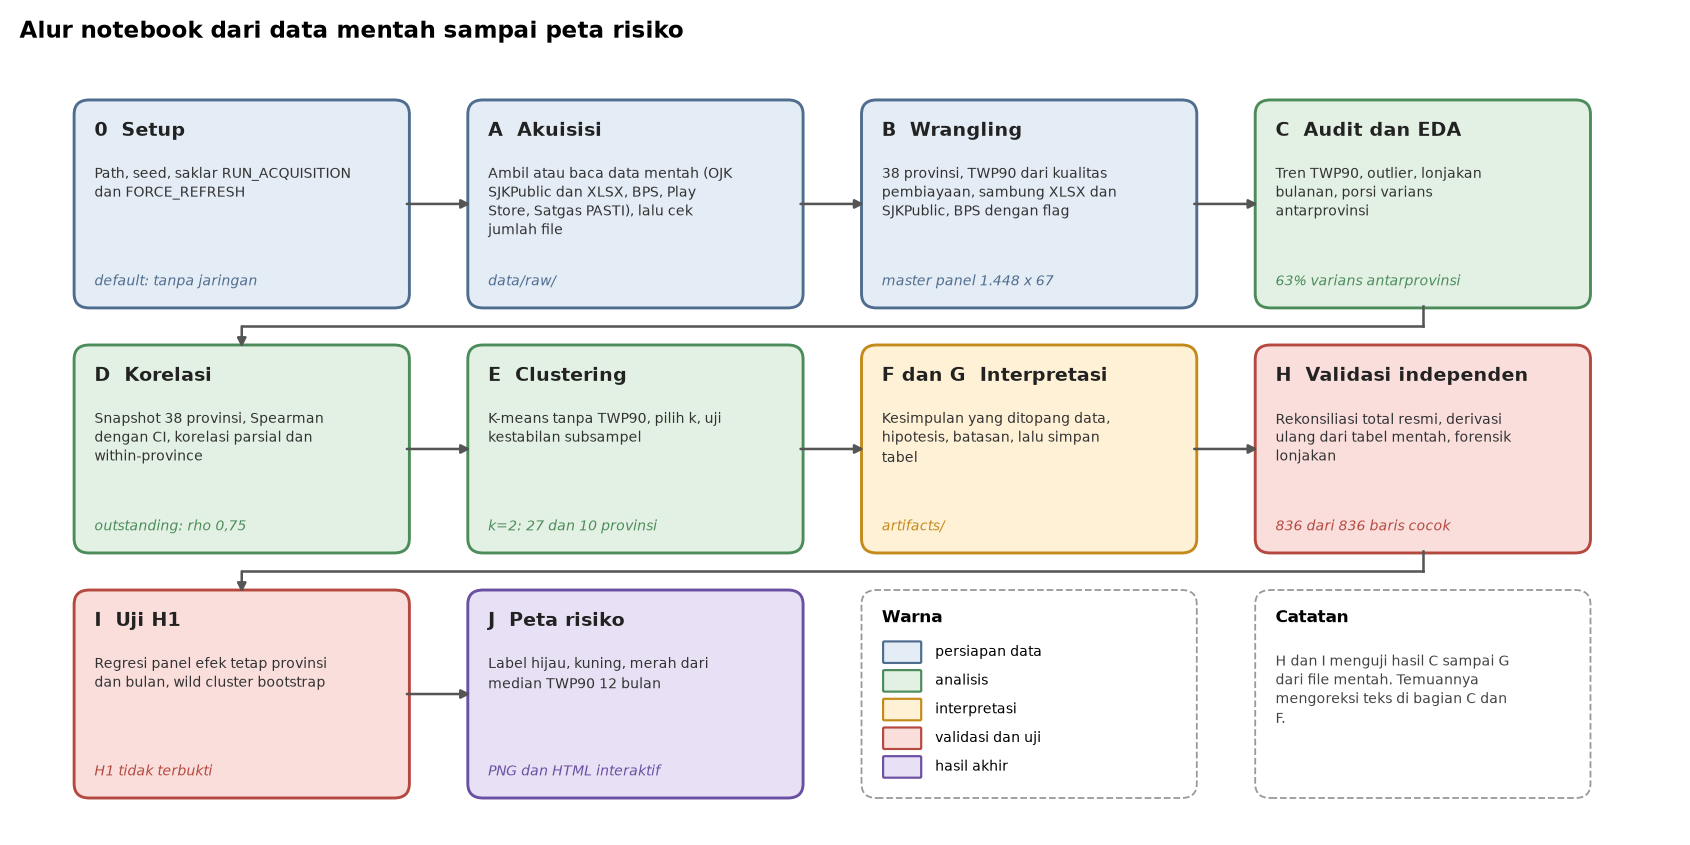

Setiap kotak adalah satu bagian notebook (huruf yang sama dengan judul bagian di bawah). Teks miring di kaki kotak adalah hasil kunci bagian itu. Bagian H dan I tidak menambah data baru, tetapi menguji bagian C sampai G dari file mentah dan mengoreksi teks yang keliru.

In [1]:
# Cell 1 - Environment setup, directory contract, and acquisition switches
from pathlib import Path
from urllib.parse import quote_plus, urlparse
from concurrent.futures import ThreadPoolExecutor, as_completed
import itertools
import json
import platform
import random
import re
import time
import numpy as np
import pandas as pd
import openpyxl

SEED = 42
RUN_ACQUISITION = False
FORCE_REFRESH = False
random.seed(SEED)
np.random.seed(SEED)

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
assert (PROJECT_ROOT / "README.md").exists(), f"Repository root not found from {cwd}"

DIRS = {
    "raw_ojk_xlsx": PROJECT_ROOT / "data" / "raw" / "ojk_xlsx",
    "raw_ojk_sjkpublic": PROJECT_ROOT / "data" / "raw" / "ojk_sjkpublic",
    "raw_ojk_directory": PROJECT_ROOT / "data" / "raw" / "ojk_directory",
    "raw_bps": PROJECT_ROOT / "data" / "raw" / "bps",
    "raw_playstore": PROJECT_ROOT / "data" / "raw" / "playstore",
    "clean": PROJECT_ROOT / "data" / "clean",
    "artifacts": PROJECT_ROOT / "artifacts",
}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)


class OfflineSession:
    def __getattr__(self, name):
        raise RuntimeError(f"network call '{name}' blocked: set RUN_ACQUISITION = True to fetch missing raw files")


if RUN_ACQUISITION:
    import curl_cffi
    import pdfplumber
    import requests as std_requests
    from bs4 import BeautifulSoup
    from curl_cffi import requests
    from google_play_scraper import app as gp_app, reviews as gp_reviews, Sort
    from requests.adapters import HTTPAdapter
    from urllib3.util.retry import Retry

    http_sess = std_requests.Session()
    retries = Retry(total=4, connect=4, read=4, backoff_factor=1.0, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET", "POST"])
    http_sess.mount("https://", HTTPAdapter(max_retries=retries))
    http_sess.headers.update({
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36"
    })
else:
    http_sess = OfflineSession()

print(
    f"step=env_setup | python={platform.python_version()} | pandas={pd.__version__} | "
    f"openpyxl={openpyxl.__version__} | seed={SEED}"
)
print(f"run_acquisition={RUN_ACQUISITION} | force_refresh={FORCE_REFRESH} | project_root={PROJECT_ROOT.name} | dirs_ready={len(DIRS)}")


step=env_setup | python=3.14.6 | pandas=3.0.3 | openpyxl=3.1.5 | seed=42
run_acquisition=False | force_refresh=False | project_root=pindar-risk-atlas | dirs_ready=7


## A. Akuisisi data mentah

| Sumber | Isi | Cakupan | Folder |
|---|---|---|---|
| OJK SJKPublic | 18 tabel LPBBTI per provinsi (konvensional + syariah) | 2024-07 sampai 2026-04 | `ojk_sjkpublic` |
| OJK XLSX historis | 18 workbook statistik LPBBTI (sheet 9, per provinsi) | 2022 sampai 2025 | `ojk_xlsx` |
| OJK Direktori | 94 platform berizin (PDF Mei 2026) | snapshot | `ojk_directory` |
| BPS | 10 tabel sosial-ekonomi provinsi + UMP Refnusa | 2023 sampai 2026 (beda per indikator) | `bps` |
| Play Store | aplikasi dan ulasan platform berizin | ulasan terbaru saja | `playstore` |
| Satgas PASTI | daftar pinjol ilegal (PDF) dan siaran pers | Okt 2026, 2025 | `playstore` |

Setiap sel akuisisi memakai file lokal jika ada. Sel hanya meminta jaringan saat file hilang, dan saat `RUN_ACQUISITION = False` permintaan itu berhenti dengan pesan yang jelas.

### A.1 Katalog OJK
Menemukan halaman statistik historis OJK dan metrik SJKPublic. Hanya berjalan saat `RUN_ACQUISITION = True`.

In [2]:
# Cell 2 - OJK LPBBTI catalog discovery (historical pages and SJKPublic metrics)
if RUN_ACQUISITION:
    session = requests.Session(impersonate="chrome")

    # 1. Discover historical monthly OJK Statistik LPBBTI pages across SharePoint pager pages 1..5
    base_ojk = "https://ojk.go.id"
    old_url = f"{base_ojk}/id/kanal/iknb/data-dan-statistik/fintech/olddefault.aspx"
    r0 = session.get(old_url, timeout=30)
    r0.raise_for_status()

    def parse_ojk_page(html_text):
        soup = BeautifulSoup(html_text, "lxml")
        rows = []
        for a in soup.find_all("a", href=True):
            href = a["href"]
            title = a.get_text(strip=True)
            if "statistik-lpbbti" in href.lower() and href.lower().endswith(".aspx"):
                full_url = href if href.startswith("http") else base_ojk + href
                rows.append((title, full_url))
        return soup, rows

    soup, first_rows = parse_ojk_page(r0.text)
    historical_pages = list(dict.fromkeys(first_rows))

    for target_page in range(2, 6):
        pager_link = None
        for a in soup.find_all("a", href=True):
            if a.get_text(strip=True) == str(target_page) and "DataPagerArticles" in a["href"]:
                pager_link = a["href"]
                break
        if not pager_link:
            break
        m = re.search(r"__doPostBack\('([^']+)','([^']*)'\)", pager_link)
        if not m:
            break
        payload = {inp.get("name"): inp.get("value", "") for inp in soup.find_all("input") if inp.get("name")}
        payload["__EVENTTARGET"] = m.group(1)
        payload["__EVENTARGUMENT"] = m.group(2)
        rp = session.post(old_url, data=payload, timeout=30)
        rp.raise_for_status()
        soup, next_rows = parse_ojk_page(rp.text)
        for item in next_rows:
            if item not in historical_pages:
                historical_pages.append(item)

    df_ojk_hist = pd.DataFrame(historical_pages, columns=["title", "page_url"])
    print(f"ojk_historical_pages={len(df_ojk_hist)}")
    print(df_ojk_hist.head(5).to_string(index=False))
    print(df_ojk_hist.tail(5).to_string(index=False))

    # 2. Discover OJK SJKPublic LPBBTI Konvensional (18) and Syariah (42) dataset metrics
    sjk_base = "https://data.ojk.go.id/SJKPublic/Dataset/Dataset"
    session.get(sjk_base, timeout=30).raise_for_status()
    sjk_rows = []
    for ind_id, ind_label in [(18, "LPBBTI_Konvensional"), (42, "LPBBTI_Syariah")]:
        info_resp = session.get(f"{sjk_base}/GetInformasiData", params={"industriId": ind_id}, timeout=30).json()
        for info in info_resp.get("data", []):
            m_resp = session.get(
                f"{sjk_base}/GetMetricData",
                params={"informasiId": info["InformasiID"]},
                timeout=30,
            ).json()
            for m in m_resp.get("data", []):
                sjk_rows.append({
                    "industri_id": ind_id,
                    "industri": ind_label,
                    "informasi_id": info["InformasiID"],
                    "informasi": info["InformasiName"],
                    "metric_id": m["MetricID"],
                    "metric_name": m["MetricName"],
                })

    df_sjk_catalog = pd.DataFrame(sjk_rows)
    print(f"sjkpublic_metrics_count={len(df_sjk_catalog)}")
    print(df_sjk_catalog[["industri", "informasi", "metric_id", "metric_name"]].to_string(index=False))
else:
    df_ojk_hist = pd.DataFrame(columns=["title", "page_url"])
    df_sjk_catalog = pd.DataFrame()
    print("step=catalog_discovery | skipped=run_acquisition_false")


step=catalog_discovery | skipped=run_acquisition_false


### A.2 Tabel SJKPublic
Unduh 18 tabel provinsi (TWP90, peminjam, pemberi, rekening, kualitas pembiayaan, dan lainnya) beserta berkas pemetaan metrik.

In [3]:
# Cell 3 - Extract OJK SJKPublic LPBBTI datasets and Mapping Statistik LPBBTI.xlsx
TARGET_METRICS = [
    (144, "konv_twp90_dati1"),
    (312, "syar_twp90_dati1"),
    (411, "konv_borrower_dati1"),
    (427, "syar_borrower_dati1"),
    (1453, "konv_borrower_kualitas_dati1"),
    (1454, "syar_borrower_kualitas_dati1"),
    (407, "konv_lender_dati1"),
    (423, "syar_lender_dati1"),
    (414, "konv_borrower_usia"),
    (430, "syar_borrower_usia"),
    (415, "konv_borrower_sektor"),
    (431, "syar_borrower_sektor"),
    (417, "konv_rekening_dati1"),
    (433, "syar_rekening_dati1"),
    (384, "konv_rasio_keuangan"),
    (316, "syar_rasio_keuangan"),
    (444, "konv_twp90_gender"),
    (445, "syar_twp90_gender"),
]

# Download Mapping Statistik LPBBTI.xlsx reference document
mapping_url = "https://ojk.go.id/id/kanal/iknb/data-dan-statistik/fintech/Documents/Mapping%20Statistik%20LPBBTI.xlsx"
mapping_path = DIRS["raw_ojk_sjkpublic"] / "Mapping_Statistik_LPBBTI.xlsx"
if FORCE_REFRESH or not (mapping_path.exists() and mapping_path.stat().st_size > 1000):
    r_map = http_sess.get(mapping_url, timeout=60)
    r_map.raise_for_status()
    mapping_path.write_bytes(r_map.content)
print(f"mapping_file={mapping_path.name} | bytes={mapping_path.stat().st_size}")

sjk_base = "https://data.ojk.go.id/SJKPublic/Dataset/Dataset"
sjk_cached = {mid: sorted(DIRS["raw_ojk_sjkpublic"].glob(f"{mid}_{slug}_*.csv")) for mid, slug in TARGET_METRICS}
need_sjk_fetch = FORCE_REFRESH or any(not v for v in sjk_cached.values())
xsrf_token = None
if need_sjk_fetch:
    r_home = http_sess.get(sjk_base, timeout=30)
    r_home.raise_for_status()
    xsrf_token = BeautifulSoup(r_home.text, "lxml").find("input", {"name": "__RequestVerificationToken"})["value"]
print(f"step=sjk_cache_check | cached_tables={sum(bool(v) for v in sjk_cached.values())}/{len(TARGET_METRICS)} | fetch_needed={need_sjk_fetch}")

sjk_summary = []
for metric_id, slug in TARGET_METRICS:
    cached_matches = sorted(DIRS["raw_ojk_sjkpublic"].glob(f"{metric_id}_{slug}_*.csv"))
    if not FORCE_REFRESH and cached_matches:
        out_csv = cached_matches[0]
        nama_table = out_csv.stem.replace(f"{metric_id}_{slug}_", "", 1)
        df_tmp = pd.read_csv(out_csv)
        bulan_vals = sorted(df_tmp["Bulan"].dropna().astype(str).unique()) if "Bulan" in df_tmp.columns else []
        n_prov = df_tmp["NamaDATI1"].nunique() if "NamaDATI1" in df_tmp.columns else 0
        sjk_summary.append({
            "metric_id": metric_id, "slug": slug, "nama_table": nama_table,
            "rows": len(df_tmp), "cols": len(df_tmp.columns),
            "bulan_min": bulan_vals[0] if bulan_vals else "NONE",
            "bulan_max": bulan_vals[-1] if bulan_vals else "NONE",
            "n_months": len(bulan_vals), "n_prov": n_prov,
        })
        continue
    gm = http_sess.get(f"{sjk_base}/GetGridMeasure", params={"refMetricId": metric_id}, timeout=30).json()
    measures = ",".join([item["name"] for item in gm.get("data", [])])

    r_save = http_sess.post(
        f"{sjk_base}/SaveMeasures",
        headers={"XSRF-TOKEN": xsrf_token},
        data={"measures": measures, "id": metric_id},
        timeout=30,
    )
    r_save.raise_for_status()

    r_ds = http_sess.get(f"{sjk_base}/Dataset/{metric_id}", timeout=30)
    r_ds.raise_for_status()
    m_table = re.search(r'"namaTable"\s*:\s*"([^"]+)"', r_ds.text)
    assert m_table, f"namaTable not found for metric_id={metric_id}"
    nama_table = m_table.group(1)

    r_grid = http_sess.get(
        f"{sjk_base}/GetGridCSVData",
        params={"_filter": "", "_field": "", "_data": "", "namaTable": nama_table, "metricID": metric_id},
        timeout=60,
    )
    r_grid.raise_for_status()
    payload = r_grid.json()
    rows = payload.get("data", [])
    df_tmp = pd.DataFrame(rows)

    out_csv = DIRS["raw_ojk_sjkpublic"] / f"{metric_id}_{slug}_{nama_table}.csv"
    df_tmp.to_csv(out_csv, index=False)

    bulan_vals = sorted(df_tmp["Bulan"].dropna().astype(str).unique()) if "Bulan" in df_tmp.columns else []
    n_prov = df_tmp["NamaDATI1"].nunique() if "NamaDATI1" in df_tmp.columns else 0
    sjk_summary.append({
        "metric_id": metric_id,
        "slug": slug,
        "nama_table": nama_table,
        "rows": len(df_tmp),
        "cols": len(df_tmp.columns),
        "bulan_min": bulan_vals[0] if bulan_vals else "NONE",
        "bulan_max": bulan_vals[-1] if bulan_vals else "NONE",
        "n_months": len(bulan_vals),
        "n_prov": n_prov,
    })
    time.sleep(0.4)

df_sjk_extracted = pd.DataFrame(sjk_summary)
print(f"sjk_extracted_tables={len(df_sjk_extracted)} | total_rows={df_sjk_extracted['rows'].sum()}")
print(df_sjk_extracted.to_string(index=False))


mapping_file=Mapping_Statistik_LPBBTI.xlsx | bytes=23507
step=sjk_cache_check | cached_tables=18/18 | fetch_needed=False
sjk_extracted_tables=18 | total_rows=18223
 metric_id                         slug                                              nama_table  rows  cols bulan_min bulan_max  n_months  n_prov
       144             konv_twp90_dati1                                      LPBBTI_TWP90_DATI1   880     9   2024-07   2026-04        22      40
       312             syar_twp90_dati1                              LPBBTI_Syariah_TWP90_DATI1   880     9   2024-07   2026-04        22      40
       411          konv_borrower_dati1                            LPBBTI_PenerimaPinjamanDATI1   902    11   2024-07   2026-04        22      41
       427          syar_borrower_dati1                    LPBBTI_Syariah_PenerimaPinjamanDATI1   902    11   2024-07   2026-04        22      41
      1453 konv_borrower_kualitas_dati1                  LPBBTI_PenerimaPinjamanKualitasPerDati  4180    1

### A.3 Workbook OJK historis dan direktori platform
Unduh 18 workbook XLSX bulanan, lalu parse direktori platform dari PDF ke CSV.

In [4]:
# Cell 4 - Download OJK historical XLSX workbooks (2023-2025) and parse OJK Direktori LPBBTI PDF
MONTHS_ID = [
    "Januari", "Februari", "Maret", "April", "Mei", "Juni",
    "Juli", "Agustus", "September", "Oktober", "November", "Desember"
]

# Reuse the page URLs discovered in Cell 2 (empty when offline)
hist_lookup = {}
for _, row in df_ojk_hist.iterrows():
    t = row["title"].lower()
    for yr in (2025, 2024, 2023):
        for mo in MONTHS_ID:
            if mo.lower() in t and str(yr) in t:
                hist_lookup[(yr, mo)] = row["page_url"]

target_periods = [
    (2023, "Juni"), (2023, "Desember"),
    (2024, "Januari"), (2024, "Juni"), (2024, "September"), (2024, "Desember"),
] + [(2025, m) for m in MONTHS_ID]

slug_templates = [
    "Statistik-LPBBTI-{month}-{year}.aspx",
    "-Statistik-LPBBTI-{month}-{year}.aspx",
    "Statistik-P2P-Lending-Periode-{month}-{year}.aspx",
    "Statistik-Fintech-Lending-Periode-{month}-{year}.aspx",
]

base_pages_url = "https://ojk.go.id/id/kanal/iknb/data-dan-statistik/fintech/Pages/"
xlsx_records = []

for year, month in target_periods:
    m_idx = MONTHS_ID.index(month) + 1
    out_name = f"ojk_lpbbti_{year}_{m_idx:02d}.xlsx"
    out_path = DIRS["raw_ojk_xlsx"] / out_name

    if not (out_path.exists() and out_path.stat().st_size > 10_000):
        page_url = hist_lookup.get((year, month))
        if not page_url:
            for tmpl in slug_templates:
                candidate = base_pages_url + tmpl.format(month=month, year=year)
                r_head = http_sess.head(candidate, timeout=15)
                if r_head.status_code == 200:
                    page_url = candidate
                    break

        found_xlsx_url = None
        if page_url:
            r_pg = http_sess.get(page_url, timeout=25)
            if r_pg.status_code == 200:
                soup_pg = BeautifulSoup(r_pg.text, "lxml")
                for a in soup_pg.find_all("a", href=True):
                    if ".xlsx" in a["href"].lower():
                        href = a["href"]
                        found_xlsx_url = href if href.startswith("http") else "https://ojk.go.id" + href
                        break

        if not found_xlsx_url:
            xlsx_records.append({
                "year": year, "month": month, "status": "NOT_FOUND",
                "file_name": out_name, "bytes": 0, "n_sheets": 0
            })
            continue

        r_bin = http_sess.get(found_xlsx_url, timeout=60)
        r_bin.raise_for_status()
        out_path.write_bytes(r_bin.content)
        time.sleep(0.25)

    wb = openpyxl.load_workbook(out_path, read_only=True, data_only=True)
    n_sheets = len(wb.sheetnames)
    wb.close()

    xlsx_records.append({
        "year": year, "month": month, "status": "OK",
        "file_name": out_name, "bytes": out_path.stat().st_size, "n_sheets": n_sheets
    })

df_xlsx_inv = pd.DataFrame(xlsx_records)
print(f"ojk_xlsx_ready={(df_xlsx_inv['status'] == 'OK').sum()}/{len(df_xlsx_inv)} | total_kb={df_xlsx_inv['bytes'].sum() / 1024:.1f}")
print(df_xlsx_inv.to_string(index=False))

# Parse OJK Direktori Industri LPBBTI Mei 2026 (PDF, cached as CSV)
dir_csv = DIRS["raw_ojk_directory"] / "ojk_direktori_lpbbti_mei2026_raw.csv"
if not FORCE_REFRESH and dir_csv.exists() and dir_csv.stat().st_size > 100:
    df_dir_raw = pd.read_csv(dir_csv, dtype=str)
else:
    import pdfplumber
    pdf_url = "https://ojk.go.id/id/kanal/iknb/data-dan-statistik/direktori/fintech/Documents/Direktori%20Industri%20LPBBTI%20-%20Mei%202026.pdf"
    pdf_path = DIRS["raw_ojk_directory"] / "Direktori_Industri_LPBBTI_Mei_2026.pdf"
    if not (pdf_path.exists() and pdf_path.stat().st_size > 10_000):
        r_pdf = http_sess.get(pdf_url, timeout=60)
        r_pdf.raise_for_status()
        pdf_path.write_bytes(r_pdf.content)
    raw_rows = []
    with pdfplumber.open(pdf_path) as pdf:
        for page in pdf.pages:
            for tbl in page.extract_tables():
                raw_rows.extend(tbl)

    data_rows = [r for r in raw_rows if r and r[0] and str(r[0]).strip().isdigit()]
    raw_cols = [
        "no", "kategori_lembaga", "nama_perusahaan", "nama_sistem_elektronik",
        "nomor_izin", "tanggal_izin_raw", "jenis_usaha", "wilayah_kerja",
        "alamat_website", "sistem_operasi"
    ]
    df_dir_raw = pd.DataFrame(data_rows, columns=raw_cols)
    df_dir_raw.to_csv(dir_csv, index=False)

print(f"ojk_directory_csv_bytes={dir_csv.stat().st_size} | parsed_platforms={len(df_dir_raw)}")
print("jenis_usaha_counts=", df_dir_raw["jenis_usaha"].value_counts(dropna=False).to_dict())
print("sistem_operasi_counts=", df_dir_raw["sistem_operasi"].value_counts(dropna=False).to_dict())
print(df_dir_raw.head(5)[["no", "nama_perusahaan", "nama_sistem_elektronik", "tanggal_izin_raw", "jenis_usaha", "sistem_operasi"]].to_string(index=False))


ojk_xlsx_ready=18/18 | total_kb=7201.2
 year     month status               file_name  bytes  n_sheets
 2023      Juni     OK ojk_lpbbti_2023_06.xlsx 393133        22
 2023  Desember     OK ojk_lpbbti_2023_12.xlsx 542276        24
 2024   Januari     OK ojk_lpbbti_2024_01.xlsx 532191        25
 2024      Juni     OK ojk_lpbbti_2024_06.xlsx 417402        24
 2024 September     OK ojk_lpbbti_2024_09.xlsx 391116        24
 2024  Desember     OK ojk_lpbbti_2024_12.xlsx 390605        24
 2025   Januari     OK ojk_lpbbti_2025_01.xlsx 390633        24
 2025  Februari     OK ojk_lpbbti_2025_02.xlsx 390441        24
 2025     Maret     OK ojk_lpbbti_2025_03.xlsx 390861        24
 2025     April     OK ojk_lpbbti_2025_04.xlsx 392011        24
 2025       Mei     OK ojk_lpbbti_2025_05.xlsx 390873        24
 2025      Juni     OK ojk_lpbbti_2025_06.xlsx 395294        24
 2025      Juli     OK ojk_lpbbti_2025_07.xlsx 391107        24
 2025   Agustus     OK ojk_lpbbti_2025_08.xlsx 392898        24
 

### A.4 BPS
Scrape tabel BPS lewat RSC dan Next-Action. `BPS_NEXT_ACTION_ID` ditanam di kode dan akan rusak jika BPS mengganti build situsnya; tabel ber-ID baru perlu diambil ulang.

In [5]:
# Cell 5 - Scrape BPS provincial socio-economic tables (2023-2026) via RSC + Next-Action API
BPS_NEXT_ACTION_ID = "401007016a731a34d67075973e6650422e93d71814"

def decode_bps_rsc(html_text):
    chunks = re.findall(r'self\.__next_f\.push\(\[1,"(.*?)"\]\)', html_text, flags=re.DOTALL)
    out = []
    for c in chunks:
        try:
            out.append(json.loads('"' + c + '"'))
        except Exception:
            pass
    return "".join(out)

def json_obj_to_rows_type2(obj, indicator_slug):
    dc = obj.get("datacontent") or {}
    if not dc:
        return pd.DataFrame()
    rows = []
    for vv, vr, tv, th, tt in itertools.product(
        obj.get("vervar", []),
        obj.get("var", []),
        obj.get("turvar", []),
        obj.get("tahun", []),
        obj.get("turtahun", []),
    ):
        key = f"{vv['val']}{vr['val']}{tv['val']}{th['val']}{tt['val']}"
        if key in dc:
            rows.append({
                "indicator": indicator_slug,
                "kode_prov": vv["val"],
                "provinsi_raw": vv["label"],
                "variabel": vr["label"],
                "satuan": vr.get("unit", ""),
                "turunan_var": tv["label"],
                "tahun": th["label"],
                "periode": tt["label"],
                "nilai_raw": dc[key],
            })
    return pd.DataFrame(rows)

def fetch_bps_type2_multiyr(base_url, table_id_b64, indicator_slug, target_years=("2023", "2024", "2025", "2026")):
    r0 = http_sess.get(base_url, timeout=25)
    r0.raise_for_status()
    dec = decode_bps_rsc(r0.text)

    # Extract initial SSR table object
    frames = []
    idx_dc = dec.find('"datacontent":')
    ssr_years = set()
    if idx_dc != -1:
        start_obj = dec.rfind('{"status":', 0, idx_dc)
        if start_obj == -1:
            start_obj = dec.rfind('{"var":', 0, idx_dc)
        if start_obj != -1:
            obj0, _ = json.JSONDecoder().raw_decode(dec[start_obj:])
            df0 = json_obj_to_rows_type2(obj0, indicator_slug)
            if not df0.empty:
                frames.append(df0)
                ssr_years.update(df0["tahun"].astype(str).unique())

    # Extract listTahun and query remaining target years via Next-Action Server Action
    idx_lt = dec.find('"listTahun":[')
    if idx_lt != -1:
        lt, _ = json.JSONDecoder().raw_decode(dec[idx_lt + len('"listTahun":'):])
        parsed = urlparse(base_url)
        origin = f"{parsed.scheme}://{parsed.netloc}"
        for item in lt:
            yr_str = str(item.get("th", ""))
            if yr_str in target_years and yr_str not in ssr_years:
                rp = http_sess.post(
                    base_url,
                    headers={
                        "Accept": "text/x-component",
                        "Next-Action": BPS_NEXT_ACTION_ID,
                        "Content-Type": "text/plain;charset=UTF-8",
                        "Origin": origin,
                        "Referer": base_url,
                    },
                    data=json.dumps([{"locale": "id", "id": table_id_b64, "year": str(item["th_id"])}]),
                    timeout=25,
                )
                for ln in rp.text.splitlines():
                    if '"datacontent"' in ln and ":" in ln:
                        payload = json.loads(ln.split(":", 1)[1])
                        resp_obj = payload.get("response") or {}
                        df_yr = json_obj_to_rows_type2(resp_obj, indicator_slug)
                        if not df_yr.empty:
                            frames.append(df_yr)
                        break
                time.sleep(0.15)

    return pd.concat(frames, ignore_index=True).drop_duplicates() if frames else pd.DataFrame()

def parse_bps_type3(html_text, indicator_slug, req_year):
    dec = decode_bps_rsc(html_text)
    idx_k = dec.find('"kolom":')
    if idx_k == -1:
        return pd.DataFrame(), None
    decoder = json.JSONDecoder()
    pos = dec.rfind("{", 0, idx_k)
    obj = None
    while pos != -1:
        try:
            cand, _ = decoder.raw_decode(dec[pos:])
            if isinstance(cand, dict) and "kolom" in cand and "data" in cand:
                obj = cand
                break
        except Exception:
            pass
        pos = dec.rfind("{", 0, pos)
    if not obj or not obj.get("data"):
        return pd.DataFrame(), None

    actual_year = obj.get("tahun_data", req_year)
    kolom_meta = obj.get("kolom", {})
    rows = []
    for item in obj["data"]:
        prov_label = item.get("label") or item.get("label_raw")
        kode_wil = item.get("kode_wilayah")
        variables = item.get("variables") or {}
        for var_id, var_val in variables.items():
            meta = kolom_meta.get(var_id, {})
            rows.append({
                "indicator": indicator_slug,
                "kode_wilayah": kode_wil,
                "provinsi_raw": prov_label,
                "tahun": actual_year,
                "variabel": meta.get("nama_variabel", var_id),
                "satuan": meta.get("satuan", ""),
                "nilai_raw": var_val.get("value_raw") if isinstance(var_val, dict) else var_val,
            })
    return pd.DataFrame(rows), actual_year

BPS_TYPE2_SPECS = [
    ("tpt", "NTQzIzI=", "https://www.bps.go.id/id/statistics-table/2/NTQzIzI=/tingkat-pengangguran-terbuka-menurut-provinsi.html"),
    ("informal", "MjE1MyMy", "https://www.bps.go.id/id/statistics-table/2/MjE1MyMy/proporsi-lapangan-kerja-informal-menurut-provinsi.html"),
    ("upah_jam", "MTE3MiMy", "https://www.bps.go.id/id/statistics-table/2/MTE3MiMy/upah-rata---rata-per-jam-pekerja-menurut-provinsi.html"),
    ("upah_bersih", "NTgzIzI=", "https://www.bps.go.id/id/statistics-table/2/NTgzIzI=/rata-rata-upah-gaji-bersih-sebulan-buruh-karyawan-pegawai-menurut-provinsi-dan-jenis-pekerjaan-utama.html"),
    ("ipm", "NDEzIzI=", "https://www.bps.go.id/id/statistics-table/2/NDEzIzI=/-metode-baru--indeks-pembangunan-manusia.html"),
    ("ump", "MjgyNCMy", "https://jateng.bps.go.id/id/statistics-table/2/MjgyNCMy/upah-minimum-provinsi--ump--per-bulan-menurut-provinsi-di-indonesia.html"),
]

BPS_TYPE3_SPECS = [
    ("kemiskinan", "https://www.bps.go.id/id/statistics-table/3/UkVkWGJVZFNWakl6VWxKVFQwWjVWeTlSZDNabVFUMDkjMw==/jumlah-dan-persentase-penduduk-miskin-menurut-provinsi--2024.html", [2023, 2024, 2025, 2026]),
    ("pengeluaran", "https://www.bps.go.id/id/statistics-table/3/V1ZKMWVrSTNOek5ZZUZOcVZEZGFValJvV0hWalFUMDkjMw==/rata-rata-pengeluaran-per-kapita-sebulan-makanan-dan-bukan-makanan-di-daerah-perkotaan-dan-perdesaan-menurut-provinsi--rupiah-.html", [2023, 2024, 2025, 2026]),
    ("penduduk", "https://www.bps.go.id/id/statistics-table/3/V1ZSbFRUY3lTbFpEYTNsVWNGcDZjek53YkhsNFFUMDkjMw==/penduduk--laju-pertumbuhan-penduduk--distribusi-persentase-penduduk--kepadatan-penduduk--rasio-jenis-kelamin-penduduk-menurut-provinsi--2024.html", [2023, 2024, 2025, 2026]),
    ("pdrb_perkapita", "https://www.bps.go.id/id/statistics-table/3/YWtoQlRVZzNiMU5qU1VOSlRFeFZiRTR4VDJOTVVUMDkjMw==/produk-domestik-regional-bruto-per-kapita-atas-dasar-harga-berlaku-menurut-provinsi--ribu-rupiah---2022.html", [2023, 2024, 2025, 2026]),
]

bps_audit = []

for slug, tid, base_url in BPS_TYPE2_SPECS:
    out_p = DIRS["raw_bps"] / f"bps_{slug}_raw.csv"
    if not FORCE_REFRESH and out_p.exists() and out_p.stat().st_size > 100:
        df_all = pd.read_csv(out_p)
    else:
        df_all = fetch_bps_type2_multiyr(base_url, tid, slug)
        if not df_all.empty:
            df_all.to_csv(out_p, index=False)
    if not df_all.empty:
        yrs_found = sorted(df_all["tahun"].astype(str).unique())
        bps_audit.append({
            "slug": slug, "type": "type2", "rows": len(df_all),
            "n_prov": df_all["provinsi_raw"].nunique(),
            "years": ",".join(yrs_found), "file": out_p.name
        })

for slug, base_url, years in BPS_TYPE3_SPECS:
    out_p = DIRS["raw_bps"] / f"bps_{slug}_raw.csv"
    if not FORCE_REFRESH and out_p.exists() and out_p.stat().st_size > 100:
        df_all = pd.read_csv(out_p)
    else:
        frames = []
        seen_years = set()
        for yr in years:
            r_bps = http_sess.get(base_url, params={"year": yr}, timeout=30)
            if r_bps.status_code == 200:
                df_yr, actual_yr = parse_bps_type3(r_bps.text, slug, yr)
                if not df_yr.empty and str(actual_yr) not in seen_years:
                    seen_years.add(str(actual_yr))
                    frames.append(df_yr)
            time.sleep(0.15)
        df_all = pd.concat(frames, ignore_index=True).drop_duplicates() if frames else pd.DataFrame()
        if not df_all.empty:
            df_all.to_csv(out_p, index=False)
    if not df_all.empty:
        yrs_found = sorted(df_all["tahun"].astype(str).unique())
        bps_audit.append({
            "slug": slug, "type": "type3", "rows": len(df_all),
            "n_prov": df_all["provinsi_raw"].nunique(),
            "years": ",".join(yrs_found), "file": out_p.name
        })

ump_ref_path = DIRS["raw_bps"] / "refnusa_ump_1997_2026_raw.csv"
if FORCE_REFRESH or not (ump_ref_path.exists() and ump_ref_path.stat().st_size > 1000):
    r_ump_ref = http_sess.get("https://refnusa.dev/data/upah-minimum-provinsi.csv", timeout=30)
    r_ump_ref.raise_for_status()
    ump_ref_path.write_bytes(r_ump_ref.content)
df_ump_ref = pd.read_csv(ump_ref_path)
bps_audit.append({
    "slug": "ump_refnusa", "type": "csv", "rows": len(df_ump_ref),
    "n_prov": df_ump_ref["province_name"].nunique(),
    "years": f"{df_ump_ref['year'].min()}-{df_ump_ref['year'].max()}",
    "file": ump_ref_path.name
})

df_bps_inv = pd.DataFrame(bps_audit)
print(f"bps_sources_extracted={len(df_bps_inv)} | total_rows={df_bps_inv['rows'].sum()}")
print(df_bps_inv.to_string(index=False))


bps_sources_extracted=11 | total_rows=6314
          slug  type  rows  n_prov               years                          file
           tpt type2   304      39 2023,2024,2025,2026               bps_tpt_raw.csv
      informal type2   113      39      2023,2024,2025          bps_informal_raw.csv
      upah_jam type2   113      39      2023,2024,2025          bps_upah_jam_raw.csv
   upah_bersih type2  1733      39      2024,2025,2026       bps_upah_bersih_raw.csv
           ipm type2  1132     553           2023,2024               bps_ipm_raw.csv
           ump type2   147      38 2023,2024,2025,2026               bps_ump_raw.csv
    kemiskinan type3   567      39      2023,2024,2025        bps_kemiskinan_raw.csv
   pengeluaran type3   339      39      2023,2024,2025       bps_pengeluaran_raw.csv
      penduduk type3   780      39 2023,2024,2025,2026          bps_penduduk_raw.csv
pdrb_perkapita type3   114      38      2023,2024,2025    bps_pdrb_perkapita_raw.csv
   ump_refnusa   csv  

### A.5 Play Store dan Satgas PASTI
Cocokkan platform berizin ke aplikasi Play Store dan ambil 60 ulasan terbaru per aplikasi. Karena hanya ulasan terbaru, data ini sampel recency, bukan deret waktu bulanan.

In [6]:
# Cell 6 - Google Play Store apps/reviews for licensed Pindar and OJK Satgas PASTI lists
STOP_TOKENS = {"pt", "tbk", "indonesia", "finansial", "fintech", "teknologi", "digital", "keuangan", "solusi", "mikro", "dana", "kredit", "modal", "pinjaman", "group", "asia", "nusantara"}

def norm_tokens(text):
    cleaned = re.sub(r"[^a-z0-9]+", " ", str(text).lower()).strip()
    return [t for t in cleaned.split() if len(t) >= 3 and t not in STOP_TOKENS]

def find_playstore_match(row_dict):
    brand = str(row_dict["nama_sistem_elektronik"]).strip()
    comp = str(row_dict["nama_perusahaan"]).strip()
    brand_clean = re.sub(r"[^a-z0-9]+", "", brand.lower())
    comp_tokens = set(norm_tokens(comp))

    queries = [f"{brand} {comp}", brand]
    candidate_pkgs = []
    for q in queries:
        try:
            url_q = f"https://play.google.com/store/search?q={quote_plus(q)}&c=apps&hl=id&gl=id"
            r_ps = http_sess.get(url_q, timeout=15)
            if r_ps.status_code == 200:
                pkgs = re.findall(r"/store/apps/details\?id=([a-zA-Z0-9._]+)", r_ps.text)
                for p in pkgs:
                    if p not in candidate_pkgs:
                        candidate_pkgs.append(p)
        except Exception:
            pass
        if len(candidate_pkgs) >= 5:
            break

    for pkg in candidate_pkgs[:5]:
        try:
            info = gp_app(pkg, lang="id", country="id")
        except Exception:
            continue
        title_str = str(info.get("title", ""))
        dev_str = str(info.get("developer", ""))
        title_clean = re.sub(r"[^a-z0-9]+", "", title_str.lower())
        dev_tokens = set(norm_tokens(dev_str))

        comp_overlap = len(comp_tokens & dev_tokens) >= 1 and len(comp_tokens) > 0
        brand_in_title = len(brand_clean) >= 4 and brand_clean in title_clean
        pkg_match = len(brand_clean) >= 5 and brand_clean in pkg.lower().replace(".", "")

        if comp_overlap or brand_in_title or pkg_match:
            return {
                "no_ojk": row_dict["no"],
                "nama_perusahaan": comp,
                "nama_sistem_elektronik": brand,
                "jenis_usaha": row_dict["jenis_usaha"],
                "sistem_operasi_ojk": row_dict["sistem_operasi"],
                "appId": info.get("appId"),
                "title": title_str,
                "developer": dev_str,
                "score": info.get("score"),
                "ratings": info.get("ratings"),
                "reviews_total": info.get("reviews"),
                "installs": info.get("installs"),
                "realInstalls": info.get("realInstalls"),
                "histogram": str(info.get("histogram")),
                "released": info.get("released"),
                "updated": info.get("updated"),
                "genre": info.get("genre"),
                "match_rule": "comp_dev" if comp_overlap else ("title_brand" if brand_in_title else "pkg_brand"),
            }
    return None

apps_csv = DIRS["raw_playstore"] / "playstore_pindar_apps_raw.csv"
if not FORCE_REFRESH and apps_csv.exists() and apps_csv.stat().st_size > 100:
    df_gp_apps = pd.read_csv(apps_csv)
else:
    platform_records = df_dir_raw.to_dict("records")
    matched_apps = []
    with ThreadPoolExecutor(max_workers=4) as ex:
        futures = [ex.submit(find_playstore_match, rec) for rec in platform_records]
        for fut in as_completed(futures):
            res = fut.result()
            if res is not None:
                matched_apps.append(res)
    df_gp_apps = pd.DataFrame(matched_apps).sort_values("no_ojk").reset_index(drop=True)
    df_gp_apps.to_csv(apps_csv, index=False)

print(f"playstore_matched_apps={len(df_gp_apps)}/{len(df_dir_raw)} | jenis_usaha={df_gp_apps['jenis_usaha'].value_counts().to_dict()}")
print(df_gp_apps.head(8)[["no_ojk", "nama_sistem_elektronik", "appId", "score", "realInstalls", "reviews_total", "match_rule"]].to_string(index=False))

def fetch_app_reviews(app_row):
    pkg = app_row["appId"]
    try:
        rvs, _ = gp_reviews(pkg, lang="id", country="id", sort=Sort.NEWEST, count=60)
    except Exception:
        return []
    out = []
    for rv in rvs:
        out.append({
            "no_ojk": app_row["no_ojk"],
            "nama_sistem_elektronik": app_row["nama_sistem_elektronik"],
            "nama_perusahaan": app_row["nama_perusahaan"],
            "jenis_usaha": app_row["jenis_usaha"],
            "appId": pkg,
            "reviewId": rv.get("reviewId"),
            "userName": rv.get("userName"),
            "score": rv.get("score"),
            "thumbsUpCount": rv.get("thumbsUpCount"),
            "at": rv.get("at"),
            "appVersion": rv.get("appVersion"),
            "content": rv.get("content"),
            "replyContent": rv.get("replyContent"),
        })
    return out

reviews_csv = DIRS["raw_playstore"] / "playstore_pindar_reviews_raw.csv"
if not FORCE_REFRESH and reviews_csv.exists() and reviews_csv.stat().st_size > 100:
    df_gp_reviews = pd.read_csv(reviews_csv)
else:
    active_review_apps = df_gp_apps[df_gp_apps["reviews_total"].fillna(0) > 0].to_dict("records")
    all_reviews = []
    with ThreadPoolExecutor(max_workers=4) as ex:
        for r_list in ex.map(fetch_app_reviews, active_review_apps):
            all_reviews.extend(r_list)
    df_gp_reviews = pd.DataFrame(all_reviews)
    df_gp_reviews.to_csv(reviews_csv, index=False)

print(f"playstore_reviews_scraped={len(df_gp_reviews)} | apps_with_reviews={df_gp_reviews['appId'].nunique()} | score_dist={df_gp_reviews['score'].value_counts().sort_index().to_dict()}")

# Satgas PASTI illegal pinjol list (Oktober 2026 PDF, cached as CSV)
illegal_csv = DIRS["raw_playstore"] / "satgas_pasti_pinjol_ilegal_okt2026_raw.csv"
if not FORCE_REFRESH and illegal_csv.exists() and illegal_csv.stat().st_size > 100:
    df_illegal = pd.read_csv(illegal_csv)
else:
    import pdfplumber
    illegal_pdf_url = "https://ojk.go.id/id/berita-dan-kegiatan/info-terkini/Documents/Pages/Satgas-PASTI-Tindak-Aktivitas-Keuangan-Ilegal%2c-Penipuan-Transaksi-Keuangan%2c-dan-Pergadaian-Ilegal/Lampiran%20Daftar%20Website%20Pinjaman%20Online%20Ilegal%20Oktober%202026.pdf"
    illegal_pdf_path = DIRS["raw_playstore"] / "Lampiran_Pinjaman_Online_Ilegal_Oktober_2026.pdf"
    if FORCE_REFRESH or not (illegal_pdf_path.exists() and illegal_pdf_path.stat().st_size > 10_000):
        r_ill = http_sess.get(illegal_pdf_url, timeout=60)
        r_ill.raise_for_status()
        illegal_pdf_path.write_bytes(r_ill.content)
    ill_rows = []
    with pdfplumber.open(illegal_pdf_path) as pdf:
        for page in pdf.pages:
            for tbl in page.extract_tables():
                for row in tbl:
                    if row and row[0] and str(row[0]).strip().isdigit():
                        ill_rows.append({
                            "nomor": int(str(row[0]).strip()),
                            "url": row[1] if len(row) > 1 else None,
                            "nama_entitas": row[2] if len(row) > 2 else None,
                            "developer": row[3] if len(row) > 3 else None,
                        })

    df_illegal = pd.DataFrame(ill_rows)
    df_illegal.to_csv(illegal_csv, index=False)
print(f"satgas_pasti_illegal_pinjol_rows={len(df_illegal)}")

# Satgas PASTI press releases (index pages 1..14)
satgas_sp_csv = DIRS["raw_playstore"] / "satgas_pasti_siaran_pers_raw.csv"
if not FORCE_REFRESH and satgas_sp_csv.exists() and satgas_sp_csv.stat().st_size > 100:
    df_satgas_sp = pd.read_csv(satgas_sp_csv)
else:
    sp_rows = []
    for pg in range(1, 15):
        r_sp = http_sess.get(f"https://satgaspasti.ojk.go.id/SiaranPers/Index?page={pg}", timeout=25)
        if r_sp.status_code != 200:
            break
        soup_sp = BeautifulSoup(r_sp.text, "lxml")
        cards = soup_sp.find_all("a", href=lambda h: h and "/SiaranPers/Detail" in h)
        if not cards:
            break
        for card in cards:
            title_el = card.select_one(".article-title")
            date_el = card.select_one(".article-date")
            content_el = card.select_one(".article-content")
            sp_rows.append({
                "page": pg,
                "detail_url": "https://satgaspasti.ojk.go.id" + card["href"],
                "title": title_el.get_text(" ", strip=True) if title_el else card.get_text(" ", strip=True),
                "date_raw": date_el.get_text(" ", strip=True) if date_el else None,
                "summary": content_el.get_text(" ", strip=True) if content_el else None,
            })
        time.sleep(0.15)
    df_satgas_sp = pd.DataFrame(sp_rows).drop_duplicates(subset=["detail_url"])
    df_satgas_sp.to_csv(satgas_sp_csv, index=False)

print(f"satgas_pasti_press_releases={len(df_satgas_sp)}")
print(df_satgas_sp.head(5)[["date_raw", "title"]].to_string(index=False))


playstore_matched_apps=72/94 | jenis_usaha={'Konvensional': 66, 'Syariah': 6}
 no_ojk nama_sistem_elektronik                   appId    score  realInstalls  reviews_total match_rule
      1                Danamas  com.danamas.mergingapp 2.140000        338786          232.0   comp_dev
     10                KlikA2C         com.klika2c.app 1.920000        113746          142.0   comp_dev
     11              Akseleran com.akseleran.crowdfund 3.295620        876352         7890.0   comp_dev
     12                 Ammana        com.alami_funder 3.716561        305419          878.0   comp_dev
     13             PinjamanGo          com.pinjamango 4.589085       9976200       268653.0   comp_dev
     14                KoinP2P       com.koinworks.app 3.439182       2647626        15650.0   comp_dev
     15              Pohondana       com.pdi.pohondana 2.333333         41021           21.0   comp_dev
     16                  Mekar        com.mobile.mekar      NaN          4769            N

### A.6 Kontrak data mentah
Memastikan jumlah file per folder dan melihat tahun terakhir tiap indikator BPS dibanding akhir panel OJK.

In [7]:
# Cell 7 - Raw data contract: file counts, sizes, and source coverage
EXPECTED_RAW = {
    "raw_ojk_xlsx": ("*.xlsx", 18),
    "raw_ojk_sjkpublic": ("*.csv", 18),
    "raw_ojk_directory": ("*.csv", 1),
    "raw_bps": ("*.csv", 11),
    "raw_playstore": ("*.csv", 4),
}
contract_rows = []
for folder_key, (pattern, n_expected) in EXPECTED_RAW.items():
    files = sorted(DIRS[folder_key].glob(pattern))
    contract_rows.append({
        "folder": folder_key,
        "pattern": pattern,
        "n_files": len(files),
        "n_expected": n_expected,
        "mb": round(sum(f.stat().st_size for f in files) / 1e6, 2),
        "ok": len(files) == n_expected,
    })
df_contract = pd.DataFrame(contract_rows)
print(df_contract.to_string(index=False))
assert df_contract["ok"].all(), "raw file counts differ from the contract"

PANEL_METRIC_IDS = [144, 312, 1453, 1454]
sjk_core = df_sjk_extracted[df_sjk_extracted["metric_id"].isin(PANEL_METRIC_IDS)]
panel_end_year = int(sjk_core["bulan_max"].max()[:4])
print(f"sjk_panel_window={sjk_core['bulan_min'].min()}..{sjk_core['bulan_max'].min()} | sjk_other_tables_max={df_sjk_extracted['bulan_max'].max()} | xlsx_ready={(df_xlsx_inv['status'] == 'OK').sum()}/{len(df_xlsx_inv)}")
bps_cov = df_bps_inv[df_bps_inv["type"] != "csv"].copy()
bps_cov["latest_year"] = bps_cov["years"].str.split(",").str[-1].astype(int)
bps_cov["years_to_fill"] = panel_end_year - bps_cov["latest_year"]
print(f"panel_end_year={panel_end_year}")
print(bps_cov[["slug", "latest_year", "years_to_fill"]].to_string(index=False))


           folder pattern  n_files  n_expected   mb   ok
     raw_ojk_xlsx  *.xlsx       18          18 7.37 True
raw_ojk_sjkpublic   *.csv       18          18 1.93 True
raw_ojk_directory   *.csv        1           1 0.01 True
          raw_bps   *.csv       11          11 0.97 True
    raw_playstore   *.csv        4           4 2.02 True
sjk_panel_window=2024-07..2026-04 | sjk_other_tables_max=2026-08 | xlsx_ready=18/18
panel_end_year=2026
          slug  latest_year  years_to_fill
           tpt         2026              0
      informal         2025              1
      upah_jam         2025              1
   upah_bersih         2026              0
           ipm         2024              2
           ump         2026              0
    kemiskinan         2025              1
   pengeluaran         2025              1
      penduduk         2026              0
pdrb_perkapita         2025              1


**Catatan cakupan dari sel di atas.**
- Selisih `years_to_fill` adalah jumlah tahun yang harus diisi forward-fill pada bagian B agar variabel BPS menjangkau akhir panel OJK. Semakin besar angkanya, semakin statis variabel itu pada tahun-tahun terakhir.
- Tabel `ipm` memuat 553 nama wilayah (hasil scrape mencampur provinsi dan kabupaten/kota); bagian B menyaring ke 38 provinsi.
- Tabel SJKPublic tidak seragam panjangnya: TWP90, peminjam, pemberi, dan kualitas pembiayaan berakhir 2026-04, sedangkan tabel rekening dan kelompok usia berlanjut sampai 2026-07/08. Jendela panel mengikuti tabel pembentuk panel (metrik 144, 312, 1453, 1454).
- Play Store dan Satgas tidak masuk ke clustering provinsi; keduanya hanya memberi konteks (profil platform dan intensitas penindakan nasional).

## B. Wrangling dan master panel

Bagian ini mengubah file mentah menjadi satu panel provinsi-bulan (`master_pindar_panel_clean.csv`). Hal-hal yang perlu diketahui sebelum membaca hasilnya:

- **TWP90 tabel 144 tidak bisa dipakai langsung.** Nilainya adalah porsi macet sebuah provinsi terhadap outstanding **nasional**, bukan rasio dalam provinsi. Audit di sel 8 membuktikannya (Jawa Timur 2024-12: 0,3643 vs rasio provinsi 2,89%). Panel menghitung TWP90 ulang sebagai `macet / outstanding` dari tabel kualitas pembiayaan (1453 + 1454).
- **Dua sumber disambung.** Workbook XLSX menyediakan 2022 sampai 2024-06, SJKPublic mulai 2024-07; pada periode yang tumpang tindih nilai SJKPublic dipakai. Sel 10 mengukur seberapa besar sambungan itu menggeser level.
- **Panel tidak seimbang.** Empat provinsi Papua baru baru ada di data mulai 2024-07, sehingga 40 bulan panel (2023-01 sampai 2026-04) memuat 22 bulan untuk mereka.
- **Variabel BPS tahunan.** Angka tahunan dipetakan ke bulan, dan tahun yang belum terbit di-forward-fill per provinsi (tidak pernah mundur). Setiap baris yang terisi diberi flag `bps_ffill_annual_flag`; UMP Papua Pegunungan 2025 dipinjam dari Papua induk dan diberi flag `ump_imputed_flag`.
- **Deteksi outlier tidak lagi dihitung di sini.** Kolom `is_twp90_iqr_outlier` dan `is_multivar_outlier` dari notebook 02 dibuang dari master karena dihitung pada data pooled mentah; screening outlier pindah ke bagian C.

### B.1 Profil dan audit lintas sumber
Inventaris file mentah, audit null dan entitas SJKPublic, paritas XLSX vs SJKPublic untuk Jawa Timur, kebersihan angka BPS, dan kecocokan aplikasi Play Store.

In [8]:
# Cell 8 - Non-destructive multi-source profiling and cross-source schema/parity audit
RAW_DIR = PROJECT_ROOT / "data" / "raw"
CLEAN_DIR = DIRS["clean"]

# 1. Raw file inventory across all 5 source folders
inv_rows = []
for folder in sorted([p for p in RAW_DIR.iterdir() if p.is_dir()]):
    for fp in sorted(folder.iterdir()):
        if fp.is_file():
            n_rows, n_cols = None, None
            if fp.suffix.lower() == ".csv":
                df_head = pd.read_csv(fp)
                n_rows, n_cols = df_head.shape
            inv_rows.append({
                "folder": folder.name,
                "file": fp.name,
                "ext": fp.suffix.lower(),
                "kb": round(fp.stat().st_size / 1024.0, 1),
                "rows": n_rows,
                "cols": n_cols,
            })

df_inv = pd.DataFrame(inv_rows)
print(f"step=raw_inventory | files={len(df_inv)} | total_kb={df_inv['kb'].sum():.1f} | csv_rows={int(df_inv['rows'].dropna().sum())}")
print(df_inv.groupby("folder")[["file", "kb", "rows"]].agg({"file": "count", "kb": "sum", "rows": "sum"}).to_string())

# 2. Audit OJK SJKPublic provincial tables and verify TWP90 denominator anomaly (144 vs 1453)
sjk_dir = RAW_DIR / "ojk_sjkpublic"
df_konv_twp = pd.read_csv(sjk_dir / "144_konv_twp90_dati1_LPBBTI_TWP90_DATI1.csv")
df_syar_twp = pd.read_csv(sjk_dir / "312_syar_twp90_dati1_LPBBTI_Syariah_TWP90_DATI1.csv")
df_konv_qual = pd.read_csv(sjk_dir / "1453_konv_borrower_kualitas_dati1_LPBBTI_PenerimaPinjamanKualitasPerDati.csv")
df_syar_qual = pd.read_csv(sjk_dir / "1454_syar_borrower_kualitas_dati1_LPBBTI_Syariah_PenerimaPinjamanKualitasPerDati.csv")
df_konv_bor = pd.read_csv(sjk_dir / "411_konv_borrower_dati1_LPBBTI_PenerimaPinjamanDATI1.csv")
df_konv_rek = pd.read_csv(sjk_dir / "417_konv_rekening_dati1_LPBBTI_InfoKontrakUsahadanRekeningDATI1Penerima.csv")

print("\nstep=audit_sjkpublic_nulls_and_entities")
for name, d in [
    ("konv_twp90", df_konv_twp), ("syar_twp90", df_syar_twp),
    ("konv_qual", df_konv_qual), ("konv_bor", df_konv_bor), ("konv_rek", df_konv_rek)
]:
    all_null_cols = [c for c in d.columns if d[c].isna().all()]
    part_null_cols = {c: int(d[c].isna().sum()) for c in d.columns if 0 < d[c].isna().sum() < len(d)}
    print(f"  table={name} | rows={len(d)} | months={d['Bulan'].min()}..{d['Bulan'].max()} | all_null={all_null_cols} | part_null={part_null_cols}")

print(f"  unique_NamaDATI1_count={df_konv_twp['NamaDATI1'].nunique()} (includes 001. Jawa, 008. Luar Jawa aggregates)")
print("  unique_KualitasPembiayaan=", sorted(df_konv_qual["KualitasPembiayaan"].unique()))

# 3. Audit OJK Historical XLSX Sheet 9 (note: aggregates live in col A, provinces in col B)
xlsx_dir = RAW_DIR / "ojk_xlsx"
wb_2306 = openpyxl.load_workbook(xlsx_dir / "ojk_lpbbti_2023_06.xlsx", read_only=True, data_only=True)
wb_2512 = openpyxl.load_workbook(xlsx_dir / "ojk_lpbbti_2025_12.xlsx", read_only=True, data_only=True)

def inspect_sheet9_locs(wb):
    s9 = [s for s in wb.sheetnames if s.strip() == "9"][0]
    ws = wb[s9]
    rows_all = list(ws.iter_rows(min_row=1, max_row=65, values_only=True))
    hdr_dates = [c for c in rows_all[1] if c is not None]
    locs = []
    sample_vals = {}
    for row in rows_all[3:]:
        c0 = str(row[0]).strip() if row[0] is not None else ""
        c1 = str(row[1]).strip() if len(row) > 1 and row[1] is not None else ""
        label = c1 if c1 else c0
        if not label or "jumlah" in label.lower() or "total" in label.lower() or "catatan" in label.lower() or "note" in label.lower():
            if label:
                locs.append(("AGG/NOTE", label))
            continue
        is_agg = bool(c0 and not c1)
        locs.append(("AGG" if is_agg else "PROV", label))
        if "Jawa Timur" in label or "DKI Jakarta" in label:
            sample_vals[label] = (row[2], row[3], row[4])
    return hdr_dates, locs, sample_vals

d23, locs23, samp23 = inspect_sheet9_locs(wb_2306)
d25, locs25, samp25 = inspect_sheet9_locs(wb_2512)
wb_2306.close()
wb_2512.close()

prov23 = [lbl for kind, lbl in locs23 if kind == "PROV"]
prov25 = [lbl for kind, lbl in locs25 if kind == "PROV"]
print("\nstep=audit_ojk_xlsx_sheet9_and_parity")
print(f"  2023_06_dates={d23[:4]}..{d23[-1:]} | n_date_cols={len(d23)-1} | n_prov_rows={len(prov23)}")
print(f"  2025_12_dates={d25[:3]}..{d25[-1:]} | n_date_cols={len(d25)-1} | n_prov_rows={len(prov25)}")
print(f"  2025_12_typo_samples={[x for x in prov25 if any(k in x for k in ['Nangroe', 'Kepualauan', 'Papua'])]}")

# Prove denominator anomaly in SJKPublic table 144 vs true provincial TWP90 from 1453+1454 & XLSX Sheet 9
sub144 = df_konv_twp[(df_konv_twp["Bulan"] == "2024-12") & (~df_konv_twp["NamaDATI1"].isin(["001. Jawa", "008. Luar Jawa"]))]
piv_k = df_konv_qual[df_konv_qual["Bulan"] == "2024-12"].pivot_table(
    index="DATI1", columns="KualitasPembiayaan", values="OutstandingPerseoranganKualitasPerDati", aggfunc="sum"
).fillna(0)
piv_s = df_syar_qual[df_syar_qual["Bulan"] == "2024-12"].pivot_table(
    index="DATI1", columns="KualitasPembiayaan", values="OutstandingPerseoranganKualitasPerDati", aggfunc="sum"
).fillna(0)

jt_k_tot = piv_k.loc["007. Jawa Timur"].sum()
jt_k_macet = piv_k.loc["007. Jawa Timur", "005. Pendanaan Macet"]
jt_s_tot = piv_s.loc["007. Jawa Timur"].sum()
jt_s_macet = piv_s.loc["007. Jawa Timur", "005. Pendanaan Macet"]
nat_k_tot = piv_k.sum().sum()

jt_true_konv_twp90 = jt_k_macet / jt_k_tot
jt_true_comb_twp90 = (jt_k_macet + jt_s_macet) / (jt_k_tot + jt_s_tot)
jt_nat_share_twp90 = (jt_k_macet / nat_k_tot) * 100.0
jt_144_val = float(sub144.loc[sub144["NamaDATI1"] == "007. Jawa Timur", "TWP90"].iloc[0])
jt_xlsx_val = samp25.get("6. Jawa Timur")

print("  parity_JawaTimur_2024_12:")
print(f"    xlsx_sheet9(rek, out_bn, twp90_ratio) = {jt_xlsx_val}")
print(f"    sjk_1453+1454_combined(out_bn={((jt_k_tot+jt_s_tot)/1e9):.6f}, twp90_ratio={jt_true_comb_twp90:.8f})")
print(f"    sjk_1453_konv_only_twp90_ratio        = {jt_true_konv_twp90:.8f}")
print(f"    sjk_144_reported_TWP90={jt_144_val:.4f} vs (macet_prov / nat_outstanding * 100)={jt_nat_share_twp90:.4f}")
print(f"    sjk_144_sum_across_provinces={sub144['TWP90'].sum():.4f} (equals national Konv TWP90 pct)")

# 4. Audit BPS raw CSVs
bps_dir = RAW_DIR / "bps"
print("\nstep=audit_bps_tables")
for fn in sorted(bps_dir.glob("*.csv")):
    d = pd.read_csv(fn)
    prov_col = "provinsi_raw" if "provinsi_raw" in d.columns else "province_name"
    val_col = "nilai_raw" if "nilai_raw" in d.columns else "amount_idr"
    year_col = "tahun" if "tahun" in d.columns else "year"
    vals_str = [str(v) for v in d[val_col].dropna().tolist()]
    dirty_vals = [v for v in vals_str if re.search(r"[^\d.\-]", v)]
    print(f"  file={fn.name} | rows={len(d)} | prov_uniq={d[prov_col].nunique()} | years={sorted(d[year_col].dropna().unique().tolist())[:6]} | dirty_num_vals={len(dirty_vals)}")
    if dirty_vals:
        print(f"    sample_dirty_vals={list(dict.fromkeys(dirty_vals))[:6]}")

# 5. Audit OJK Directory, Play Store Matches, Reviews, and Satgas PASTI
df_dir = pd.read_csv(RAW_DIR / "ojk_directory" / "ojk_direktori_lpbbti_mei2026_raw.csv")
df_apps = pd.read_csv(RAW_DIR / "playstore" / "playstore_pindar_apps_raw.csv")
df_rev = pd.read_csv(RAW_DIR / "playstore" / "playstore_pindar_reviews_raw.csv")
df_ill = pd.read_csv(RAW_DIR / "playstore" / "satgas_pasti_pinjol_ilegal_okt2026_raw.csv")

def brand_title_mismatch(row):
    b = re.sub(r"[^a-z0-9]", "", str(row["nama_sistem_elektronik"]).lower())
    t = re.sub(r"[^a-z0-9]", "", str(row["title"]).lower())
    return b not in t and t not in b

suspicious_apps = df_apps[df_apps.apply(brand_title_mismatch, axis=1)][
    ["no_ojk", "nama_sistem_elektronik", "nama_perusahaan", "appId", "title", "developer", "match_rule"]
]
print("\nstep=audit_directory_playstore_satgas")
print(f"  ojk_dir_rows={len(df_dir)} | os_anomalies={df_dir['sistem_operasi'].value_counts().to_dict()}")
print(f"  playstore_apps={len(df_apps)} | duplicate_appIds={df_apps['appId'].duplicated().sum()} | brand_title_mismatches={len(suspicious_apps)}")
print(suspicious_apps.to_string(index=False))
print(f"  reviews_rows={len(df_rev)} | duplicate_reviewIds={df_rev['reviewId'].duplicated().sum()} | null_content={df_rev['content'].isna().sum()} | null_reply={df_rev['replyContent'].isna().sum()}")
print(f"  illegal_pinjol_rows={len(df_ill)} | nulls={df_ill.isna().sum().to_dict()}")


step=raw_inventory | files=57 | total_kb=12700.9 | csv_rows=29173
               file      kb     rows
folder                              
bps              11   947.1   6314.0
geo               2   248.6      0.0
ojk_directory     2   305.9     94.0
ojk_sjkpublic    19  1904.7  18223.0
ojk_xlsx         18  7201.2      0.0
playstore         5  2093.4   4542.0

step=audit_sjkpublic_nulls_and_entities
  table=konv_twp90 | rows=880 | months=2024-07..2026-04 | all_null=['TWP90_real'] | part_null={'Semester': 760, 'Quartal': 600}
  table=syar_twp90 | rows=880 | months=2024-07..2026-04 | all_null=['TWP90_real'] | part_null={'Semester': 760, 'Quartal': 600}
  table=konv_qual | rows=4180 | months=2024-07..2026-04 | all_null=['OutstandingPerseoranganKualitasPerDati_real'] | part_null={'Semester': 3610, 'Quartal': 2850}
  table=konv_bor | rows=902 | months=2024-07..2026-04 | all_null=['JumlahDanaBrdsrknDATI1_real', 'AkumulasiDanaBrdsrknDATI1_real'] | part_null={'Semester': 779, 'Quartal': 615}
 

### B.2 Harmonisasi panel OJK
Seragamkan nama provinsi (38 provinsi kanonik), unpivot sheet 9 dari 18 workbook (rilis terbaru menang), bangun TWP90 dari tabel kualitas SJKPublic, lalu gabungkan dengan XLSX.

In [9]:
# Cell 9 - Harmonize OJK historical XLSX (2022-2025) and SJKPublic (2024-2026) provincial panels
import datetime

CANONICAL_38_PROVINCES = {
    "aceh": ("11", "Aceh", "Sumatera"),
    "nangroe aceh darussalam": ("11", "Aceh", "Sumatera"),
    "nanggroe aceh darussalam": ("11", "Aceh", "Sumatera"),
    "sumatera utara": ("12", "Sumatera Utara", "Sumatera"),
    "sumatera barat": ("13", "Sumatera Barat", "Sumatera"),
    "riau": ("14", "Riau", "Sumatera"),
    "jambi": ("15", "Jambi", "Sumatera"),
    "sumatera selatan": ("16", "Sumatera Selatan", "Sumatera"),
    "bengkulu": ("17", "Bengkulu", "Sumatera"),
    "lampung": ("18", "Lampung", "Sumatera"),
    "kepulauan bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kepualauan bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kep. bangka belitung": ("19", "Kepulauan Bangka Belitung", "Sumatera"),
    "kepulauan riau": ("21", "Kepulauan Riau", "Sumatera"),
    "kep. riau": ("21", "Kepulauan Riau", "Sumatera"),
    "dki jakarta": ("31", "DKI Jakarta", "Jawa"),
    "jawa barat": ("32", "Jawa Barat", "Jawa"),
    "jawa tengah": ("33", "Jawa Tengah", "Jawa"),
    "di yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "d.i. yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "daerah istimewa yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "jawa timur": ("35", "Jawa Timur", "Jawa"),
    "banten": ("36", "Banten", "Jawa"),
    "bali": ("51", "Bali", "Bali & Nusa Tenggara"),
    "nusa tenggara barat": ("52", "Nusa Tenggara Barat", "Bali & Nusa Tenggara"),
    "nusa tenggara timur": ("53", "Nusa Tenggara Timur", "Bali & Nusa Tenggara"),
    "kalimantan barat": ("61", "Kalimantan Barat", "Kalimantan"),
    "kalimantan tengah": ("62", "Kalimantan Tengah", "Kalimantan"),
    "kalimantan selatan": ("63", "Kalimantan Selatan", "Kalimantan"),
    "kalimantan timur": ("64", "Kalimantan Timur", "Kalimantan"),
    "kalimantan utara": ("65", "Kalimantan Utara", "Kalimantan"),
    "sulawesi utara": ("71", "Sulawesi Utara", "Sulawesi"),
    "sulawesi tengah": ("72", "Sulawesi Tengah", "Sulawesi"),
    "sulawesi selatan": ("73", "Sulawesi Selatan", "Sulawesi"),
    "sulawesi tenggara": ("74", "Sulawesi Tenggara", "Sulawesi"),
    "gorontalo": ("75", "Gorontalo", "Sulawesi"),
    "sulawesi barat": ("76", "Sulawesi Barat", "Sulawesi"),
    "maluku": ("81", "Maluku", "Maluku & Papua"),
    "maluku utara": ("82", "Maluku Utara", "Maluku & Papua"),
    "papua barat": ("91", "Papua Barat", "Maluku & Papua"),
    "papua barat daya": ("92", "Papua Barat Daya", "Maluku & Papua"),
    "papua": ("94", "Papua", "Maluku & Papua"),
    "papua selatan": ("95", "Papua Selatan", "Maluku & Papua"),
    "papua tengah": ("96", "Papua Tengah", "Maluku & Papua"),
    "papua pegunungan": ("97", "Papua Pegunungan", "Maluku & Papua"),
}

NON_PROVINCE_LABELS = {"jawa", "luar jawa", "indonesia", "a. jawa", "b. luar jawa", "agregat (total)", "luar negeri"}

def normalize_province(raw_name):
    s = str(raw_name or "").strip()
    s = re.sub(r"^\d+\.\s*", "", s)
    s = re.sub(r"^[a-z]\.\s*", "", s, flags=re.IGNORECASE)
    s = re.sub(r"\s+", " ", s).strip()
    key = s.lower()
    if key in NON_PROVINCE_LABELS:
        return None, None, None, key
    if key in CANONICAL_38_PROVINCES:
        code, std_name, region = CANONICAL_38_PROVINCES[key]
        return code, std_name, region, None
    return None, s, None, "UNMATCHED"

def parse_ojk_month_iso(val):
    if isinstance(val, (datetime.datetime, datetime.date, pd.Timestamp)):
        return f"{val.year:04d}-{val.month:02d}-01"
    s = str(val).strip().lstrip("*").strip()
    m = re.match(r"^([A-Za-z]{3})-(\d{2})$", s)
    if m:
        mon_map = {
            "jan": 1, "feb": 2, "mar": 3, "apr": 4, "mei": 5, "may": 5,
            "jun": 6, "jul": 7, "agu": 8, "aug": 8, "sep": 9, "okt": 10,
            "oct": 10, "nov": 11, "des": 12, "dec": 12
        }
        mo = mon_map.get(m.group(1).lower())
        yr = 2000 + int(m.group(2))
        if mo:
            return f"{yr:04d}-{mo:02d}-01"
    dt = pd.to_datetime(s, errors="coerce")
    if pd.notna(dt):
        return f"{dt.year:04d}-{dt.month:02d}-01"
    return None

# 1. Extract and unpivot Sheet 9 from all 18 OJK XLSX files (newest release takes precedence on overlaps)
xlsx_records = []
unmatched_xlsx = set()
for fp in sorted((RAW_DIR / "ojk_xlsx").glob("*.xlsx")):
    release_tag = fp.stem.replace("ojk_lpbbti_", "")
    wb = openpyxl.load_workbook(fp, read_only=True, data_only=True)
    s9 = [s for s in wb.sheetnames if s.strip() == "9"][0]
    ws = wb[s9]
    rows_all = list(ws.iter_rows(min_row=1, max_row=60, values_only=True))
    wb.close()

    date_cols = []
    for col_idx, raw_dt in enumerate(rows_all[1]):
        if col_idx >= 2 and raw_dt is not None:
            iso_dt = parse_ojk_month_iso(raw_dt)
            if iso_dt:
                date_cols.append((col_idx, iso_dt))

    for row in rows_all[3:]:
        c1 = str(row[1]).strip() if len(row) > 1 and row[1] is not None else ""
        if not c1:
            continue
        if any(tok in c1.lower() for tok in ["jumlah", "total", "catatan", "sumber", "note", "*"]):
            continue
        prov_code, prov_name, region, flag = normalize_province(c1)
        if flag == "UNMATCHED":
            unmatched_xlsx.add(c1)
            continue
        if flag is not None:
            continue

        for col_idx, iso_dt in date_cols:
            if col_idx + 2 >= len(row):
                continue
            rek = pd.to_numeric(row[col_idx], errors="coerce")
            out_bn = pd.to_numeric(row[col_idx + 1], errors="coerce")
            twp_ratio = pd.to_numeric(row[col_idx + 2], errors="coerce")
            if pd.isna(out_bn) and pd.isna(twp_ratio):
                continue
            xlsx_records.append({
                "date": iso_dt,
                "prov_code": prov_code,
                "province": prov_name,
                "region": region,
                "xlsx_rekening_aktif": rek,
                "xlsx_outstanding_miliar": out_bn,
                "xlsx_twp90_pct": twp_ratio * 100.0 if pd.notna(twp_ratio) else np.nan,
                "xlsx_release": release_tag,
            })

df_xlsx_raw_long = pd.DataFrame(xlsx_records)
df_xlsx_clean = (
    df_xlsx_raw_long
    .sort_values(["date", "prov_code", "xlsx_release"])
    .drop_duplicates(subset=["date", "prov_code"], keep="last")
    .reset_index(drop=True)
)
print(f"step=xlsx_unpivot | raw_obs={len(df_xlsx_raw_long)} | dedup_obs={len(df_xlsx_clean)} | date_range={df_xlsx_clean['date'].min()}..{df_xlsx_clean['date'].max()} | n_months={df_xlsx_clean['date'].nunique()} | n_provs={df_xlsx_clean['prov_code'].nunique()} | unmatched={sorted(unmatched_xlsx)}")

# 2. Clean and aggregate SJKPublic provincial tables (Konvensional + Syariah)
sjk_dir = RAW_DIR / "ojk_sjkpublic"
excluded_log = {}

def prep_sjk_dati(df, table_tag, col_name="NamaDATI1"):
    out = df.copy()
    parsed = out[col_name].apply(normalize_province)
    out["prov_code"] = [p[0] for p in parsed]
    out["province"] = [p[1] for p in parsed]
    out["region"] = [p[2] for p in parsed]
    out["non_prov_flag"] = [p[3] for p in parsed]
    unm = out[out["non_prov_flag"] == "UNMATCHED"][col_name].unique().tolist()
    assert not unm, f"Unmatched DATI1 in {table_tag}: {unm}"
    excluded_counts = out.loc[out["non_prov_flag"].notna(), "non_prov_flag"].value_counts().to_dict()
    excluded_log[table_tag] = excluded_counts
    out = out[out["non_prov_flag"].isna()].copy()
    out["date"] = out["Bulan"].astype(str).str.strip() + "-01"
    return out

def build_quality_panel(df_q, tag, prefix):
    dq = prep_sjk_dati(df_q, tag, col_name="DATI1")
    piv = dq.pivot_table(
        index=["date", "prov_code", "province", "region"],
        columns="KualitasPembiayaan",
        values="OutstandingPerseoranganKualitasPerDati",
        aggfunc="sum",
    ).fillna(0.0)
    lancar = piv.get("001. Pendanaan Lancar", 0.0) / 1e9
    dpk = piv.get("002. Pendanaan Dalam Perhatian Khusus", 0.0) / 1e9
    kl = piv.get("003. Pendanaan Kurang Lancar", 0.0) / 1e9
    dirag = piv.get("004. Pendanaan Diragukan", 0.0) / 1e9
    macet = piv.get("005. Pendanaan Macet", 0.0) / 1e9
    total = lancar + dpk + kl + dirag + macet
    return pd.DataFrame({
        f"{prefix}_lancar_miliar": lancar,
        f"{prefix}_dpk_miliar": dpk,
        f"{prefix}_macet_miliar": macet,
        f"{prefix}_npl_early_miliar": kl + dirag + macet,
        f"{prefix}_outstanding_miliar": total,
    }).reset_index()

qk = build_quality_panel(pd.read_csv(sjk_dir / "1453_konv_borrower_kualitas_dati1_LPBBTI_PenerimaPinjamanKualitasPerDati.csv"), "1453_konv_qual", "konv")
qs = build_quality_panel(pd.read_csv(sjk_dir / "1454_syar_borrower_kualitas_dati1_LPBBTI_Syariah_PenerimaPinjamanKualitasPerDati.csv"), "1454_syar_qual", "syar")

df_sjk_qual = qk.merge(qs, on=["date", "prov_code", "province", "region"], how="outer").fillna(0.0)
df_sjk_qual["sjk_outstanding_miliar"] = df_sjk_qual["konv_outstanding_miliar"] + df_sjk_qual["syar_outstanding_miliar"]
df_sjk_qual["sjk_macet_miliar"] = df_sjk_qual["konv_macet_miliar"] + df_sjk_qual["syar_macet_miliar"]
df_sjk_qual["sjk_dpk_miliar"] = df_sjk_qual["konv_dpk_miliar"] + df_sjk_qual["syar_dpk_miliar"]
df_sjk_qual["sjk_npl_early_miliar"] = df_sjk_qual["konv_npl_early_miliar"] + df_sjk_qual["syar_npl_early_miliar"]
df_sjk_qual["sjk_twp90_pct"] = np.where(
    df_sjk_qual["sjk_outstanding_miliar"] > 0,
    (df_sjk_qual["sjk_macet_miliar"] / df_sjk_qual["sjk_outstanding_miliar"]) * 100.0,
    np.nan,
)
df_sjk_qual["sjk_early_delinq_pct"] = np.where(
    df_sjk_qual["sjk_outstanding_miliar"] > 0,
    ((df_sjk_qual["sjk_dpk_miliar"] + df_sjk_qual["sjk_npl_early_miliar"]) / df_sjk_qual["sjk_outstanding_miliar"]) * 100.0,
    np.nan,
)

def sum_konv_syar(fn_k, fn_s, tag_k, tag_s, val_col, out_col, div_scale=1.0, dati_col="NamaDATI1"):
    dk = prep_sjk_dati(pd.read_csv(sjk_dir / fn_k), tag_k, col_name=dati_col)
    ds = prep_sjk_dati(pd.read_csv(sjk_dir / fn_s), tag_s, col_name=dati_col)
    gk = dk.groupby(["date", "prov_code"], as_index=False)[val_col].sum().rename(columns={val_col: "vk"})
    gs = ds.groupby(["date", "prov_code"], as_index=False)[val_col].sum().rename(columns={val_col: "vs"})
    m = gk.merge(gs, on=["date", "prov_code"], how="outer").fillna(0.0)
    m[out_col] = (m["vk"] + m["vs"]) / div_scale
    return m[["date", "prov_code", out_col]]

# Note: verify disbursement/lender raw unit (Rupiah -> divide 1e9 for Miliar Rp)
df_bor_disb = sum_konv_syar("411_konv_borrower_dati1_LPBBTI_PenerimaPinjamanDATI1.csv", "427_syar_borrower_dati1_LPBBTI_Syariah_PenerimaPinjamanDATI1.csv", "411_konv_bor", "427_syar_bor", "JumlahDanaBrdsrknDATI1", "sjk_penyaluran_miliar", 1e9)
df_lnd_fund = sum_konv_syar("407_konv_lender_dati1_LPBBTI_PemberiPinjamanDATI1.csv", "423_syar_lender_dati1_LPBBTI_Syariah_PemberiPinjamanDATI1.csv", "407_konv_lnd", "423_syar_lnd", "JumlahDanaBrdsrknDATI1", "sjk_dana_lender_miliar", 1e9)
df_rek_act = sum_konv_syar("417_konv_rekening_dati1_LPBBTI_InfoKontrakUsahadanRekeningDATI1Penerima.csv", "433_syar_rekening_dati1_LPBBTI_Syariah_InfoKontrakUsahadanRekeningDATI1Penerima.csv", "417_konv_rek", "433_syar_rek", "JumlahRekeningPenerimaPinjaman", "sjk_rekening_aktif", 1.0, dati_col="AkunPenerimaDATI1")
df_nat_sh = sum_konv_syar("144_konv_twp90_dati1_LPBBTI_TWP90_DATI1.csv", "312_syar_twp90_dati1_LPBBTI_Syariah_TWP90_DATI1.csv", "144_konv_twp", "312_syar_twp", "TWP90", "sjk_twp90_nat_share_pct", 1.0)

# Extract monthly foreign lender funding from 407+423 as macro context
fk = pd.read_csv(sjk_dir / "407_konv_lender_dati1_LPBBTI_PemberiPinjamanDATI1.csv")
fs = pd.read_csv(sjk_dir / "423_syar_lender_dati1_LPBBTI_Syariah_PemberiPinjamanDATI1.csv")
fk_f = fk[fk["NamaDATI1"].str.contains("Luar Negeri", case=False, na=False)].assign(date=lambda d: d["Bulan"].astype(str) + "-01").groupby("date", as_index=False)["JumlahDanaBrdsrknDATI1"].sum()
fs_f = fs[fs["NamaDATI1"].str.contains("Luar Negeri", case=False, na=False)].assign(date=lambda d: d["Bulan"].astype(str) + "-01").groupby("date", as_index=False)["JumlahDanaBrdsrknDATI1"].sum()
df_foreign_lender = fk_f.merge(fs_f, on="date", how="outer", suffixes=("_k", "_s")).fillna(0.0)
df_foreign_lender["nat_lender_luar_negeri_miliar"] = (df_foreign_lender["JumlahDanaBrdsrknDATI1_k"] + df_foreign_lender["JumlahDanaBrdsrknDATI1_s"]) / 1e9

df_sjk = df_sjk_qual.merge(df_bor_disb, on=["date", "prov_code"], how="left")
df_sjk = df_sjk.merge(df_lnd_fund, on=["date", "prov_code"], how="left")
df_sjk = df_sjk.merge(df_rek_act, on=["date", "prov_code"], how="left")
df_sjk = df_sjk.merge(df_nat_sh, on=["date", "prov_code"], how="left")

print("\nstep=non_province_exclusions_audit")
for tag, cnts in excluded_log.items():
    print(f"  {tag}: {cnts}")

# 3. Verify overlap parity (2024-07..2025-12) between XLSX Sheet 9 and SJKPublic
df_ojk = df_xlsx_clean.merge(
    df_sjk,
    on=["date", "prov_code"],
    how="outer",
    suffixes=("_xlsx", "_sjk"),
)
df_ojk["province"] = df_ojk["province_sjk"].combine_first(df_ojk["province_xlsx"])
df_ojk["region"] = df_ojk["region_sjk"].combine_first(df_ojk["region_xlsx"])
df_ojk = df_ojk.merge(df_foreign_lender[["date", "nat_lender_luar_negeri_miliar"]], on="date", how="left")

overlap = df_ojk.dropna(subset=["xlsx_twp90_pct", "sjk_twp90_pct"]).copy()
overlap["abs_diff_twp90_pp"] = (overlap["xlsx_twp90_pct"] - overlap["sjk_twp90_pct"]).abs()
overlap["abs_diff_out_miliar"] = (overlap["xlsx_outstanding_miliar"] - overlap["sjk_outstanding_miliar"]).abs()

print(f"\nstep=overlap_parity_audit | overlap_rows={len(overlap)} | overlap_months={overlap['date'].min()}..{overlap['date'].max()}")
print(f"  max_abs_diff_twp90_pp={overlap['abs_diff_twp90_pp'].max():.6f} | median_abs_diff_twp90_pp={overlap['abs_diff_twp90_pp'].median():.6f}")
print(f"  max_abs_diff_out_miliar={overlap['abs_diff_out_miliar'].max():.6f} | median_abs_diff_out_miliar={overlap['abs_diff_out_miliar'].median():.6f}")

# 4. Construct unified OJK provincial series (prefer SJKPublic where available, backfill 2022-01..2024-06 from XLSX)
df_ojk["twp90_pct"] = df_ojk["sjk_twp90_pct"].combine_first(df_ojk["xlsx_twp90_pct"])
df_ojk["outstanding_miliar"] = df_ojk["sjk_outstanding_miliar"].combine_first(df_ojk["xlsx_outstanding_miliar"])
df_ojk["rekening_aktif"] = df_ojk["sjk_rekening_aktif"].combine_first(df_ojk["xlsx_rekening_aktif"])
df_ojk["data_source_ojk"] = np.where(df_ojk["sjk_twp90_pct"].notna(), "SJKPublic+XLSX", "XLSX_Historical")

rows_before_filter = len(df_ojk)
df_ojk = df_ojk[df_ojk["twp90_pct"].notna()].sort_values(["date", "prov_code"]).reset_index(drop=True)
assert df_ojk.duplicated(subset=["date", "prov_code"]).sum() == 0, "Duplicate (date, prov_code) found!"

ojk_out = CLEAN_DIR / "ojk_provincial_panel_clean.csv"
df_ojk.to_csv(ojk_out, index=False)

print(f"\nstep=ojk_panel_saved | file={ojk_out.name} | rows_pre_filter={rows_before_filter} | final_rows={len(df_ojk)} | dates={df_ojk['date'].min()}..{df_ojk['date'].max()} ({df_ojk['date'].nunique()} months) | n_provs={df_ojk['prov_code'].nunique()}")
print("  twp90_pct_describe=", df_ojk["twp90_pct"].describe().round(4).to_dict())
print("  breach_5pct_count=", int((df_ojk["twp90_pct"] >= 5.0).sum()), f"({(df_ojk['twp90_pct'] >= 5.0).mean()*100:.2f}%)")
print("  sample_sjk_units_2026_04:")
print(df_ojk[df_ojk["date"] == "2026-04-01"].sort_values("outstanding_miliar", ascending=False).head(5)[["date", "province", "twp90_pct", "outstanding_miliar", "sjk_penyaluran_miliar", "sjk_dana_lender_miliar", "rekening_aktif"]].to_string(index=False))


step=xlsx_unpivot | raw_obs=8702 | dedup_obs=1704 | date_range=2022-01-01..2025-12-01 | n_months=48 | n_provs=38 | unmatched=[]

step=non_province_exclusions_audit
  1453_konv_qual: {}
  1454_syar_qual: {}
  411_konv_bor: {'jawa': 22, 'luar jawa': 22, 'agregat (total)': 22}
  427_syar_bor: {'jawa': 22, 'luar jawa': 22, 'agregat (total)': 22}
  407_konv_lnd: {'jawa': 22, 'luar jawa': 22, 'luar negeri': 22, 'agregat (total)': 22}
  423_syar_lnd: {'jawa': 22, 'luar jawa': 22, 'luar negeri': 22, 'agregat (total)': 22}
  417_konv_rek: {'jawa': 26, 'luar jawa': 26, 'agregat (total)': 26}
  433_syar_rek: {'jawa': 26, 'luar jawa': 26, 'agregat (total)': 26}
  144_konv_twp: {'luar jawa': 22, 'jawa': 22}
  312_syar_twp: {'luar jawa': 22, 'jawa': 22}

step=overlap_parity_audit | overlap_rows=684 | overlap_months=2024-07-01..2025-12-01
  max_abs_diff_twp90_pp=0.936980 | median_abs_diff_twp90_pp=0.000000
  max_abs_diff_out_miliar=422.708899 | median_abs_diff_out_miliar=0.000000

step=ojk_panel_save

### B.3 Audit sambungan XLSX ke SJKPublic
Sel ini baru: menunjukkan baris dengan selisih terbesar di periode tumpang tindih dan membandingkan pergerakan bulan sambungan (2024-07) dengan bulan lain.

In [10]:
# Cell 10 - Splice audit: XLSX to SJKPublic transition at 2024-07
SPLICE_MONTH = "2024-07-01"
top_overlap = overlap.sort_values("abs_diff_out_miliar", ascending=False).head(5)
print(top_overlap[["date", "province", "xlsx_outstanding_miliar", "sjk_outstanding_miliar", "abs_diff_out_miliar", "xlsx_twp90_pct", "sjk_twp90_pct", "abs_diff_twp90_pp"]].round(3).to_string(index=False))

overlap = overlap.assign(rel_diff_out_pct=overlap["abs_diff_out_miliar"] / overlap["xlsx_outstanding_miliar"] * 100.0)
nonzero_share = (overlap["abs_diff_out_miliar"] > 0.01).groupby(overlap["date"]).mean().round(3)
print(f"overlap_rows={len(overlap)} | rows_diff_out_gt_1pct={int((overlap['rel_diff_out_pct'] > 1.0).sum())} | rows_diff_twp90_gt_0p1pp={int((overlap['abs_diff_twp90_pp'] > 0.1).sum())}")
print("nonzero_diff_share_by_month=", nonzero_share[nonzero_share > 0].to_dict())

out_wide = df_ojk.pivot(index="date", columns="province", values="outstanding_miliar")
twp_wide = df_ojk.pivot(index="date", columns="province", values="twp90_pct")
out_mom_med = ((out_wide / out_wide.shift(1) - 1.0) * 100.0).median(axis=1)
twp_diff_med = twp_wide.diff().median(axis=1)
print(f"splice_out_mom_median_pct={out_mom_med.loc[SPLICE_MONTH]:.2f} | all_months_out_mom_p05_p95={out_mom_med.quantile(0.05):.2f}..{out_mom_med.quantile(0.95):.2f}")
print(f"splice_twp90_diff_median_pp={twp_diff_med.loc[SPLICE_MONTH]:.3f} | all_months_twp90_diff_p05_p95={twp_diff_med.quantile(0.05):.3f}..{twp_diff_med.quantile(0.95):.3f}")


      date    province  xlsx_outstanding_miliar  sjk_outstanding_miliar  abs_diff_out_miliar  xlsx_twp90_pct  sjk_twp90_pct  abs_diff_twp90_pp
2024-09-01 DKI Jakarta                12369.984               11947.275              422.709           2.829          2.777              0.052
2024-07-01  Jawa Barat                18001.915               17717.504              284.411           3.087          3.091              0.005
2024-09-01      Banten                 6028.546                5782.215              246.331           1.936          1.912              0.024
2024-08-01  Jawa Barat                18595.592               18366.946              228.647           2.871          2.867              0.004
2024-07-01 DKI Jakarta                11907.764               11696.506              211.257           3.202          3.106              0.095
overlap_rows=684 | rows_diff_out_gt_1pct=109 | rows_diff_twp90_gt_0p1pp=14
nonzero_diff_share_by_month= {'2024-07-01': 0.921, '2024-08-01': 0.

### B.4 Bersihkan BPS dan UMP
Angka BPS memakai koma desimal dan titik ribuan, jadi diparse khusus. Tabel IPM menyertakan kabupaten/kota (1.056 baris) yang disaring ke tingkat provinsi. UMP BPS dibandingkan dengan Refnusa: 146 dari 146 baris tumpang tindih identik.

In [11]:
# Cell 11 - Clean and unify all 11 BPS and UMP raw CSVs into canonical 38-province x year dataset
bps_dir = RAW_DIR / "bps"

BPS_EXTRA_ALIASES = {
    "d i yogyakarta": ("34", "DI Yogyakarta", "Jawa"),
    "daerah khusus ibukota jakarta": ("31", "DKI Jakarta", "Jawa"),
}
BPS_PROV_MAP = {**CANONICAL_38_PROVINCES, **BPS_EXTRA_ALIASES}
BPS_NON_PROVINCE = NON_PROVINCE_LABELS | {"rata-rata", "total", "jumlah"}

def normalize_bps_province(raw_name):
    s = str(raw_name or "").strip()
    s = re.sub(r"<[^>]+>", "", s)
    s = re.sub(r"^\d+\.?\s*", "", s)
    s = re.sub(r"\s+", " ", s).strip()
    key = s.lower()
    if key in BPS_NON_PROVINCE:
        return None, None, None, key
    if key in BPS_PROV_MAP:
        code, std_name, region = BPS_PROV_MAP[key]
        return code, std_name, region, None
    return None, s, None, "UNMATCHED"

def parse_id_number(val, decimal_comma=True):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    s = re.sub(r"[\*\s]+$", "", s).strip()
    if s in {"", "...", "-", "–", "NA", "nan", "None"}:
        return np.nan
    if decimal_comma:
        if "," in s:
            s = s.replace(".", "").replace(",", ".")
        elif re.fullmatch(r"\d{1,3}(\.\d{3})+", s):
            s = s.replace(".", "")
    return pd.to_numeric(s, errors="coerce")

bps_drop_log = {}

def load_and_clean_bps_file(fn, force_str=False, filter_prov_code_mod100=False):
    dtype_kw = {"nilai_raw": str} if force_str else {}
    df = pd.read_csv(bps_dir / fn, dtype=dtype_kw)
    raw_n = len(df)
    if filter_prov_code_mod100:
        keep_mask = df["kode_prov"].astype(int) % 100 == 0
        bps_drop_log[f"{fn}_kabkota_filtered"] = int((~keep_mask).sum())
        df = df[keep_mask].copy()
    parsed = df["provinsi_raw"].apply(normalize_bps_province)
    df["prov_code"] = [p[0] for p in parsed]
    df["province"] = [p[1] for p in parsed]
    df["region"] = [p[2] for p in parsed]
    df["non_prov_flag"] = [p[3] for p in parsed]
    unm = df[df["non_prov_flag"] == "UNMATCHED"]["provinsi_raw"].unique().tolist()
    assert not unm, f"Unmatched BPS province in {fn}: {unm}"
    bps_drop_log[f"{fn}_agg_filtered"] = int(df["non_prov_flag"].notna().sum())
    df = df[df["non_prov_flag"].isna()].copy()
    df["value"] = df["nilai_raw"].apply(lambda v: parse_id_number(v, decimal_comma=force_str))
    df["tahun"] = df["tahun"].astype(int)
    print(f"  cleaned={fn:30s} | raw={raw_n:4d} -> prov_rows={len(df):4d} | years={sorted(df['tahun'].unique())} | nulls={int(df['value'].isna().sum())}")
    return df

print("step=bps_cleaning_audit")
df_tpt = load_and_clean_bps_file("bps_tpt_raw.csv", force_str=False)
df_inf = load_and_clean_bps_file("bps_informal_raw.csv", force_str=False)
df_upah_j = load_and_clean_bps_file("bps_upah_jam_raw.csv", force_str=False)
df_upah_b = load_and_clean_bps_file("bps_upah_bersih_raw.csv", force_str=False)
df_ipm = load_and_clean_bps_file("bps_ipm_raw.csv", force_str=False, filter_prov_code_mod100=True)
df_ump_bps = load_and_clean_bps_file("bps_ump_raw.csv", force_str=False)
df_miskin = load_and_clean_bps_file("bps_kemiskinan_raw.csv", force_str=True)
df_pengel = load_and_clean_bps_file("bps_pengeluaran_raw.csv", force_str=True)
df_pend = load_and_clean_bps_file("bps_penduduk_raw.csv", force_str=True)
df_pdrb = load_and_clean_bps_file("bps_pdrb_perkapita_raw.csv", force_str=True)

# Clean Refnusa UMP (2022-2026) and verify parity against BPS UMP (2023-2026)
df_ump_ref = pd.read_csv(bps_dir / "refnusa_ump_1997_2026_raw.csv")
df_ump_ref = df_ump_ref[df_ump_ref["year"].between(2022, 2026)].copy()
parsed_ref = df_ump_ref["province_name"].apply(normalize_bps_province)
df_ump_ref["prov_code"] = [p[0] for p in parsed_ref]
df_ump_ref["province"] = [p[1] for p in parsed_ref]
df_ump_ref["non_prov_flag"] = [p[3] for p in parsed_ref]
unm_ref = df_ump_ref[df_ump_ref["non_prov_flag"] == "UNMATCHED"]["province_name"].unique().tolist()
assert not unm_ref, f"Unmatched province in Refnusa UMP: {unm_ref}"
df_ump_ref = df_ump_ref[df_ump_ref["non_prov_flag"].isna()].rename(columns={"year": "tahun", "amount_idr": "ump_ref_idr"})

ump_cmp = df_ump_bps[["tahun", "prov_code", "province", "value"]].rename(columns={"value": "ump_bps_idr"}).merge(
    df_ump_ref[["tahun", "prov_code", "ump_ref_idr"]], on=["tahun", "prov_code"], how="outer"
)
ump_overlap = ump_cmp.dropna(subset=["ump_bps_idr", "ump_ref_idr"]).copy()
ump_overlap["abs_diff_idr"] = (ump_overlap["ump_bps_idr"] - ump_overlap["ump_ref_idr"]).abs()
print(f"\nstep=ump_parity_check | overlap_rows={len(ump_overlap)} | exact_matches={(ump_overlap['abs_diff_idr'] < 1.0).sum()} | max_diff_idr={ump_overlap['abs_diff_idr'].max():.2f}")

ump_cmp["ump_idr"] = ump_cmp["ump_bps_idr"].combine_first(ump_cmp["ump_ref_idr"])
ump_cmp["ump_source"] = np.where(ump_cmp["ump_bps_idr"].notna(), "BPS_2824", "Refnusa_Gub")

# Pivot each BPS indicator to (tahun, prov_code) grain
piv_tpt = df_tpt.pivot_table(index=["tahun", "prov_code"], columns="periode", values="value", aggfunc="mean").reset_index()
piv_tpt = piv_tpt.rename(columns={"Februari": "tpt_feb_pct", "Agustus": "tpt_aug_pct"})
piv_tpt["tpt_mean_pct"] = piv_tpt[["tpt_feb_pct", "tpt_aug_pct"]].mean(axis=1)

piv_inf = df_inf.groupby(["tahun", "prov_code"], as_index=False)["value"].mean().rename(columns={"value": "informal_worker_pct"})
piv_uj = df_upah_j.groupby(["tahun", "prov_code"], as_index=False)["value"].mean().rename(columns={"value": "upah_jam_idr"})
piv_ub = (
    df_upah_b[df_upah_b["turunan_var"].str.strip().str.lower() == "jumlah"]
    .groupby(["tahun", "prov_code"], as_index=False)["value"]
    .mean()
    .rename(columns={"value": "upah_bersih_bulan_idr"})
)
piv_ipm = df_ipm.groupby(["tahun", "prov_code"], as_index=False)["value"].mean().rename(columns={"value": "ipm_score"})

piv_mk = df_miskin.pivot_table(index=["tahun", "prov_code"], columns="variabel", values="value", aggfunc="mean").reset_index()
mk_panel = pd.DataFrame({
    "tahun": piv_mk["tahun"],
    "prov_code": piv_mk["prov_code"],
    "garis_kemiskinan_idr": piv_mk[["Garis Kemiskinan - Maret", "Garis Kemiskinan - September"]].mean(axis=1),
    "kemiskinan_pct": piv_mk[["Persentase Penduduk Miskin - Maret", "Persentase Penduduk Miskin - September"]].mean(axis=1),
    "penduduk_miskin_ribu": piv_mk[["Jumlah Penduduk Miskin - Maret (ribu)", "Jumlah Penduduk Miskin - September (ribu)"]].mean(axis=1),
})

piv_pg = df_pengel.pivot_table(index=["tahun", "prov_code"], columns="variabel", values="value", aggfunc="mean").reset_index()
pg_panel = pd.DataFrame({
    "tahun": piv_pg["tahun"],
    "prov_code": piv_pg["prov_code"],
    "pengeluaran_makanan_idr": piv_pg["Rata-rata Pengeluaran per Kapita Sebulan di Perkotaan dan Perdesaan - Makanan"],
    "pengeluaran_nonmakanan_idr": piv_pg["Rata-rata Pengeluaran per Kapita Sebulan di Perkotaan dan Perdesaan - Bukan Makanan"],
    "pengeluaran_total_idr": piv_pg["Rata-rata Pengeluaran per Kapita Sebulan di Perkotaan dan Perdesaan - Jumlah"],
})
pg_panel["rasio_pengeluaran_nonmakanan"] = pg_panel["pengeluaran_nonmakanan_idr"] / pg_panel["pengeluaran_total_idr"]

piv_pd = df_pend.pivot_table(index=["tahun", "prov_code"], columns="variabel", values="value", aggfunc="mean").reset_index()
pd_panel = pd.DataFrame({
    "tahun": piv_pd["tahun"],
    "prov_code": piv_pd["prov_code"],
    "penduduk_ribu": piv_pd["Jumlah Penduduk"],
    "laju_pertumbuhan_penduduk_pct": piv_pd["Laju Pertumbuhan Penduduk per Tahun"],
    "kepadatan_penduduk_km2": piv_pd["Kepadatan Penduduk per km persegi"],
})

piv_pdrb = df_pdrb.groupby(["tahun", "prov_code"], as_index=False)["value"].mean().rename(columns={"value": "pdrb_perkapita_ribu_idr"})

prov_meta = pd.DataFrame(
    list({v[0]: (v[0], v[1], v[2]) for v in CANONICAL_38_PROVINCES.values()}.values()),
    columns=["prov_code", "province", "region"],
)
grid = pd.MultiIndex.from_product([[2022, 2023, 2024, 2025, 2026], sorted(prov_meta["prov_code"])], names=["tahun", "prov_code"]).to_frame(index=False)
df_bps_clean = grid.merge(prov_meta, on="prov_code", how="left")

for sub_df in [
    ump_cmp[["tahun", "prov_code", "ump_idr", "ump_source"]],
    piv_tpt[["tahun", "prov_code", "tpt_feb_pct", "tpt_aug_pct", "tpt_mean_pct"]],
    piv_inf, piv_uj, piv_ub, piv_ipm, mk_panel, pg_panel, pd_panel, piv_pdrb
]:
    df_bps_clean = df_bps_clean.merge(sub_df, on=["tahun", "prov_code"], how="left")

assert df_bps_clean.duplicated(subset=["tahun", "prov_code"]).sum() == 0, "Duplicate (tahun, prov_code) in BPS clean!"
bps_out = CLEAN_DIR / "bps_provincial_clean.csv"
df_bps_clean.to_csv(bps_out, index=False)

print(f"\nstep=bps_clean_saved | file={bps_out.name} | shape={df_bps_clean.shape} | drop_log={bps_drop_log}")
print("  nulls_by_year:")
null_yr = df_bps_clean.groupby("tahun")[["ump_idr", "tpt_mean_pct", "informal_worker_pct", "upah_bersih_bulan_idr", "ipm_score", "kemiskinan_pct", "pengeluaran_total_idr", "penduduk_ribu", "pdrb_perkapita_ribu_idr"]].apply(lambda g: g.isna().sum())
print(null_yr.to_string())
print("\n  sample_2025_top5_pdrb:")
print(df_bps_clean[df_bps_clean["tahun"] == 2025].sort_values("pdrb_perkapita_ribu_idr", ascending=False).head(5)[["province", "ump_idr", "tpt_mean_pct", "kemiskinan_pct", "pengeluaran_total_idr", "pdrb_perkapita_ribu_idr"]].to_string(index=False))


step=bps_cleaning_audit
  cleaned=bps_tpt_raw.csv                | raw= 304 -> prov_rows= 296 | years=[np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)] | nulls=0
  cleaned=bps_informal_raw.csv           | raw= 113 -> prov_rows= 110 | years=[np.int64(2023), np.int64(2024), np.int64(2025)] | nulls=0
  cleaned=bps_upah_jam_raw.csv           | raw= 113 -> prov_rows= 110 | years=[np.int64(2023), np.int64(2024), np.int64(2025)] | nulls=0
  cleaned=bps_upah_bersih_raw.csv        | raw=1733 -> prov_rows=1688 | years=[np.int64(2024), np.int64(2025), np.int64(2026)] | nulls=0
  cleaned=bps_ipm_raw.csv                | raw=1132 -> prov_rows=  76 | years=[np.int64(2023), np.int64(2024)] | nulls=0
  cleaned=bps_ump_raw.csv                | raw= 147 -> prov_rows= 147 | years=[np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)] | nulls=0
  cleaned=bps_kemiskinan_raw.csv         | raw= 567 -> prov_rows= 552 | years=[np.int64(2023), np.int64(2024), np.int64(2025)] | nulls=0
 

### B.5 Bersihkan direktori, Play Store, dan Satgas
Bersihkan tanggal izin dan sistem operasi direktori, buang 3 kecocokan aplikasi yang salah (OJK no. 12, 27, 88), hapus ulasan duplikat (180), dan turunkan flag keluhan dari teks ulasan.

In [12]:
# Cell 12 - Clean OJK Direktori, Play Store apps/reviews (drop 3 false matches), and Satgas PASTI
import ast

MONTH_MAP_ID = {
    "januari": 1, "jan": 1,
    "februari": 2, "feb": 2,
    "maret": 3, "mar": 3,
    "april": 4, "apr": 4,
    "mei": 5, "may": 5,
    "juni": 6, "jun": 6,
    "juli": 7, "jul": 7,
    "agustus": 8, "agu": 8, "aug": 8,
    "september": 9, "sep": 9,
    "oktober": 10, "okt": 10, "oct": 10,
    "november": 11, "nov": 11,
    "desember": 12, "des": 12, "dec": 12,
}

def parse_id_date_iso(val):
    if pd.isna(val):
        return None
    s = str(val).replace("\xa0", " ").strip()
    s = re.sub(r"[-/]+", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    m = re.match(r"^(\d{1,2})\s+([A-Za-z]+)\s+(\d{2,4})$", s)
    if m:
        day = int(m.group(1))
        mo = MONTH_MAP_ID.get(m.group(2).lower())
        yr = int(m.group(3))
        if yr < 100:
            yr += 2000
        if mo:
            return f"{yr:04d}-{mo:02d}-{day:02d}"
    dt = pd.to_datetime(val, errors="coerce")
    return dt.strftime("%Y-%m-%d") if pd.notna(dt) else None

# 1. Clean OJK Direktori LPBBTI Mei 2026
df_dir_c = pd.read_csv(RAW_DIR / "ojk_directory" / "ojk_direktori_lpbbti_mei2026_raw.csv")
df_dir_c["nama_perusahaan"] = df_dir_c["nama_perusahaan"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df_dir_c["nama_sistem_elektronik"] = df_dir_c["nama_sistem_elektronik"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df_dir_c["tanggal_izin"] = df_dir_c["tanggal_izin_raw"].apply(parse_id_date_iso)
assert df_dir_c["tanggal_izin"].isna().sum() == 0, "Failed parsing tanggal_izin in directory!"

os_before = df_dir_c["sistem_operasi"].value_counts().to_dict()
df_dir_c["sistem_operasi_clean"] = (
    df_dir_c["sistem_operasi"]
    .astype(str)
    .str.strip()
    .replace({"Andorid": "Android", "-": "No Mobile App Listed"})
)
df_dir_c["has_android_ojk"] = df_dir_c["sistem_operasi_clean"].str.contains("Android", case=False, na=False).astype(int)
df_dir_c["has_ios_ojk"] = df_dir_c["sistem_operasi_clean"].str.contains("iOS", case=False, na=False).astype(int)
print(f"step=clean_ojk_directory | rows={len(df_dir_c)} | date_nulls={df_dir_c['tanggal_izin'].isna().sum()} | izin_span={df_dir_c['tanggal_izin'].min()}..{df_dir_c['tanggal_izin'].max()}")
print(f"  os_before={os_before} -> os_after={df_dir_c['sistem_operasi_clean'].value_counts().to_dict()}")

# 2. Clean Play Store Apps: explicitly drop 3 verified false-positive matches
FALSE_MATCH_OJK_IDS = {12, 27, 88}  # Ammana->ALAMI, OVO Finansial->Singa, KawanCicil->CICIL
df_apps_raw = pd.read_csv(RAW_DIR / "playstore" / "playstore_pindar_apps_raw.csv")
n_apps_raw = len(df_apps_raw)
df_apps_c = df_apps_raw[~df_apps_raw["no_ojk"].isin(FALSE_MATCH_OJK_IDS)].copy()
assert df_apps_c["appId"].duplicated().sum() == 0, "Remaining duplicate appIds in Play Store apps!"

df_apps_c["app_released_date"] = df_apps_c["released"].apply(parse_id_date_iso)
df_apps_c["app_updated_date"] = pd.to_datetime(df_apps_c["updated"], unit="s", errors="coerce").dt.strftime("%Y-%m-%d")

def parse_hist(val):
    try:
        arr = ast.literal_eval(str(val))
        if isinstance(arr, list) and len(arr) == 5:
            return arr
    except Exception:
        pass
    return [np.nan] * 5

hist_vals = df_apps_c["histogram"].apply(parse_hist).tolist()
for star_idx in range(5):
    df_apps_c[f"star_{star_idx + 1}_count"] = [h[star_idx] for h in hist_vals]
tot_stars = df_apps_c[[f"star_{i}_count" for i in range(1, 6)]].sum(axis=1)
df_apps_c["star_1_share_pct"] = np.where(tot_stars > 0, (df_apps_c["star_1_count"] / tot_stars) * 100.0, np.nan)
df_apps_c["star_5_share_pct"] = np.where(tot_stars > 0, (df_apps_c["star_5_count"] / tot_stars) * 100.0, np.nan)

df_dir_merged = df_dir_c.merge(
    df_apps_c[["no_ojk", "appId", "title", "developer", "score", "ratings", "reviews_total", "realInstalls", "app_released_date", "app_updated_date", "star_1_share_pct", "star_5_share_pct", "match_rule"]],
    left_on="no",
    right_on="no_ojk",
    how="left",
).drop(columns=["no_ojk"])
dir_out = CLEAN_DIR / "ojk_direktori_playstore_clean.csv"
df_dir_merged.to_csv(dir_out, index=False)
print(f"step=clean_playstore_apps | raw={n_apps_raw} -> verified={len(df_apps_c)} (dropped_false_matches={n_apps_raw - len(df_apps_c)}) | merged_dir_rows={len(df_dir_merged)}")

# 3. Clean Play Store Reviews: drop reviews tied to the 3 false matches and engineer complaint flags
df_rev_raw = pd.read_csv(RAW_DIR / "playstore" / "playstore_pindar_reviews_raw.csv")
n_rev_raw = len(df_rev_raw)
df_rev_c = df_rev_raw[~df_rev_raw["no_ojk"].isin(FALSE_MATCH_OJK_IDS)].copy()
df_rev_c = df_rev_c.drop_duplicates(subset=["reviewId"]).reset_index(drop=True)
assert df_rev_c["reviewId"].duplicated().sum() == 0, "Duplicate reviewIds remain!"

df_rev_c["review_text_clean"] = df_rev_c["content"].astype(str).str.replace("\xa0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
df_rev_c["review_date"] = pd.to_datetime(df_rev_c["at"], errors="coerce").dt.strftime("%Y-%m-%d")
df_rev_c["review_month"] = pd.to_datetime(df_rev_c["at"], errors="coerce").dt.strftime("%Y-%m-01")
df_rev_c["has_developer_reply"] = df_rev_c["replyContent"].notna().astype(int)
df_rev_c["is_negative_review"] = (df_rev_c["score"] <= 2).astype(int)

txt_low = df_rev_c["review_text_clean"].str.lower()
df_rev_c["kw_collection_terror"] = txt_low.str.contains(r"\b(?:dc|collector|kolektor|teror|ancam|sebar data|sebar|kasar|tagih|penagih|telpon|telepon)\b", regex=True).astype(int)
df_rev_c["kw_cost_interest"] = txt_low.str.contains(r"\b(?:bunga|denda|admin|potongan|tenor|mahal|cekik|riba|cicilan)\b", regex=True).astype(int)
df_rev_c["kw_app_tech_issue"] = txt_low.str.contains(r"\b(?:error|eror|bug|gagal|login|loading|lemot|otp|verifikasi|ktp|wajah|sistem|jaringan)\b", regex=True).astype(int)
df_rev_c["kw_rejection_limit"] = txt_low.str.contains(r"\b(?:ditolak|tolak|cair|pencairan|limit|acc)\b", regex=True).astype(int)

rev_out = CLEAN_DIR / "playstore_reviews_clean.csv"
df_rev_c.to_csv(rev_out, index=False)
print(f"step=clean_playstore_reviews | raw={n_rev_raw} -> clean={len(df_rev_c)} (dropped_dups_false={n_rev_raw - len(df_rev_c)}) | apps={df_rev_c['appId'].nunique()} | span={df_rev_c['review_date'].min()}..{df_rev_c['review_date'].max()}")
print("  review_theme_rates_pct=", {c: round(float(df_rev_c[c].mean() * 100.0), 2) for c in ["is_negative_review", "kw_collection_terror", "kw_cost_interest", "kw_app_tech_issue", "kw_rejection_limit", "has_developer_reply"]})

# 4. Clean Satgas PASTI Press Releases and Illegal Pinjol List
df_sp_raw = pd.read_csv(RAW_DIR / "playstore" / "satgas_pasti_siaran_pers_raw.csv")
df_sp_c = df_sp_raw.copy()
df_sp_c["title_clean"] = df_sp_c["title"].astype(str).str.replace("\xa0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
df_sp_c["summary_clean"] = df_sp_c["summary"].fillna("").astype(str).str.replace("\xa0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
df_sp_c["press_date"] = df_sp_c["date_raw"].apply(parse_id_date_iso)
df_sp_c["press_month"] = pd.to_datetime(df_sp_c["press_date"], errors="coerce").dt.strftime("%Y-%m-01")
assert df_sp_c["press_date"].isna().sum() == 0, "Failed parsing press_date in Satgas PASTI!"

def extract_blocked_count(row):
    text = f"{row['title_clean']} {row['summary_clean']}"
    m = re.search(r"(\d[\d.]*)\s+(?:aktivitas|entitas|pinjaman online|pinjol)", text, flags=re.IGNORECASE)
    if m:
        num = m.group(1).replace(".", "")
        if num.isdigit():
            return int(num)
    return np.nan

df_sp_c["entities_blocked_mentioned"] = df_sp_c.apply(extract_blocked_count, axis=1)
df_sp_c["mentions_pinjol_or_scam"] = (df_sp_c["title_clean"] + " " + df_sp_c["summary_clean"]).str.contains(r"pinjol|pinjaman|scam|iasc|pindar|ilegal", case=False, regex=True).astype(int)

sp_out = CLEAN_DIR / "satgas_pasti_press_clean.csv"
df_sp_c.to_csv(sp_out, index=False)

df_ill_raw = pd.read_csv(RAW_DIR / "playstore" / "satgas_pasti_pinjol_ilegal_okt2026_raw.csv")
df_ill_c = df_ill_raw.copy()
df_ill_c["url_clean"] = df_ill_c["url"].astype(str).str.strip().str.lower()
df_ill_c["domain"] = df_ill_c["url_clean"].apply(lambda u: urlparse(u if "://" in u else "http://" + u).netloc)
df_ill_c["platform_channel"] = np.where(
    df_ill_c["domain"].str.contains("blogspot|wordpress|sites.google|linktr|wix", na=False), "Blog/FreeHost",
    np.where(df_ill_c["url_clean"].str.contains(r"\.apk|apkpure|softonic|uptodown", regex=True, na=False), "ThirdParty_APK", "Standalone_Web/App")
)
df_ill_c["nama_entitas_clean"] = df_ill_c["nama_entitas"].fillna("UNKNOWN_ENTITY").astype(str).str.strip()
ill_out = CLEAN_DIR / "satgas_pasti_illegal_pinjol_okt2026_clean.csv"
df_ill_c.to_csv(ill_out, index=False)

print(f"step=clean_satgas_pasti | press_rows={len(df_sp_c)} | span={df_sp_c['press_date'].min()}..{df_sp_c['press_date'].max()} | with_blocked_count={int(df_sp_c['entities_blocked_mentioned'].notna().sum())}")
print(f"  illegal_pinjol_okt2026={len(df_ill_c)} | channels={df_ill_c['platform_channel'].value_counts().to_dict()}")


step=clean_ojk_directory | rows=94 | date_nulls=0 | izin_span=2017-07-06..2021-12-23
  os_before={'Android': 37, 'Android & iOS': 32, '-': 24, 'Andorid': 1} -> os_after={'Android': 38, 'Android & iOS': 32, 'No Mobile App Listed': 24}
step=clean_playstore_apps | raw=72 -> verified=69 (dropped_false_matches=3) | merged_dir_rows=94
step=clean_playstore_reviews | raw=4061 -> clean=3881 (dropped_dups_false=180) | apps=66 | span=2021-10-12..2026-11-10
  review_theme_rates_pct= {'is_negative_review': 35.84, 'kw_collection_terror': 1.49, 'kw_cost_interest': 4.64, 'kw_app_tech_issue': 7.81, 'kw_rejection_limit': 16.13, 'has_developer_reply': 57.49}
step=clean_satgas_pasti | press_rows=79 | span=2016-11-01..2025-11-15 | with_blocked_count=53
  illegal_pinjol_okt2026=330 | channels={'Standalone_Web/App': 245, 'ThirdParty_APK': 83, 'Blog/FreeHost': 2}


### B.6 Master panel
Gabungkan panel OJK dengan BPS (forward-fill kausal, berflag) dan konteks nasional (agregat OJK dan jumlah siaran pers Satgas 6 bulan terakhir).

In [13]:
# Cell 13 - Master panel integration: OJK + BPS (causal fill with flags) + national context
ojk = pd.read_csv(CLEAN_DIR / "ojk_provincial_panel_clean.csv")
bps = pd.read_csv(CLEAN_DIR / "bps_provincial_clean.csv")
sp = pd.read_csv(CLEAN_DIR / "satgas_pasti_press_clean.csv")
dir_apps = pd.read_csv(CLEAN_DIR / "ojk_direktori_playstore_clean.csv")
revs = pd.read_csv(CLEAN_DIR / "playstore_reviews_clean.csv")

# 1. Build Platform-Level Play Store Risk Profile (preserving recency sampling scope without fabricating 2023 monthly backfills)
rev_agg = revs.groupby("no_ojk", as_index=False).agg(
    sample_reviews_n=("reviewId", "count"),
    sample_mean_rating=("score", "mean"),
    sample_neg_rate_pct=("is_negative_review", lambda s: s.mean() * 100.0),
    sample_rejection_rate_pct=("kw_rejection_limit", lambda s: s.mean() * 100.0),
    sample_tech_issue_rate_pct=("kw_app_tech_issue", lambda s: s.mean() * 100.0),
    sample_cost_rate_pct=("kw_cost_interest", lambda s: s.mean() * 100.0),
    sample_collection_rate_pct=("kw_collection_terror", lambda s: s.mean() * 100.0),
    sample_dev_reply_rate_pct=("has_developer_reply", lambda s: s.mean() * 100.0),
)
df_platform_profile = dir_apps.merge(rev_agg, left_on="no", right_on="no_ojk", how="left").drop(columns=["no_ojk"])
plat_out = CLEAN_DIR / "playstore_platform_risk_profile.csv"
df_platform_profile.to_csv(plat_out, index=False)
print(f"step=platform_risk_profile | rows={len(df_platform_profile)} | with_app_meta={df_platform_profile['appId'].notna().sum()} | with_review_agg={df_platform_profile['sample_reviews_n'].notna().sum()}")

# 2. Prepare BPS 2023-2026 with causal forward-fill & explicit imputation flags (zero lookahead leakage)
bps_work = bps[bps["tahun"].between(2023, 2026)].sort_values(["prov_code", "tahun"]).copy()

ojk_sub = ojk[ojk["date"] >= "2023-01-01"].copy()
ojk_sub["tahun"] = pd.to_datetime(ojk_sub["date"]).dt.year
raw_join_check = ojk_sub[["date", "tahun", "prov_code"]].merge(bps_work, on=["tahun", "prov_code"], how="left")

bps_num_cols = [
    "ump_idr", "tpt_feb_pct", "tpt_aug_pct", "tpt_mean_pct",
    "informal_worker_pct", "upah_jam_idr", "upah_bersih_bulan_idr",
    "ipm_score", "garis_kemiskinan_idr", "kemiskinan_pct", "penduduk_miskin_ribu",
    "pengeluaran_makanan_idr", "pengeluaran_nonmakanan_idr", "pengeluaran_total_idr",
    "rasio_pengeluaran_nonmakanan", "penduduk_ribu", "laju_pertumbuhan_penduduk_pct",
    "kepadatan_penduduk_km2", "pdrb_perkapita_ribu_idr",
]
nulls_before = raw_join_check[bps_num_cols].isna().sum().to_dict()

# Fix Papua Pegunungan (prov_code 97) 2025 UMP using parent Papua (prov_code 94) 2025 UMP with explicit flag
papua_2025_ump = float(bps_work.loc[(bps_work["prov_code"] == 94) & (bps_work["tahun"] == 2025), "ump_idr"].iloc[0])
pp_2025_mask = (bps_work["prov_code"] == 97) & (bps_work["tahun"] == 2025) & (bps_work["ump_idr"].isna())
bps_work["ump_imputed_flag"] = np.where(pp_2025_mask, 1, 0)
bps_work.loc[pp_2025_mask, "ump_idr"] = papua_2025_ump
bps_work.loc[pp_2025_mask, "ump_source"] = "Parent_Papua_Carryover"

# Causal forward-fill ONLY within each province (latest published annual/Susenas figure -> 2025/2026; never backward)
ffill_cols = [
    "informal_worker_pct", "upah_jam_idr", "ipm_score",
    "garis_kemiskinan_idr", "kemiskinan_pct", "penduduk_miskin_ribu",
    "pengeluaran_makanan_idr", "pengeluaran_nonmakanan_idr", "pengeluaran_total_idr",
    "rasio_pengeluaran_nonmakanan", "laju_pertumbuhan_penduduk_pct", "pdrb_perkapita_ribu_idr",
]
bps_work["bps_ffill_annual_flag"] = 0
for col in ffill_cols:
    filled = bps_work.groupby("prov_code")[col].ffill()
    newly_filled = bps_work[col].isna() & filled.notna()
    bps_work.loc[newly_filled, "bps_ffill_annual_flag"] = 1
    bps_work[col] = filled

master = ojk_sub.merge(
    bps_work.drop(columns=["province", "region"]),
    on=["tahun", "prov_code"],
    how="left",
)
nulls_after = master[bps_num_cols].isna().sum().to_dict()
print("\nstep=bps_missingness_audit (before -> after causal fill on 1,448 panel rows)")
for c in bps_num_cols:
    if nulls_before[c] > 0 or nulls_after[c] > 0:
        print(f"  {c:32s}: before={nulls_before[c]:4d} -> after={nulls_after[c]:4d}")

# 3. Add National Monthly Context (OJK National Aggregates + Causal Trailing 6-month Satgas PASTI Enforcement)
nat_ojk = master.groupby("date", as_index=False).agg(
    nat_ojk_outstanding_miliar=("outstanding_miliar", "sum"),
    nat_ojk_rekening_aktif=("rekening_aktif", "sum"),
    nat_ojk_mean_twp90_pct=("twp90_pct", "mean"),
    nat_active_provinces=("prov_code", "count"),
)
master = master.merge(nat_ojk, on="date", how="left")
master["prov_outstanding_share_pct"] = (master["outstanding_miliar"] / master["nat_ojk_outstanding_miliar"]) * 100.0

sp_m = sp.groupby("press_month", as_index=False).agg(
    sp_press_n=("title_clean", "count"),
    sp_blocked_n=("entities_blocked_mentioned", "sum"),
)
all_months = pd.DataFrame({"date": sorted(master["date"].unique())})
all_months = all_months.merge(sp_m, left_on="date", right_on="press_month", how="left").fillna({"sp_press_n": 0, "sp_blocked_n": 0})
all_months = all_months.sort_values("date").reset_index(drop=True)
all_months["satgas_6m_press_count"] = all_months["sp_press_n"].rolling(window=6, min_periods=1).sum()
all_months["satgas_6m_blocked_entities"] = all_months["sp_blocked_n"].rolling(window=6, min_periods=1).sum()
master = master.merge(all_months[["date", "satgas_6m_press_count", "satgas_6m_blocked_entities"]], on="date", how="left")

press_last_month = sp["press_month"].max()
print(f"step=satgas_context_audit | press_last_month={press_last_month} | panel_months_after_last_press={int((all_months['date'] > press_last_month).sum())} | zero_press_months={int((all_months['sp_press_n'] == 0).sum())}/{len(all_months)}")

# Export master panel clean (zero duplicate keys, ISO YYYY-MM-DD dates)
assert master.duplicated(subset=["date", "prov_code"]).sum() == 0, "Duplicate (date, prov_code) in master!"
master = master.sort_values(["date", "prov_code"]).reset_index(drop=True)
master_out = CLEAN_DIR / "master_pindar_panel_clean.csv"
master.to_csv(master_out, index=False)

print(f"\nstep=master_panel_exported | file={master_out.name} | shape={master.shape} | dates={master['date'].min()}..{master['date'].max()} ({master['date'].nunique()} mos)")
print(f"  breach_twp90_ge_5pct={int((master['twp90_pct'] >= 5.0).sum())} ({(master['twp90_pct'] >= 5.0).mean()*100:.2f}%) | elevated_ge_3pct={int((master['twp90_pct'] >= 3.0).sum())} ({(master['twp90_pct'] >= 3.0).mean()*100:.2f}%)")


step=platform_risk_profile | rows=94 | with_app_meta=69 | with_review_agg=66

step=bps_missingness_audit (before -> after causal fill on 1,448 panel rows)
  ump_idr                         : before=  12 -> after=   0
  informal_worker_pct             : before= 152 -> after=   0
  upah_jam_idr                    : before= 152 -> after=   0
  upah_bersih_bulan_idr           : before= 408 -> after= 408
  ipm_score                       : before= 608 -> after=   0
  garis_kemiskinan_idr            : before= 152 -> after=   0
  kemiskinan_pct                  : before= 152 -> after=   0
  penduduk_miskin_ribu            : before= 152 -> after=   0
  pengeluaran_makanan_idr         : before= 152 -> after=   0
  pengeluaran_nonmakanan_idr      : before= 152 -> after=   0
  pengeluaran_total_idr           : before= 152 -> after=   0
  rasio_pengeluaran_nonmakanan    : before= 152 -> after=   0
  pdrb_perkapita_ribu_idr         : before= 152 -> after=   0
step=satgas_context_audit | press_last_

### B.7 Kontrak master panel
Memastikan kunci unik, tanggal awal bulan, rentang TWP90, dan bahwa hanya empat provinsi Papua baru yang punya bulan lebih sedikit.

In [14]:
# Cell 14 - Master panel contract: keys, balance, ranges, and imputation flags
master_chk = pd.read_csv(CLEAN_DIR / "master_pindar_panel_clean.csv", parse_dates=["date"])
n_months = master_chk["date"].nunique()
n_prov = master_chk["prov_code"].nunique()
rows_per_prov = master_chk.groupby("province").size()
short_provs = rows_per_prov[rows_per_prov < n_months]
print(f"rows={len(master_chk)} | cols={master_chk.shape[1]} | months={n_months} | provinces={n_prov} | missing_keys={n_months * n_prov - len(master_chk)}")
print("provinces_with_fewer_months=", short_provs.to_dict())

assert not master_chk.duplicated(["date", "prov_code"]).any(), "duplicate (date, prov_code)"
assert master_chk["date"].dt.day.eq(1).all(), "date not month-start"
assert master_chk["twp90_pct"].between(0, 100).all(), "twp90_pct outside 0-100"
assert set(short_provs.index) == {"Papua Barat Daya", "Papua Pegunungan", "Papua Selatan", "Papua Tengah"}, "unexpected unbalanced provinces"

CORE_COLS = ["twp90_pct", "outstanding_miliar", "rekening_aktif", "ump_idr", "tpt_mean_pct", "ipm_score", "kemiskinan_pct", "penduduk_ribu", "pdrb_perkapita_ribu_idr"]
core_nulls = master_chk[CORE_COLS].isna().sum()
print("core_nulls=", core_nulls[core_nulls > 0].to_dict() or "none")

flag_by_year = master_chk.groupby("tahun")[["bps_ffill_annual_flag", "ump_imputed_flag"]].sum()
print(flag_by_year.to_string())


rows=1448 | cols=67 | months=40 | provinces=38 | missing_keys=72
provinces_with_fewer_months= {'Papua Barat Daya': 22, 'Papua Pegunungan': 22, 'Papua Selatan': 22, 'Papua Tengah': 22}
core_nulls= none
       bps_ffill_annual_flag  ump_imputed_flag
tahun                                         
2023                       0                 0
2024                       0                 0
2025                     456                12
2026                     152                 0


**Catatan bagian B.**
- Pencocokan Play Store hanya memakai kemiripan nama dan pengembang. Satu kecocokan lain patut dicek manual: OJK no. 63 (Komunal, PT Komunal Finansial Indonesia) dipasangkan dengan aplikasi *DepositoBPR* milik PT Komunal Sejahtera Indonesia, perusahaan berbeda. Daftar buang `FALSE_MATCH_OJK_IDS` belum memuatnya.
- Sambungan XLSX ke SJKPublic (sel 10): selisih nilai hanya muncul pada empat bulan pertama tumpang tindih (2024-07 sampai 2024-10, sekitar 90% provinsi berbeda), setelah itu identik. Terbesar: DKI Jakarta 2024-09, outstanding XLSX 12.370 vs SJKPublic 11.947 miliar. Median pergeseran TWP90 pada bulan sambungan (-0,232 poin) masih di dalam rentang p05..p95 pergerakan bulanan (-0,250..0,251) tetapi dekat batas bawah, jadi tidak ada patahan level yang jelas, namun TWP90 2024-07 sampai 2024-10 sebaiknya tidak dibaca terlalu presisi.
- Siaran pers Satgas PASTI terakhir terbit 2025-11. Lima bulan terakhir panel (2025-12 sampai 2026-04) tidak punya rilis baru, dan 22 dari 40 bulan panel tidak memiliki rilis sama sekali, sehingga hitungan rolling 6 bulan menurun mekanis di ujung panel (lihat `step=satgas_context_audit`).
- Flag `bps_ffill_annual_flag` bernilai 1 jika kolom BPS mana pun terisi forward-fill; flag ini tidak menunjukkan kolom mana. Pada 2025 hanya IPM yang diisi, pada 2026 sebagian besar variabel BPS.
- Variabel konteks Satgas dan profil Play Store tidak dipakai pada clustering provinsi.
- Kolom `sjk_twp90_nat_share_pct` (dari tabel 144 dan 312) tidak konsisten antarbulan: jumlahnya di seluruh provinsi 73,39 pada 2025-03, 79,05 pada 2025-04, dan 0,846 pada 2025-05, padahal bulan lain 2,3 sampai 3,3 (bagian H, sel 34). Kolom ini tidak boleh dipakai; TWP90 utama tidak terdampak karena dihitung dari tabel kualitas.

## C. Audit dan EDA

Bagian ini memeriksa master panel sebelum dipakai untuk clustering. Perubahan dibanding audit pada notebook teman:

- **Outlier dibaca sebagai level atau lonjakan, bukan satu label.** IQR pooled pada data mentah menandai provinsi besar dan provinsi yang trennya turun. Di sini IQR dibandingkan antara skala mentah dan log, lalu lonjakan dideteksi dari perubahan bulanan dengan skor z robust (MAD).
- **Isolation Forest dihapus.** Parameter `contamination=0.03` memaksa 3% baris ditandai berapa pun datanya, sehingga jumlahnya bukan temuan.
- **Audit duplikat dan nilai tidak wajar tidak diulang.** Sel 14 sudah memeriksa kunci unik, tanggal, dan rentang TWP90.
- **Dimensi waktu ditambahkan.** Notebook teman hanya melihat potongan silang; tren TWP90 nasional dan provinsi ada di sel 19.

### C.1 Muat master panel dan deret TWP90 nasional
TWP90 nasional dihitung dua cara: rata-rata sederhana antarprovinsi, dan rata-rata tertimbang outstanding (setara total macet dibagi total outstanding).

In [15]:
# Cell 15 - Load master panel and derive national TWP90 series
df = pd.read_csv(CLEAN_DIR / "master_pindar_panel_clean.csv", parse_dates=["date"]).sort_values(["province", "date"]).reset_index(drop=True)
df["twp90_x_out"] = df["twp90_pct"] * df["outstanding_miliar"]
by_month = df.groupby("date")
nat = pd.DataFrame({
    "n_prov": by_month.size(),
    "outstanding_miliar": by_month["outstanding_miliar"].sum(),
    "twp90_weighted_pct": by_month["twp90_x_out"].sum() / by_month["outstanding_miliar"].sum(),
    "twp90_mean_pct": by_month["twp90_pct"].mean(),
})
df = df.drop(columns="twp90_x_out")
print(f"rows={len(df)} | provinces={df['province'].nunique()} | months={df['date'].nunique()} | span={df['date'].min():%Y-%m}..{df['date'].max():%Y-%m}")
print(f"nat_weighted_twp90_pct min={nat['twp90_weighted_pct'].min():.2f} ({nat['twp90_weighted_pct'].idxmin():%Y-%m}) | max={nat['twp90_weighted_pct'].max():.2f} ({nat['twp90_weighted_pct'].idxmax():%Y-%m})")


rows=1448 | provinces=38 | months=40 | span=2023-01..2026-04
nat_weighted_twp90_pct min=2.30 (2024-08) | max=4.33 (2025-11)


### C.2 Panel tidak seimbang
Empat provinsi Papua baru memulai dengan outstanding hanya beberapa miliar; sel ini mendokumentasikan awal data dan porsinya terhadap total.

In [16]:
# Cell 16 - Unbalanced panel: four new Papua provinces
NEW_PROVS = ["Papua Barat Daya", "Papua Pegunungan", "Papua Selatan", "Papua Tengah"]
d_new = df[df["province"].isin(NEW_PROVS)].sort_values("date")
new_tab = d_new.groupby("province").agg(
    first_month=("date", "min"),
    months=("date", "size"),
    out_first_miliar=("outstanding_miliar", "first"),
    out_last_miliar=("outstanding_miliar", "last"),
    twp90_last_pct=("twp90_pct", "last"),
)
new_tab["first_month"] = new_tab["first_month"].dt.strftime("%Y-%m")
print(new_tab.round(2).to_string())
last_month = df[df["date"] == df["date"].max()]
share_new = last_month.loc[last_month["province"].isin(NEW_PROVS), "outstanding_miliar"].sum() / last_month["outstanding_miliar"].sum() * 100.0
print(f"new_provs_outstanding_share_last_month_pct={share_new:.2f} | jawa_barat_share_pct={last_month.loc[last_month['province'] == 'Jawa Barat', 'outstanding_miliar'].sum() / last_month['outstanding_miliar'].sum() * 100.0:.2f}")


                 first_month  months  out_first_miliar  out_last_miliar  twp90_last_pct
province                                                                               
Papua Barat Daya     2024-07      22              4.01            34.83            1.09
Papua Pegunungan     2024-07      22              1.05             8.19            0.67
Papua Selatan        2024-07      22              1.59            23.41            1.17
Papua Tengah         2024-07      22              4.31            45.30            0.92
new_provs_outstanding_share_last_month_pct=0.11 | jawa_barat_share_pct=25.30


### C.3 Outlier level
Dua pertanyaan: seberapa banyak "outlier" pada outstanding dan rekening hanya akibat skala, dan apa arti NTB yang ditandai di 30 dari 40 bulan.

In [17]:
# Cell 17 - Level outliers: pooled IQR on raw vs log scale, and the NTB case
def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    i = q3 - q1
    return (s < q1 - k * i) | (s > q3 + k * i)


scale_rows = []
for c in ["outstanding_miliar", "rekening_aktif"]:
    scale_rows.append({"feature": c, "iqr_raw_n": int(iqr_flag(df[c]).sum()), "iqr_log_n": int(iqr_flag(np.log(df[c])).sum())})
print(pd.DataFrame(scale_rows).to_string(index=False))

flag_tw = iqr_flag(df["twp90_pct"])
print(f"twp90_pooled_iqr_flagged={int(flag_tw.sum())} | by_province={df[flag_tw].groupby('province').size().sort_values(ascending=False).head(5).to_dict()}")
ntb_year = df[df["province"] == "Nusa Tenggara Barat"].groupby(df["date"].dt.year)["twp90_pct"].agg(["mean", "min", "max"]).round(2)
print(ntb_year.to_string())


           feature  iqr_raw_n  iqr_log_n
outstanding_miliar        210         54
    rekening_aktif        209         91
twp90_pooled_iqr_flagged=54 | by_province={'Nusa Tenggara Barat': 30, 'Jawa Timur': 5, 'Bali': 3, 'Banten': 3, 'Gorontalo': 3}
      mean   min   max
date                  
2023  6.50  5.80  7.67
2024  5.07  3.29  5.71
2025  4.04  3.39  4.77
2026  3.30  2.99  3.57


### C.4 Lonjakan bulanan
Kolom `twp90_spike_flag` menandai perubahan bulanan yang ekstrem dibanding semua provinsi. Kolom ini hanya penanda; nilai TWP90 tidak diubah.

In [18]:
# Cell 18 - Spikes: robust z-score of month-over-month TWP90 change
df["twp90_d1"] = df.groupby("province")["twp90_pct"].diff()
d_med = df["twp90_d1"].median()
d_mad = (df["twp90_d1"] - d_med).abs().median()
df["twp90_d1_z"] = 0.6745 * (df["twp90_d1"] - d_med) / d_mad
df["twp90_spike_flag"] = (df["twp90_d1_z"].abs() > 3.5).astype(int)
print(f"mad_pp={d_mad:.3f} | spikes={int(df['twp90_spike_flag'].sum())} of {int(df['twp90_d1'].notna().sum())} changes")

top_idx = df["twp90_d1_z"].abs().sort_values(ascending=False).index[:8]
print(df.loc[top_idx, ["date", "province", "twp90_pct", "twp90_d1", "twp90_d1_z"]].round(2).to_string(index=False))

month_cnt = df[df["twp90_spike_flag"] == 1].groupby("date").size().sort_values(ascending=False).head(5)
print("months_with_most_spikes=", {d.strftime("%Y-%m"): int(n) for d, n in month_cnt.items()})

jkt = df[df["province"] == "DKI Jakarta"].set_index("date")["twp90_pct"]
jkt_12m = jkt[jkt.index > df["date"].max() - pd.DateOffset(months=12)]
jkt_ex = jkt_12m.drop(pd.to_datetime(["2025-11-01", "2025-12-01"]))
print(f"jkt_twp90_12m mean={jkt_12m.mean():.2f} | median={jkt_12m.median():.2f} | mean_excl_2025_11_12={jkt_ex.mean():.2f}")


mad_pp=0.125 | spikes=57 of 1410 changes
      date         province  twp90_pct  twp90_d1  twp90_d1_z
2026-01-01      DKI Jakarta       3.27     -8.31      -45.01
2025-11-01      DKI Jakarta      11.56      7.95       42.94
2026-02-01        Gorontalo       7.73      5.57       30.06
2026-02-01             Bali       4.31      2.78       14.96
2023-08-01           Banten       2.29     -2.59      -14.09
2023-05-01           Banten       4.84      2.57       13.85
2026-02-01       Jawa Timur       5.99      2.18       11.75
2025-11-01 Papua Pegunungan       2.40      2.00       10.76
months_with_most_spikes= {'2023-08': 8, '2025-06': 7, '2026-01': 4, '2026-02': 4, '2023-04': 4}
jkt_twp90_12m mean=4.78 | median=3.52 | mean_excl_2025_11_12=3.43


C:\Users\Hi\AppData\Local\Temp\ipykernel_37508\3684939452.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(df.loc[top_idx, ["date", "province", "twp90_pct", "twp90_d1", "twp90_d1_z"]].round(2).to_string(index=False))


### C.5 Tren waktu
Garis putus-putus menandai pergantian sumber data OJK (XLSX ke SJKPublic) pada 2024-07.

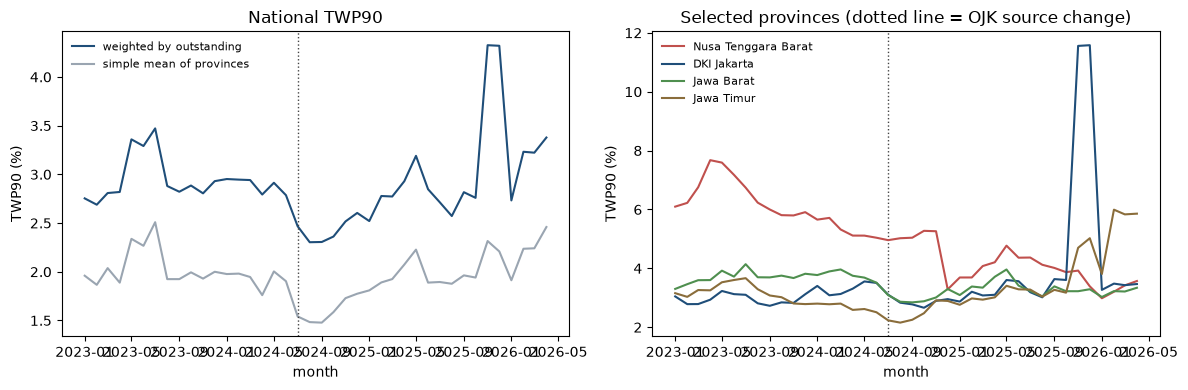

      twp90_weighted_pct  twp90_mean_pct
date                                    
2023                2.96            2.05
2024                2.66            1.76
2025                3.05            2.00
2026                3.14            2.21
province  DKI Jakarta  Jawa Barat  Jawa Timur  Nusa Tenggara Barat
date                                                              
2023             2.95        3.70        3.21                 6.50
2024             3.10        3.38        2.59                 5.07
2025             4.67        3.36        3.41                 4.04
2026             3.41        3.20        5.37                 3.30


In [19]:
# Cell 19 - National and selected-province TWP90 over time
import matplotlib.pyplot as plt

SHOW = ["Nusa Tenggara Barat", "DKI Jakarta", "Jawa Barat", "Jawa Timur"]
SHOW_COLORS = ["#c0504d", "#1f4e79", "#4f8f4f", "#8a6d3b"]
SPLICE_TS = pd.Timestamp("2024-07-01")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
axes[0].plot(nat.index, nat["twp90_weighted_pct"], color="#1f4e79", label="weighted by outstanding")
axes[0].plot(nat.index, nat["twp90_mean_pct"], color="#9aa5b1", label="simple mean of provinces")
axes[0].set_title("National TWP90")
axes[0].set_ylabel("TWP90 (%)")
for ax in axes:
    ax.axvline(SPLICE_TS, color="#444444", linestyle=":", linewidth=1)
    ax.set_xlabel("month")
axes[0].legend(frameon=False, fontsize=8)
for prov, col in zip(SHOW, SHOW_COLORS):
    s = df[df["province"] == prov]
    axes[1].plot(s["date"], s["twp90_pct"], color=col, label=prov)
axes[1].set_title("Selected provinces (dotted line = OJK source change)")
axes[1].set_ylabel("TWP90 (%)")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

yr_nat = nat.groupby(nat.index.year)[["twp90_weighted_pct", "twp90_mean_pct"]].mean().round(2)
print(yr_nat.to_string())
sub_show = df[df["province"].isin(SHOW)]
print(sub_show.pivot_table(index=sub_show["date"].dt.year, columns="province", values="twp90_pct", aggfunc="mean").round(2).to_string())


### C.6 Fitur turunan dan log
Utang per kapita (rupiah) dan akun aktif per 100 penduduk. Log-transform diaudit: dampaknya pada skewness dibandingkan dengan dan tanpa empat provinsi Papua baru.

In [20]:
# Cell 20 - Derived features and log transform
df["debt_per_capita_idr"] = df["outstanding_miliar"] * 1e9 / (df["penduduk_ribu"] * 1000)
df["accounts_per_100_pop"] = df["rekening_aktif"] / (df["penduduk_ribu"] * 1000) * 100

LOG_COLS = ["outstanding_miliar", "rekening_aktif", "penduduk_ribu", "debt_per_capita_idr", "pdrb_perkapita_ribu_idr"]
for c in LOG_COLS:
    df["log_" + c] = np.log1p(df[c])

not_new = ~df["province"].isin(NEW_PROVS)
skew_tab = pd.DataFrame({
    "skew_raw": [df[c].skew() for c in LOG_COLS],
    "skew_log": [df["log_" + c].skew() for c in LOG_COLS],
    "skew_log_excl_new_papua": [df.loc[not_new, "log_" + c].skew() for c in LOG_COLS],
}, index=LOG_COLS).round(2)
print(skew_tab.to_string())

low_dpc = df[df["debt_per_capita_idr"] < 20000].groupby("province").size().sort_values(ascending=False)
print("rows_debt_per_capita_lt_20k_idr=", low_dpc.to_dict())
last_m = df[df["date"] == df["date"].max()].set_index("province")["accounts_per_100_pop"].sort_values(ascending=False)
print(f"accounts_per_100_pop_last_month top3={last_m.head(3).round(1).to_dict()} | median={last_m.median():.1f}")


                         skew_raw  skew_log  skew_log_excl_new_papua
outstanding_miliar           3.21     -0.29                     0.43
rekening_aktif               3.48     -0.29                     0.59
penduduk_ribu                2.66      0.42                     0.47
debt_per_capita_idr          3.35     -1.37                    -0.21
pdrb_perkapita_ribu_idr      2.40      0.54                     0.72
rows_debt_per_capita_lt_20k_idr= {'Papua Pegunungan': 22, 'Papua Tengah': 14, 'Papua Selatan': 8, 'Aceh': 4, 'Papua Barat Daya': 4, 'Papua': 1}
accounts_per_100_pop_last_month top3={'DKI Jakarta': 19.1, 'Banten': 9.7, 'Jawa Barat': 9.2} | median=3.6


### C.7 Variasi antarprovinsi dan nilai yang dibawa maju
`between_share` adalah porsi varians fitur yang berasal dari perbedaan antarprovinsi (1 berarti hampir tidak ada variasi antarwaktu). Ini menentukan berapa banyak informasi independen yang sebenarnya ada di 1.448 baris.

In [21]:
# Cell 21 - Between-province variance share and carry-forward audit
VAR_FEATURES = [
    "twp90_pct", "log_outstanding_miliar", "log_rekening_aktif", "log_penduduk_ribu", "accounts_per_100_pop",
    "log_debt_per_capita_idr", "kemiskinan_pct", "ipm_score", "ump_idr", "tpt_mean_pct", "log_pdrb_perkapita_ribu_idr",
]
var_rows = []
for c in VAR_FEATURES:
    prov_mean = df.groupby("province")[c].transform("mean")
    var_rows.append({
        "feature": c,
        "between_share": round(float(prov_mean.var() / df[c].var()), 3),
        "median_distinct_per_province": int(df.groupby("province")[c].nunique().median()),
    })
print(pd.DataFrame(var_rows).to_string(index=False))

yearly = df.groupby(["province", "tahun"])[["ipm_score", "kemiskinan_pct", "pdrb_perkapita_ribu_idr"]].first()
for col, y0, y1 in [("ipm_score", 2024, 2025), ("ipm_score", 2025, 2026), ("kemiskinan_pct", 2025, 2026), ("pdrb_perkapita_ribu_idr", 2025, 2026)]:
    wide = yearly[col].unstack()
    same = int(np.isclose(wide[y0], wide[y1]).sum())
    print(f"carry_forward col={col} | {y0}->{y1} | identical_provinces={same}/{len(wide)}")


                    feature  between_share  median_distinct_per_province
                  twp90_pct          0.630                            40
     log_outstanding_miliar          0.949                            40
         log_rekening_aktif          0.986                            40
          log_penduduk_ribu          0.987                             4
       accounts_per_100_pop          0.935                            40
    log_debt_per_capita_idr          0.823                            40
             kemiskinan_pct          0.981                             3
                  ipm_score          0.996                             2
                    ump_idr          0.941                             4
               tpt_mean_pct          0.924                             4
log_pdrb_perkapita_ribu_idr          0.989                             3
carry_forward col=ipm_score | 2024->2025 | identical_provinces=38/38
carry_forward col=ipm_score | 2025->2026 | identical_pr

**Temuan bagian C.**
- **DKI Jakarta 2025-11 dan 2025-12**: TWP90 melonjak dari 3,61% ke 11,56% dan 11,58%, lalu kembali ke 3,27% pada 2026-01. Perubahan bulanan itu bernilai z sekitar +43 dan -45, yang terbesar di seluruh panel. Penelusuran di bagian H menunjukkan lonjakan itu berasal dari satu segmen (syariah) dan bukan artefak lintas-provinsi: macet syariah Jakarta naik dari 107 ke 1.333 miliar sementara macet konvensional Jakarta datar. Rata-rata 12 bulan Jakarta (4,8 di notebook teman) turun sekitar 1,4 poin tanpa dua bulan itu; median lebih tahan terhadapnya.
- **Lonjakan bersama.** Sejumlah provinsi melonjak bersamaan pada bulan yang sama (lihat `months_with_most_spikes`), jadi sebagian lonjakan adalah kejadian lintas provinsi, bukan sifat satu provinsi.
- **NTB bukan outlier struktural.** Rata-rata TWP90 tahunannya turun dari 6,50% (2023) ke 3,30% (2026). Ke-30 bulan yang ditandai IQR pooled berurutan dari 2023-01 sampai 2025-09 (ambang pooled 3,94%); sesudahnya NTB di bawah ambang. Penanda itu menangkap level tinggi yang menurun, bukan lonjakan.
- **Sebagian besar "outlier" ukuran hilang di skala log.** Outstanding turun dari 210 ke 54 baris yang ditandai, rekening dari 209 ke 91. Sisanya adalah provinsi yang memang jauh lebih besar atau kecil dari median, bukan data aneh.
- **TWP90 nasional ikut terdistorsi.** Rata-rata tertimbang mencapai puncak 4,33% pada 2025-11, bulan yang sama dengan lonjakan Jakarta; rata-rata tahunan Jakarta 2025 (4,67%) juga terangkat olehnya.
- **Hampir semua kovariat adalah variabel antarprovinsi.** `between_share` fitur sosial-ekonomi di atas 0,92, sedangkan TWP90 sekitar 0,63. Korelasi pooled antara TWP90 dan kovariat karenanya pada dasarnya membandingkan 38 provinsi, bukan 1.448 observasi.
- **IPM dan kemiskinan dibawa maju.** IPM 2025 dan 2026 identik dengan 2024 untuk semua provinsi; kemiskinan dan PDRB 2026 identik dengan 2025. Variasi antarwaktunya palsu untuk periode itu.
- **Skew `log_debt_per_capita_idr` (-1,37)** berasal terutama dari empat provinsi Papua baru yang bermula dari utang per kapita sangat rendah; angkanya menyusut ke -0,21 jika keempatnya dikeluarkan. Aceh juga punya 4 baris di bawah Rp20.000 per kapita; penyebabnya belum diselidiki.

## D. Seleksi fitur dan korelasi

Perubahan dibanding notebook teman:

- **Korelasi dihitung pada 38 provinsi, bukan 1.448 baris.** Sel 21 menunjukkan 92 sampai 99,6% varians kovariat adalah antarprovinsi, jadi korelasi pooled hampir sama dengan korelasi antarprovinsi tetapi dengan kesan sampel yang jauh lebih besar. Di sini dipakai korelasi Spearman pada snapshot 12 bulan, dengan interval kepercayaan bootstrap.
- **TWP90 snapshot memakai median**, bukan rata-rata, supaya dua bulan lonjakan Jakarta (dan lonjakan lintas provinsi lain) tidak menggeser nilainya.
- **VIF dihitung pada snapshot 38 provinsi** dan dilengkapi bukti bahwa kolinearitas `log_outstanding`, `log_penduduk`, `log_debt_per_capita` adalah identitas aljabar, bukan temuan empiris.
- **Hubungan dengan ukuran provinsi dipisahkan** (korelasi parsial dengan `log_penduduk_ribu` ditahan) dan dibandingkan dengan korelasi within-province, yaitu hubungan yang muncul dari perubahan waktu dalam satu provinsi.

### D.1 Snapshot 38 provinsi
Rata-rata fitur selama 12 bulan terakhir. TWP90 dihitung tiga cara (median, rata-rata, tertimbang outstanding) untuk melihat seberapa sensitif nilainya terhadap lonjakan.

In [22]:
# Cell 22 - Province snapshot over the last 12 months
WINDOW_MONTHS = 12
rec = df[df["date"] > df["date"].max() - pd.DateOffset(months=WINDOW_MONTHS)]
CLUSTER_FEATS = [
    "kemiskinan_pct", "tpt_mean_pct", "ipm_score", "ump_idr", "log_pdrb_perkapita_ribu_idr",
    "log_debt_per_capita_idr", "accounts_per_100_pop", "log_penduduk_ribu",
]
by_prov = rec.groupby("province")
snap = by_prov[CLUSTER_FEATS + ["log_outstanding_miliar"]].mean()
snap["twp90_median"] = by_prov["twp90_pct"].median()
snap["twp90_mean"] = by_prov["twp90_pct"].mean()
snap["twp90_weighted"] = (rec["twp90_pct"] * rec["outstanding_miliar"]).groupby(rec["province"]).sum() / by_prov["outstanding_miliar"].sum()
snap["spike_months"] = by_prov["twp90_spike_flag"].sum()

print(f"window={rec['date'].min():%Y-%m}..{rec['date'].max():%Y-%m} | provinces={len(snap)} | nan_cells={int(snap.isna().sum().sum())}")
print(snap[["twp90_median", "twp90_mean", "twp90_weighted"]].describe().loc[["mean", "50%", "max"]].round(2).to_string())
gap = (snap["twp90_mean"] - snap["twp90_median"]).sort_values(ascending=False).head(3).round(2)
print("largest_mean_minus_median_pp=", gap.to_dict())
print("dki_twp90=", snap.loc["DKI Jakarta", ["twp90_median", "twp90_mean", "twp90_weighted"]].round(2).to_dict())


window=2025-05..2026-04 | provinces=38 | nan_cells=0
      twp90_median  twp90_mean  twp90_weighted
mean          1.96        2.10            2.11
50%           1.67        1.76            1.76
max           3.90        4.78            4.90
largest_mean_minus_median_pp= {'Gorontalo': 1.54, 'DKI Jakarta': 1.26, 'Jawa Timur': 0.61}
dki_twp90= {'twp90_median': 3.52, 'twp90_mean': 4.78, 'twp90_weighted': 4.9}


### D.2 Kolinearitas
Identitas `log(utang per kapita) = log(outstanding) - log(penduduk) + ln(10^6)`, lalu VIF dengan dan tanpa `log_outstanding_miliar`.

In [23]:
# Cell 23 - Collinearity: algebraic identity and VIF on the 38-province snapshot
exact_resid = np.log(df["debt_per_capita_idr"]) - (np.log(df["outstanding_miliar"]) - np.log(df["penduduk_ribu"]))
print(f"identity_log_debt_pc_eq_log_out_minus_log_pop | resid_mean={exact_resid.mean():.4f} | resid_std={exact_resid.std():.2e} | ln(1e6)={np.log(1e6):.4f}")


def vif_table(frame, cols):
    X = frame[cols].to_numpy(dtype=float)
    X = (X - X.mean(axis=0)) / X.std(axis=0)
    out = {}
    for j, c in enumerate(cols):
        y = X[:, j]
        A = np.column_stack([np.ones(len(y)), np.delete(X, j, axis=1)])
        beta, *_ = np.linalg.lstsq(A, y, rcond=None)
        r2 = 1.0 - (y - A @ beta).var() / y.var()
        out[c] = np.inf if r2 >= 1.0 else 1.0 / (1.0 - r2)
    return pd.Series(out).sort_values(ascending=False).round(2)


FEATS_WITH_OUT = CLUSTER_FEATS + ["log_outstanding_miliar"]
print("vif_with_log_outstanding:")
print(vif_table(snap, FEATS_WITH_OUT).to_string())
print("vif_cluster_features:")
print(vif_table(snap, CLUSTER_FEATS).to_string())


identity_log_debt_pc_eq_log_out_minus_log_pop | resid_mean=13.8155 | resid_std=6.50e-16 | ln(1e6)=13.8155
vif_with_log_outstanding:
log_outstanding_miliar         31449.78
log_penduduk_ribu              12913.68
log_debt_per_capita_idr         9725.20
accounts_per_100_pop               8.57
ipm_score                          5.63
kemiskinan_pct                     4.06
ump_idr                            3.68
log_pdrb_perkapita_ribu_idr        2.46
tpt_mean_pct                       1.39
vif_cluster_features:
log_debt_per_capita_idr        6.93
ipm_score                      4.89
accounts_per_100_pop           4.70
kemiskinan_pct                 3.76
ump_idr                        3.66
log_penduduk_ribu              2.51
log_pdrb_perkapita_ribu_idr    2.33
tpt_mean_pct                   1.28


### D.3 Asosiasi antarprovinsi
Spearman antara TWP90 (median) dan tiap fitur pada 38 provinsi, dengan CI bootstrap 95% dan korelasi Pearson pooled dari panel sebagai pembanding.

In [24]:
# Cell 24 - Between-province association with TWP90 (38 provinces)
from scipy import stats

ASSOC = CLUSTER_FEATS + ["log_outstanding_miliar"]
n_prov = len(snap)
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, n_prov, size=(2000, n_prov))
panel_pearson = df[ASSOC + ["twp90_pct"]].corr(method="pearson")["twp90_pct"]

y_med = snap["twp90_median"].to_numpy()
assoc_rows = []
for f in ASSOC:
    x = snap[f].to_numpy()
    rho = stats.spearmanr(x, y_med).statistic
    boots = [stats.spearmanr(x[i], y_med[i]).statistic for i in boot_idx]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    assoc_rows.append({"feature": f, "spearman_snapshot": rho, "ci_lo": lo, "ci_hi": hi, "pearson_pooled_panel": panel_pearson[f]})
assoc = pd.DataFrame(assoc_rows).set_index("feature").round(2)
assoc = assoc.reindex(assoc["spearman_snapshot"].abs().sort_values(ascending=False).index)
print(assoc.to_string())


                             spearman_snapshot  ci_lo  ci_hi  pearson_pooled_panel
feature                                                                           
log_outstanding_miliar                    0.75   0.48   0.90                  0.54
log_penduduk_ribu                         0.67   0.39   0.84                  0.49
accounts_per_100_pop                      0.62   0.31   0.82                  0.36
log_debt_per_capita_idr                   0.51   0.17   0.76                  0.38
ipm_score                                 0.51   0.19   0.74                  0.32
ump_idr                                  -0.47  -0.74  -0.12                 -0.20
kemiskinan_pct                           -0.43  -0.68  -0.10                 -0.26
log_pdrb_perkapita_ribu_idr               0.10  -0.27   0.45                  0.05
tpt_mean_pct                             -0.06  -0.41   0.27                  0.10


### D.4 Parsial dan within-province
Apakah asosiasi bertahan setelah ukuran provinsi ditahan, dan apakah muncul ketika sebuah provinsi berubah dari waktu ke waktu.

In [25]:
# Cell 25 - Partial (size held fixed) and within-province association
rk = snap[ASSOC + ["twp90_median"]].rank()


def partial_spearman(x, y, z):
    ex = rk[x] - np.polyval(np.polyfit(rk[z], rk[x], 1), rk[z])
    ey = rk[y] - np.polyval(np.polyfit(rk[z], rk[y], 1), rk[z])
    return float(np.corrcoef(ex, ey)[0, 1])


SIZE_VAR = "log_penduduk_ribu"
partial = {f: partial_spearman(f, "twp90_median", SIZE_VAR) for f in ASSOC if f not in (SIZE_VAR, "log_outstanding_miliar")}
demeaned = df[ASSOC + ["twp90_pct"]] - df.groupby("province")[ASSOC + ["twp90_pct"]].transform("mean")
within = demeaned.corr()["twp90_pct"]

link = assoc[["spearman_snapshot"]].copy()
link["partial_given_log_pop"] = pd.Series(partial)
link["pearson_within_province"] = within
print(link.round(2).to_string())
print(f"within_province_rows={len(demeaned)} | between_share_twp90={float((df.groupby('province')['twp90_pct'].transform('mean').var()) / df['twp90_pct'].var()):.2f}")


                             spearman_snapshot  partial_given_log_pop  pearson_within_province
feature                                                                                       
log_outstanding_miliar                    0.75                    NaN                     0.10
log_penduduk_ribu                         0.67                    NaN                     0.01
accounts_per_100_pop                      0.62                   0.44                    -0.05
log_debt_per_capita_idr                   0.51                   0.38                     0.09
ipm_score                                 0.51                   0.25                    -0.03
ump_idr                                  -0.47                  -0.22                     0.16
kemiskinan_pct                           -0.43                  -0.24                    -0.03
log_pdrb_perkapita_ribu_idr               0.10                   0.17                     0.07
tpt_mean_pct                             -0.06    

**Temuan bagian D.**
- **TWP90 snapshot sensitif terhadap lonjakan.** Jakarta: median 3,52 vs rata-rata 4,78 dan tertimbang 4,90. Gorontalo selisih rata-rata dan median 1,54 poin karena tiga bulan terakhir (2026-02 sampai 2026-04) berada di 7,7 sampai 8,3%. Median dipakai sebagai nilai utama.
- **Kolinearitas outstanding, penduduk, dan utang per kapita adalah identitas.** Residual `log(utang per kapita) - (log outstanding - log penduduk)` tetap 13,8155 = ln(10^6) dengan simpangan baku 6,5e-16. VIF 31.450, 12.914, dan 9.725 sebelum `log_outstanding_miliar` dibuang; sesudahnya VIF terbesar 6,93 (`log_debt_per_capita_idr`).
- **Ukuran pasar lebih kuat daripada kemiskinan, dan berbeda arah.** Spearman dengan TWP90 median: outstanding 0,75 (CI 0,48 sampai 0,90), penduduk 0,67, akun per 100 penduduk 0,62, IPM 0,51, UMP -0,47, kemiskinan -0,43 (CI -0,68 sampai -0,10). Kemiskinan bukan nol: provinsi lebih miskin cenderung punya TWP90 lebih rendah.
- **Setelah penduduk ditahan** (korelasi parsial), akun aktif per 100 penduduk (0,44) dan utang per kapita (0,38) bertahan, sedangkan kemiskinan (-0,24) dan IPM (0,25) melemah. Dengan n=38, CI lebar dan korelasi parsial di sini tanpa CI.
- **Hubungan itu tidak muncul di dalam provinsi.** Korelasi within-province semuanya kecil (maksimum 0,16 untuk UMP): outstanding 0,10, akun per 100 penduduk -0,05. Variabel sosial-ekonomi hampir tidak berubah antarwaktu sehingga tidak bisa diuji dengan cara ini, tetapi outstanding dan akun berubah tiap bulan dan tetap tidak berhubungan. Jadi hubungan ukuran pasar dengan TWP90 adalah perbedaan antarprovinsi yang stabil, bukan bukti bahwa pertumbuhan pasar menaikkan gagal bayar.

## E. Clustering

Perubahan dibanding notebook teman:

- **`twp90_pct` tidak lagi menjadi fitur clustering.** TWP90 dipakai hanya untuk memprofilkan cluster. Dengan begitu perbedaan TWP90 antarcluster adalah temuan, bukan akibat definisi cluster.
- **Pemilihan k didasarkan pada silhouette dan kestabilan**, bukan hanya silhouette. Kestabilan diukur dengan Adjusted Rand Index pada 100 subsampel 80%, dan dengan seberapa konsisten tiap provinsi masuk ke cluster yang sama.
- **DKI Jakarta dikeluarkan dengan alasan terukur**: dengan Jakarta ikut, k=3 menyisakan cluster singleton. Jakarta dianalisis terpisah (sel 30).
- **Hasil lama direproduksi** (TWP90 sebagai fitur, k=3) dan dibandingkan dengan hasil baru (sel 29).

### E.1 Memilih k
Silhouette untuk k=2 sampai 8, dengan dan tanpa Jakarta.

 k  with_dki  without_dki
 2     0.292        0.306
 3     0.391        0.161
 4     0.269        0.266
 5     0.244        0.205
 6     0.197        0.191
 7     0.195        0.195
 8     0.210        0.204
with_dki_k3_cluster_sizes=[1, 5, 32]


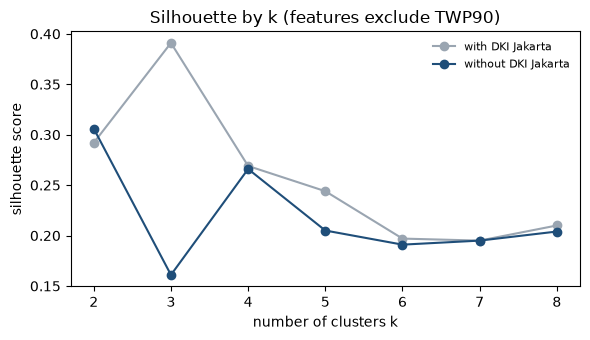

In [26]:
# Cell 26 - Choose k: silhouette with and without DKI Jakarta
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt

snap_ex = snap.drop(index="DKI Jakarta")


def scaled(frame):
    return StandardScaler().fit_transform(frame[CLUSTER_FEATS])


def silhouette_by_k(frame, ks):
    X = scaled(frame)
    return {k: round(float(silhouette_score(X, KMeans(k, n_init=20, random_state=SEED).fit(X).labels_)), 3) for k in ks}


KS = range(2, 9)
sil_all = silhouette_by_k(snap, KS)
sil_ex = silhouette_by_k(snap_ex, KS)
print(pd.DataFrame({"k": list(KS), "with_dki": list(sil_all.values()), "without_dki": list(sil_ex.values())}).to_string(index=False))
X_all = scaled(snap)
sizes_k3_all = np.bincount(KMeans(3, n_init=20, random_state=SEED).fit(X_all).labels_).tolist()
print(f"with_dki_k3_cluster_sizes={sorted(sizes_k3_all)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(KS), list(sil_all.values()), "o-", color="#9aa5b1", label="with DKI Jakarta")
ax.plot(list(KS), list(sil_ex.values()), "o-", color="#1f4e79", label="without DKI Jakarta")
ax.set_xlabel("number of clusters k")
ax.set_ylabel("silhouette score")
ax.set_title("Silhouette by k (features exclude TWP90)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


### E.2 Kestabilan
ARI pada subsampel 80% dan persentase subsampel di mana provinsi tetap masuk ke cluster yang sama.

In [27]:
# Cell 27 - Stability of the partition: 80% subsamples and per-province agreement
X_ex = scaled(snap_ex)


def stability(X, k, n_boot=100):
    base = KMeans(k, n_init=20, random_state=SEED).fit(X).labels_
    boot_rng = np.random.default_rng(SEED)
    aris = []
    agree = np.zeros(len(X))
    for b in range(n_boot):
        idx = boot_rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
        km = KMeans(k, n_init=10, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(base[idx], km.labels_))
        pred = km.predict(X)
        conf = pd.crosstab(base, pred).reindex(index=range(k), columns=range(k), fill_value=0).to_numpy()
        rows_i, cols_i = linear_sum_assignment(-conf)
        mapping = dict(zip(cols_i, rows_i))
        agree += np.array([mapping[p] == b0 for p, b0 in zip(pred, base)])
    return base, np.array(aris), agree / n_boot


stab = {k: stability(X_ex, k) for k in (2, 3, 4, 5)}
print(pd.DataFrame({
    "k": list(stab),
    "silhouette": [sil_ex[k] for k in stab],
    "ari_mean": [round(float(v[1].mean()), 2) for v in stab.values()],
    "ari_p10": [round(float(np.percentile(v[1], 10)), 2) for v in stab.values()],
}).to_string(index=False))
for k in (2, 4):
    agree = pd.Series(stab[k][2], index=snap_ex.index)
    unstable = agree[agree < 0.8].sort_values().round(2)
    print(f"k={k} provinces_with_agreement_below_0.8=", unstable.to_dict())


 k  silhouette  ari_mean  ari_p10
 2       0.306      0.55     0.17
 3       0.161      0.29     0.11
 4       0.266      0.53     0.17
 5       0.205      0.57     0.32
k=2 provinces_with_agreement_below_0.8= {'Sulawesi Barat': 0.19, 'Nusa Tenggara Timur': 0.2, 'Maluku': 0.4, 'Aceh': 0.44, 'Papua': 0.48, 'Papua Barat': 0.59, 'Papua Barat Daya': 0.72}
k=4 provinces_with_agreement_below_0.8= {'Kalimantan Timur': 0.46, 'Jawa Tengah': 0.48, 'Jawa Timur': 0.5, 'DI Yogyakarta': 0.54, 'Nusa Tenggara Timur': 0.54, 'Papua Tengah': 0.54, 'Sulawesi Utara': 0.56, 'Kepulauan Riau': 0.59, 'Nusa Tenggara Barat': 0.6, 'Sulawesi Barat': 0.61, 'Lampung': 0.63, 'Kalimantan Barat': 0.65, 'Bengkulu': 0.65, 'Sumatera Utara': 0.68, 'Gorontalo': 0.71, 'Riau': 0.74, 'Sulawesi Tenggara': 0.75, 'Sumatera Barat': 0.76, 'Papua Pegunungan': 0.76, 'Kalimantan Utara': 0.77, 'Maluku': 0.77}


### E.3 Profil cluster
k=2 sebagai pembagian utama dan k=4 sebagai pembacaan lebih halus. Cluster diberi nama C1, C2, dan seterusnya berurutan dari akun aktif per 100 penduduk tertinggi.

In [28]:
# Cell 28 - Cluster profiles for k=2 (primary) and k=4 (finer view)
PROFILE_COLS = ["twp90_median", "kemiskinan_pct", "ipm_score", "ump_idr", "accounts_per_100_pop", "log_debt_per_capita_idr", "log_penduduk_ribu"]


def label_clusters(frame, base_labels):
    tmp = frame.assign(_raw=base_labels)
    order = tmp.groupby("_raw")["accounts_per_100_pop"].mean().sort_values(ascending=False).index
    rename = {raw: f"C{i + 1}" for i, raw in enumerate(order)}
    return tmp["_raw"].map(rename)


snap_ex = snap_ex.assign(cluster_k2=label_clusters(snap_ex, stab[2][0]), cluster_k4=label_clusters(snap_ex, stab[4][0]))
for k in (2, 4):
    col = f"cluster_k{k}"
    prof = snap_ex.groupby(col)[PROFILE_COLS].mean().round(2)
    prof.insert(0, "n", snap_ex.groupby(col).size())
    print(f"profile {col}:")
    print(prof.to_string())
    for c in sorted(snap_ex[col].unique()):
        print(f"  {c}: {snap_ex.index[snap_ex[col] == c].tolist()}")


profile cluster_k2:
             n  twp90_median  kemiskinan_pct  ipm_score     ump_idr  accounts_per_100_pop  log_debt_per_capita_idr  log_penduduk_ribu
cluster_k2                                                                                                                           
C1          27          2.20            7.52      73.95  3174747.99                  4.37                    12.49               8.54
C2          10          1.13           18.96      67.09  3721701.57                  1.49                    10.99               7.30
  C1: ['Bali', 'Banten', 'Bengkulu', 'DI Yogyakarta', 'Gorontalo', 'Jambi', 'Jawa Barat', 'Jawa Tengah', 'Jawa Timur', 'Kalimantan Barat', 'Kalimantan Selatan', 'Kalimantan Tengah', 'Kalimantan Timur', 'Kalimantan Utara', 'Kepulauan Bangka Belitung', 'Kepulauan Riau', 'Lampung', 'Maluku Utara', 'Nusa Tenggara Barat', 'Riau', 'Sulawesi Selatan', 'Sulawesi Tengah', 'Sulawesi Tenggara', 'Sulawesi Utara', 'Sumatera Barat', 'Sumatera Selatan', '

### E.4 Perbandingan dengan hasil lama
Mengulang clustering yang memakai TWP90 sebagai fitur dan mengukur seberapa jauh partisinya berbeda.

In [29]:
# Cell 29 - Reproduce the original clustering (TWP90 as a feature) and compare
FRIEND_FEATS = CLUSTER_FEATS + ["twp90_mean"]
X_friend = StandardScaler().fit_transform(snap_ex[FRIEND_FEATS])
lab_friend = KMeans(3, n_init=10, random_state=SEED).fit(X_friend).labels_
lab_k3 = stab[3][0]
print(f"with_twp90_k3 sizes={sorted(np.bincount(lab_friend).tolist())} | silhouette={silhouette_score(X_friend, lab_friend):.3f}")
print(f"without_twp90_k3 sizes={sorted(np.bincount(lab_k3).tolist())} | silhouette={sil_ex[3]:.3f}")
print(f"ari_with_vs_without_twp90 k3={adjusted_rand_score(lab_friend, lab_k3):.2f} | vs_k2={adjusted_rand_score(lab_friend, stab[2][0]):.2f} | vs_k4={adjusted_rand_score(lab_friend, stab[4][0]):.2f}")

twp_by_friend = snap_ex.assign(f=lab_friend).groupby("f")["twp90_mean"].mean().round(2).sort_values()
print("twp90_mean_by_cluster_with_twp90_feature=", twp_by_friend.to_dict())


with_twp90_k3 sizes=[6, 10, 21] | silhouette=0.235
without_twp90_k3 sizes=[3, 16, 18] | silhouette=0.161
ari_with_vs_without_twp90 k3=0.14 | vs_k2=0.63 | vs_k4=0.40
twp90_mean_by_cluster_with_twp90_feature= {1: 1.2, 0: 2.06, 2: 3.3}


### E.5 Kasus khusus
DKI Jakarta (di luar cluster) dan NTB (provinsi dengan tren turun terbesar).

In [30]:
# Cell 30 - Special cases: DKI Jakarta (excluded) and Nusa Tenggara Barat
z_dki = ((snap.loc["DKI Jakarta", CLUSTER_FEATS] - snap_ex[CLUSTER_FEATS].mean()) / snap_ex[CLUSTER_FEATS].std()).round(1)
print("dki_feature_z_vs_other_37=", z_dki.sort_values(key=abs, ascending=False).head(4).to_dict())

ntb = "Nusa Tenggara Barat"
print(f"ntb cluster_k2={snap_ex.loc[ntb, 'cluster_k2']} | cluster_k4={snap_ex.loc[ntb, 'cluster_k4']} | twp90_median_12m={snap_ex.loc[ntb, 'twp90_median']:.2f}")
tw = df[df["province"] != "DKI Jakarta"].merge(snap_ex[["cluster_k4"]], left_on="province", right_index=True)
cluster_year = tw.groupby([tw["date"].dt.year, "cluster_k4"])["twp90_pct"].mean().unstack().round(2)
ntb_year_mean = df[df["province"] == ntb].groupby(df["date"].dt.year)["twp90_pct"].mean().round(2)
cluster_year["NTB"] = ntb_year_mean
print(cluster_year.to_string())


dki_feature_z_vs_other_37= {'accounts_per_100_pop': 7.6, 'ump_idr': 3.6, 'log_pdrb_perkapita_ribu_idr': 3.1, 'ipm_score': 2.2}
ntb cluster_k2=C1 | cluster_k4=C2 | twp90_median_12m=3.90
cluster_k4    C1    C2    C3    C4   NTB
date                                    
2023        2.68  2.01  1.48   NaN  6.50
2024        2.28  1.82  0.96  0.54  5.07
2025        2.33  2.11  1.17  1.22  4.04
2026        2.26  2.52  1.18  0.71  3.30


**Temuan bagian E.**
- **Reproduksi sahih.** Clustering lama (TWP90 sebagai fitur, k=3, tanpa Jakarta) menghasilkan ukuran cluster 21, 10, dan 6 dengan silhouette 0,235, sama dengan notebook teman.
- **Tanpa Jakarta, k=2 terbaik dan k=3 terburuk.** Silhouette 0,306 (k=2) vs 0,161 (k=3) vs 0,266 (k=4). Dengan Jakarta ikut, k=3 tampak 0,391 hanya karena Jakarta menjadi cluster singleton (ukuran 1, 5, dan 32). Stabilitas ARI pada subsampel 80%: k=2 0,55, k=3 0,29, k=4 0,53, k=5 0,57.
- **Strukturnya lemah.** Silhouette di bawah sekitar 0,31 dan ARI sekitar 0,55 berarti provinsi lebih tepat dibaca sebagai gradien ukuran pasar dan pembangunan daripada kelompok yang terpisah tegas. Tujuh provinsi berada di perbatasan pada k=2 (kesesuaian di bawah 0,8): Sulawesi Barat, NTT, Maluku, Aceh, Papua, Papua Barat, dan Papua Barat Daya.
- **TWP90 tetap berbeda antarcluster padahal bukan fitur.** k=2: C1 (27 provinsi) 2,20% vs C2 (10 provinsi, timur dan miskin) 1,13%. Pada k=4 perbedaannya bukan di antara cluster pasar besar: C1 (2,25%) dan C2 (2,13%) hampir sama, sedangkan C3 1,10% dan C4 0,92% jauh lebih rendah. Perbedaan utamanya adalah antara cluster pasar besar dan cluster timur dengan penetrasi rendah (akun 1,49 per 100 penduduk, kemiskinan 18,96% pada k=2).
- **Partisi lama lebih mirip pembagian dua.** ARI hasil lama (k=3) terhadap k=3 baru hanya 0,14, tetapi terhadap k=2 baru 0,63.
- **Jakarta** berjarak +7,6 simpangan baku dari 37 provinsi lain pada akun aktif per 100 penduduk, dan diperlakukan terpisah.
- **NTB tetap tinggi di dalam clusternya.** TWP90 median 12 bulannya, 3,90%, sama dengan maksimum 38 provinsi. NTB sekelompok dengan Jawa Tengah, Jawa Timur, dan DIY (cluster k=4 dengan rata-rata 2,13%), bukan dengan Jawa Barat dan Banten. Pada 2026 NTB 3,30% vs rata-rata clusternya 2,52%. Klaim lama bahwa risikonya mirip provinsi Jawa tidak didukung penuh.

## F. Interpretasi dan batasan

Bagian ini menulis ulang kesimpulan dengan batas yang ditopang data. Angka merujuk ke sel di bagian C, D, dan E.

### F.1 Yang ditopang data

1. **TWP90 adalah ciri provinsi yang cukup stabil.** 63% varians TWP90 adalah varians antarprovinsi (sel 25). Sisa 37% adalah variasi antarwaktu dalam provinsi, termasuk tren turun NTB dan lonjakan sementara seperti Jakarta.
2. **Provinsi dengan pasar lebih besar dan penetrasi lebih tinggi cenderung punya TWP90 lebih tinggi.** Spearman antarprovinsi (n=38): outstanding 0,75 (CI 0,48 sampai 0,90), penduduk 0,67, akun per 100 penduduk 0,62 (sel 24). Untuk penetrasi dan utang per kapita hubungan itu bertahan setelah ukuran penduduk ditahan (0,44 dan 0,38; sel 25), dan juga di dalam tiap cluster k=2 (outstanding: 0,46 pada C1 dan 0,43 pada C2; sel 31).
3. **Kemiskinan berasosiasi negatif, bukan nol.** Spearman -0,43 (CI -0,68 sampai -0,10); melemah menjadi -0,24 setelah penduduk ditahan. Provinsi lebih miskin cenderung punya TWP90 lebih rendah.
4. **Ada dua kelompok kasar, dengan batas yang lembek.** k=2: 27 provinsi dengan TWP90 median 2,20% dan 10 provinsi timur dengan 1,13% (sel 28). Perbedaan TWP90 ini bukan akibat definisi cluster karena TWP90 tidak dipakai sebagai fitur. Silhouette 0,31 dan stabilitas ARI 0,55 berarti ini lebih mirip gradien daripada dua kelompok terpisah; tujuh provinsi berada di perbatasan (sel 27).
5. **Dua kasus khusus.** DKI Jakarta (akun per 100 penduduk +7,6 simpangan baku dari provinsi lain; TWP90 2025-11 dan 2025-12 didorong satu segmen syariah; lihat bagian H) dan NTB (TWP90 turun dari 6,50% ke 3,30% tetapi tetap tertinggi di 38 provinsi pada 12 bulan terakhir).

### F.2 Yang tidak ditopang data (koreksi dari kesimpulan awal)

- **"Gagal bayar dipengaruhi besar pasar, bukan kemiskinan."** Yang ditopang hanya: *berasosiasi* dengan ukuran pasar dan penetrasi pada 38 provinsi. Hubungan itu tidak muncul di dalam provinsi (korelasi within-province 0,10 untuk outstanding dan -0,05 untuk akun; sel 25), jadi tidak ada bukti bahwa membesarnya pasar menaikkan TWP90.
- **"Pinjol sedikit berarti TWP90 otomatis kecil karena akses internet terbatas."** Tidak ada variabel akses internet di data, sehingga ini hipotesis (H2 di bawah). TWP90 juga rasio, bukan jumlah.
- **Penjelasan berbasis cluster.** Pada notebook awal, cluster dibentuk dengan TWP90 sebagai fitur lalu dijelaskan dengan TWP90. Setelah TWP90 dikeluarkan, partisinya berubah banyak (ARI 0,14 pada k=3; sel 29).
- **"NTB mirip provinsi Jawa."** NTB sekelompok dengan Jawa Tengah, Jawa Timur, dan DIY pada k=4, tetapi TWP90 2026-nya 3,30% vs 2,52% rata-rata clusternya (sel 30).

### F.3 Hipotesis yang belum diuji

| | Hipotesis | Data yang menguji |
|---|---|---|
| H1 | TWP90 rendah di provinsi timur karena portofolionya muda (outstanding tumbuh cepat sehingga penyebut membesar sebelum pinjaman jatuh tempo). Diuji di bagian I: arah sesuai tetapi tidak signifikan, hilang saat Papua baru disertakan, dan provinsi mapan di cluster timur tidak tumbuh lebih cepat, jadi tidak menjelaskan jurangnya | umur pinjaman atau kualitas pembiayaan per kohort penyaluran |
| H2 | Akses internet dan penetrasi aplikasi menjelaskan TWP90 rendah | indikator akses internet BPS per provinsi |
| H3 | Komposisi platform (platform tertentu menyalurkan lebih banyak di provinsi tertentu) menjelaskan perbedaan level | outstanding dan TWP90 per platform per provinsi |
| H4 | Pemberi pinjaman menyaring lebih ketat di provinsi miskin, sehingga TWP90 rendah | tingkat penolakan atau limit per provinsi |
| H5 | Lonjakan Jakarta 2025-11 dan 2025-12 adalah kegagalan satu penyelenggara syariah besar yang kemudian keluar atau dihapus buku (bukan artefak pelaporan; bagian H.3) | identitas penyelenggara per segmen dan provinsi, pengumuman OJK tentang penyelenggara itu |
| H6 | Lonjakan 2026-02 didorong beberapa penyelenggara konvensional besar di Jawa Timur (+281 dari +573 miliar macet nasional; bagian H.4); lonjakan 2023-08 dan 2025-06 belum dijelaskan | TWP90 per platform pada bulan-bulan itu |

### F.4 Batasan

- **n=38 provinsi.** CI lebar, korelasi parsial tanpa CI, dan struktur cluster lemah. Tidak ada uji signifikansi yang dikoreksi untuk banyak perbandingan.
- **Analisis ekologis.** Semua hubungan berlaku di tingkat provinsi, bukan di tingkat peminjam.
- **Variabel sosial-ekonomi nyaris statis.** 92 sampai 99,6% variansnya antarprovinsi, dan IPM 2025 dan 2026 serta kemiskinan dan PDRB 2026 adalah salinan tahun sebelumnya (sel 21). Hubungan within-province untuk variabel ini tidak dapat diuji.
- **Sambungan sumber data.** TWP90 2024-07 sampai 2024-10 dihitung dari SJKPublic yang berbeda dari XLSX di sekitar 90% provinsi (sel 10). Selisihnya bukan revisi XLSX (0 dari 152 sel berubah antarrilis; sel 37): SJKPublic lebih rendah 1,1 sampai 1,8% pada median outstanding provinsi, dan data ini tidak menjelaskan penyebabnya.
- **Snapshot 12 bulan** (2025-05 sampai 2026-04) memuat lonjakan Jakarta dan lonjakan lintas provinsi 2026-02; median dipakai untuk membatasi dampaknya, tetapi tidak menghilangkannya.
- **Papua baru** hanya punya 22 bulan dan outstanding sangat kecil (0,11% dari total).
- **Tidak ada inferensi kausal.** Tidak ada desain identifikasi (DiD, variabel instrumen, atau eksperimen).

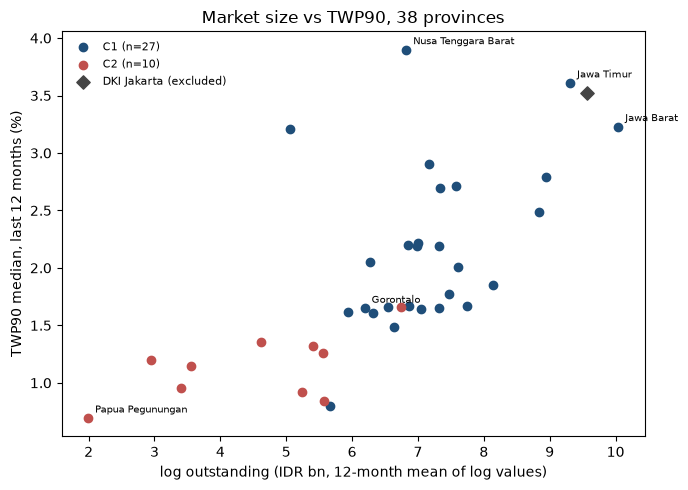

spearman_all_38=0.75
spearman_within_C1 n=27 = 0.46
spearman_within_C2 n=10 = 0.43
                     log_outstanding_miliar  twp90_median
province                                                 
Nusa Tenggara Barat                    6.82          3.90
Jawa Timur                             9.31          3.61
Jawa Barat                            10.04          3.23
Gorontalo                              6.19          1.65
Papua Pegunungan                       1.99          0.69


In [31]:
# Cell 31 - Market size vs TWP90 by cluster (k=2), DKI Jakarta marked
fig, ax = plt.subplots(figsize=(7, 5))
CLUSTER_COLORS = {"C1": "#1f4e79", "C2": "#c0504d"}
for c, g in snap_ex.groupby("cluster_k2"):
    ax.scatter(g["log_outstanding_miliar"], g["twp90_median"], color=CLUSTER_COLORS[c], s=36, label=f"{c} (n={len(g)})")
dki = snap.loc["DKI Jakarta"]
ax.scatter(dki["log_outstanding_miliar"], dki["twp90_median"], color="#444444", marker="D", s=46, label="DKI Jakarta (excluded)")
LABELED = ["Nusa Tenggara Barat", "Jawa Timur", "Jawa Barat", "Gorontalo", "Papua Pegunungan"]
for name in LABELED:
    ax.annotate(name, (snap.loc[name, "log_outstanding_miliar"], snap.loc[name, "twp90_median"]), textcoords="offset points", xytext=(5, 4), fontsize=7)
ax.set_xlabel("log outstanding (IDR bn, 12-month mean of log values)")
ax.set_ylabel("TWP90 median, last 12 months (%)")
ax.set_title("Market size vs TWP90, 38 provinces")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print(f"spearman_all_38={stats.spearmanr(snap['log_outstanding_miliar'], snap['twp90_median']).statistic:.2f}")
for c, g in snap_ex.groupby("cluster_k2"):
    print(f"spearman_within_{c} n={len(g)} = {stats.spearmanr(g['log_outstanding_miliar'], g['twp90_median']).statistic:.2f}")
print(snap.loc[LABELED, ["log_outstanding_miliar", "twp90_median"]].round(2).to_string())


**Cara membaca grafik pencar (sel 31).** Setiap titik adalah satu provinsi. Korelasi Spearman antara outstanding dan TWP90 adalah 0,75 untuk 38 provinsi. Di dalam tiap cluster k=2 nilainya lebih rendah tetapi tetap positif: 0,46 pada C1 (n=27) dan 0,43 pada C2 (n=10). Jadi hubungan ukuran pasar dengan TWP90 bukan semata akibat perbedaan antara dua kelompok, tetapi sebagian dari kekuatannya memang berasal dari perbedaan itu. Nilai pada C2 berasal dari 10 provinsi saja dan karenanya sangat tidak pasti.

## G. Ekspor

Menyimpan hasil ke folder `artifacts/`: tabel cluster per provinsi (termasuk kesesuaian cluster pada subsampel), deret TWP90 nasional bulanan, dan grafik pencar. Kolom `cluster_k2` dan `cluster_k4` bernilai `excluded` untuk DKI Jakarta.

In [32]:
# Cell 32 - Export cluster table, national series, and figure
ART_DIR = DIRS["artifacts"]
export = snap.copy()
export["cluster_k2"] = snap_ex["cluster_k2"]
export["cluster_k4"] = snap_ex["cluster_k4"]
export["k2_agreement"] = pd.Series(stab[2][2], index=snap_ex.index)
export["k4_agreement"] = pd.Series(stab[4][2], index=snap_ex.index)
for col in ["cluster_k2", "cluster_k4"]:
    export[col] = export[col].fillna("excluded")
export = export.reset_index().round(4)
export.to_csv(ART_DIR / "province_clusters.csv", index=False)
nat.reset_index().round(4).to_csv(ART_DIR / "national_twp90_monthly.csv", index=False)
fig.savefig(ART_DIR / "fig_market_size_vs_twp90.png", dpi=150)

for fname in ["province_clusters.csv", "national_twp90_monthly.csv", "fig_market_size_vs_twp90.png"]:
    fp = ART_DIR / fname
    print(f"file={fname} | kb={fp.stat().st_size / 1024:.1f}")
print(f"province_clusters rows={len(export)} | cols={export.shape[1]} | excluded={int((export['cluster_k2'] == 'excluded').sum())}")


C:\Users\Hi\AppData\Local\Temp\ipykernel_37508\1506046009.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  nat.reset_index().round(4).to_csv(ART_DIR / "national_twp90_monthly.csv", index=False)


file=province_clusters.csv | kb=4.7
file=national_twp90_monthly.csv | kb=1.6
file=fig_market_size_vs_twp90.png | kb=53.9
province_clusters rows=38 | cols=18 | excluded=1


## H. Validasi independen dan forensik

Bagian ini menguji hasil bagian B sampai F dengan kode baru dari file mentah, tanpa memakai `master_pindar_panel_clean.csv` sebagai sumber kebenaran:

1. Rekonsiliasi TWP90 nasional panel dengan baris `JUMLAH` resmi pada Tabel 9 workbook XLSX (sel 33).
2. Penurunan ulang TWP90 provinsi dari tabel kualitas SJKPublic (sel 34) dan uji identitas tabel 144.
3. Forensik lonjakan Jakarta 2025-11 dan 2025-12 menurut segmen dan bucket kualitas (sel 35).
4. Penggerak bulan lonjakan lain menurut segmen dan provinsi (sel 36).
5. Uji apakah selisih XLSX vs SJKPublic pada 2024-07 sampai 2024-10 berasal dari revisi antarrilis XLSX (sel 37).

Pengumuman OJK tentang peralihan publikasi hanya menyatakan bahwa mulai periode Januari 2026 statistik LPBBTI disajikan di Portal Data; pengumuman itu tidak menjelaskan selisih 2024-07 sampai 2024-10. Berkas `Mapping_Statistik_LPBBTI.xlsx` adalah peta antara tabel publikasi lama dan metrik portal, bukan kamus definisi; satu-satunya hal yang ditegaskannya adalah bahwa Tabel 9 resmi tersusun dari metrik kualitas pembiayaan per provinsi (1453/1454) dan metrik TWP90-DATI1 (144/312).

### H.1 Rekonsiliasi dengan total nasional resmi
Baris `JUMLAH` pada sheet 9 diambil dari rilis terbaru untuk tiap bulan dan dibandingkan dengan TWP90 nasional tertimbang dari panel.

In [33]:
# Cell 33 - Reconcile with the official XLSX national total (independent sheet-9 parse)
xl_rows = []
for fp in sorted((RAW_DIR / "ojk_xlsx").glob("*.xlsx")):
    release = fp.stem.replace("ojk_lpbbti_", "")
    wb = openpyxl.load_workbook(fp, read_only=True, data_only=True)
    ws = wb[[s for s in wb.sheetnames if s.strip() == "9"][0]]
    sheet_rows = list(ws.iter_rows(min_row=1, max_row=60, values_only=True))
    wb.close()
    date_cols = [(j, parse_ojk_month_iso(v)) for j, v in enumerate(sheet_rows[1]) if j >= 2 and v is not None and parse_ojk_month_iso(v)]
    for r in sheet_rows[3:]:
        label = str(r[1]).strip() if len(r) > 1 and r[1] is not None else ""
        is_total = label.upper() == "JUMLAH"
        if not (is_total or re.match(r"^\d+\.", label)):
            continue
        prov = "TOTAL" if is_total else normalize_province(re.sub(r"^\d+\.\s*", "", label))[1]
        for j, d in date_cols:
            if j + 2 < len(r) and r[j + 1] is not None and r[j + 2] is not None:
                xl_rows.append((release, d, prov, float(r[j + 1]), float(r[j + 2]) * 100.0))
xl_rel = pd.DataFrame(xl_rows, columns=["release", "date", "prov", "out_miliar", "twp90_pct"])
print(f"xlsx_obs={len(xl_rel)} | releases={xl_rel['release'].nunique()} | dates={xl_rel['date'].min()}..{xl_rel['date'].max()}")

master_s = df.assign(date=df["date"].dt.strftime("%Y-%m-%d"))
nat_m = master_s.assign(mx=master_s["twp90_pct"] * master_s["outstanding_miliar"]).groupby("date").agg(mx=("mx", "sum"), out=("outstanding_miliar", "sum"))
nat_m["twp90_w"] = nat_m["mx"] / nat_m["out"]
xl_total = xl_rel[xl_rel["prov"] == "TOTAL"].sort_values(["date", "release"]).drop_duplicates("date", keep="last").set_index("date")
recon = nat_m.join(xl_total[["out_miliar", "twp90_pct"]], how="inner")
recon["d_twp90_pp"] = recon["twp90_w"] - recon["twp90_pct"]
recon["d_out_pct"] = (recon["out"] / recon["out_miliar"] - 1.0) * 100.0
before_splice = recon[recon.index < "2024-07-01"]
after_splice = recon[recon.index >= "2024-07-01"]
print(f"months={len(recon)} | xlsx_period max_abs_d_twp90_pp={before_splice['d_twp90_pp'].abs().max():.4f} | sjk_period max_abs_d_twp90_pp={after_splice['d_twp90_pp'].abs().max():.4f}")
worst = recon.reindex(recon["d_twp90_pp"].abs().sort_values(ascending=False).index).head(5)
print(worst[["twp90_w", "twp90_pct", "d_twp90_pp", "out", "out_miliar", "d_out_pct"]].round(3).to_string())
print(f"months_after_2024_10_with_abs_d_twp90_pp_gt_0.01={int((after_splice[after_splice.index > '2024-10-01']['d_twp90_pp'].abs() > 0.01).sum())}")


xlsx_obs=8941 | releases=18 | dates=2022-01-01..2025-12-01
months=36 | xlsx_period max_abs_d_twp90_pp=0.0020 | sjk_period max_abs_d_twp90_pp=0.0722
            twp90_w  twp90_pct  d_twp90_pp        out  out_miliar  d_out_pct
date                                                                        
2024-08-01    2.303      2.376      -0.072  71023.370   72033.441     -1.402
2024-09-01    2.306      2.375      -0.069  73305.901   74484.240     -1.582
2024-07-01    2.467      2.535      -0.068  68142.496   69393.360     -1.803
2024-10-01    2.362      2.367      -0.005  74267.851   75019.479     -1.002
2023-02-01    2.689      2.687       0.002  50050.747   50088.898     -0.076
months_after_2024_10_with_abs_d_twp90_pp_gt_0.01=0


### H.2 Penurunan ulang dari tabel mentah
TWP90 provinsi dihitung ulang dari bucket kualitas pembiayaan (macet dibagi total outstanding, konvensional + syariah) dan dibandingkan dengan kolom di master. Tabel 144 diuji pada identitas: jumlahnya di seluruh provinsi harus sama dengan TWP90 nasional konvensional.

In [34]:
# Cell 34 - Re-derive provincial TWP90 from raw SJKPublic tables and check table 144
sjk_dir = RAW_DIR / "ojk_sjkpublic"
VAL_COL = "OutstandingPerseoranganKualitasPerDati"
QUAL_FILES = [
    ("konv", "1453_konv_borrower_kualitas_dati1_LPBBTI_PenerimaPinjamanKualitasPerDati.csv"),
    ("syar", "1454_syar_borrower_kualitas_dati1_LPBBTI_Syariah_PenerimaPinjamanKualitasPerDati.csv"),
]
parts = []
for seg, fn in QUAL_FILES:
    part = pd.read_csv(sjk_dir / fn)
    part["segment"] = seg
    parts.append(part)
sjk_q = pd.concat(parts, ignore_index=True)
sjk_q["date"] = sjk_q["Bulan"].astype(str) + "-01"
sjk_q["prov"] = sjk_q["DATI1"].map(lambda s: normalize_province(s)[1])

BUCKETS = ["lancar", "dpk", "kurang_lancar", "diragukan", "macet"]
qual = sjk_q.pivot_table(index=["date", "prov"], columns="KualitasPembiayaan", values=VAL_COL, aggfunc="sum").fillna(0.0) / 1e9
assert [c[:3] for c in qual.columns] == ["001", "002", "003", "004", "005"], "unexpected quality buckets"
qual.columns = BUCKETS
qual["out_miliar"] = qual[BUCKETS].sum(axis=1)
qual["twp90_pct"] = qual["macet"] / qual["out_miliar"] * 100.0

chk = qual.reset_index().merge(
    master_s[["date", "province", "twp90_pct", "outstanding_miliar"]],
    left_on=["date", "prov"], right_on=["date", "province"], how="left", suffixes=("_raw", "_master"), validate="one_to_one",
)
print(f"raw_rows={len(chk)} | matched_in_master={int(chk['twp90_pct_master'].notna().sum())} | max_abs_twp90_diff={(chk['twp90_pct_raw'] - chk['twp90_pct_master']).abs().max():.2e} | max_abs_out_diff={(chk['out_miliar'] - chk['outstanding_miliar']).abs().max():.2e}")

t144 = pd.read_csv(sjk_dir / "144_konv_twp90_dati1_LPBBTI_TWP90_DATI1.csv")
t144 = t144[~t144["NamaDATI1"].str.contains(r"Jawa$", regex=True)]
sum144 = t144.groupby("Bulan")["TWP90"].sum()
konv = sjk_q[sjk_q["segment"] == "konv"]
konv_nat = konv[konv["KualitasPembiayaan"].str.contains("005")].groupby("Bulan")[VAL_COL].sum() / konv.groupby("Bulan")[VAL_COL].sum() * 100.0
diff144 = (sum144 - konv_nat).dropna()
bad = diff144[diff144.abs() > 0.05]
print(f"table144_identity_months_ok={int((diff144.abs() <= 0.05).sum())} of {len(diff144)} | inconsistent_months={bad.round(2).to_dict()}")
print("table144_sum_by_inconsistent_month=", sum144.loc[bad.index].round(3).to_dict())
print(f"master_has_sjk_twp90_nat_share_pct={'sjk_twp90_nat_share_pct' in df.columns}")


raw_rows=836 | matched_in_master=836 | max_abs_twp90_diff=2.66e-15 | max_abs_out_diff=7.28e-12
table144_identity_months_ok=19 of 22 | inconsistent_months={'2025-03': 70.62, '2025-04': 76.12, '2025-05': -2.33}
table144_sum_by_inconsistent_month= {'2025-03': 73.39, '2025-04': 79.05, '2025-05': 0.846}
master_has_sjk_twp90_nat_share_pct=True


### H.3 Forensik Jakarta 2025-11 dan 2025-12
Membagi macet Jakarta menurut bucket dan segmen (konvensional vs syariah), dan membandingkannya dengan seluruh provinsi lain.

In [35]:
# Cell 35 - Jakarta 2025-11/12: where did the macet come from?
JKT = "DKI Jakarta"
JKT_MONTHS = ["2025-09-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-01-01", "2026-02-01"]
jkt_rows = []
for d in JKT_MONTHS:
    p = qual.loc[d]
    jk, rest = p.loc[JKT], p.drop(index=JKT)
    jkt_rows.append({
        "date": d[:7], "jkt_macet": jk["macet"], "jkt_out": jk["out_miliar"], "jkt_twp90": jk["twp90_pct"],
        "rest_macet": rest["macet"].sum(), "rest_twp90": rest["macet"].sum() / rest["out_miliar"].sum() * 100.0,
        "nat_macet": p["macet"].sum(), "nat_twp90": p["macet"].sum() / p["out_miliar"].sum() * 100.0,
    })
print(pd.DataFrame(jkt_rows).round(2).to_string(index=False))
print(qual.xs(JKT, level="prov").loc[JKT_MONTHS, BUCKETS].round(1).to_string())

is_macet = sjk_q["KualitasPembiayaan"].str.contains("005")
jkt_seg = sjk_q[(sjk_q["prov"] == JKT) & is_macet & sjk_q["date"].isin(JKT_MONTHS)].groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
print("jakarta_macet_by_segment:")
print(jkt_seg.round(1).to_string())

seg_out = sjk_q.groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
seg_macet = sjk_q[is_macet].groupby(["date", "segment"])[VAL_COL].sum().div(1e9).unstack()
seg_tab = pd.DataFrame({
    "syar_out": seg_out["syar"], "syar_macet": seg_macet["syar"], "syar_twp90": seg_macet["syar"] / seg_out["syar"] * 100.0,
    "konv_out": seg_out["konv"], "konv_macet": seg_macet["konv"], "konv_twp90": seg_macet["konv"] / seg_out["konv"] * 100.0,
}).loc[["2025-04-01", "2025-10-01", "2025-11-01", "2025-12-01", "2026-01-01", "2026-02-01"]]
print("national_by_segment:")
print(seg_tab.round(2).to_string())


   date  jkt_macet  jkt_out  jkt_twp90  rest_macet  rest_twp90  nat_macet  nat_twp90
2025-09     553.97 15235.24       3.64     2006.93        2.65    2560.90       2.82
2025-10     548.35 15205.71       3.61     2012.94        2.59    2561.28       2.76
2025-11    1775.07 15361.23      11.56     2326.80        2.93    4101.87       4.33
2025-12    1808.98 15622.55      11.58     2365.08        2.92    4174.05       4.32
2026-01     472.91 14462.47       3.27     2161.37        2.64    2634.28       2.73
2026-02     513.24 14738.65       3.48     2694.04        3.19    3207.28       3.23
             lancar    dpk  kurang_lancar  diragukan   macet
date                                                        
2025-09-01  13118.9  742.4          445.6      374.4   554.0
2025-10-01  13133.7  713.4          466.4      343.9   548.3
2025-11-01  12215.5  647.6          383.9      339.1  1775.1
2025-12-01  12483.5  591.0          424.2      314.8  1809.0
2026-01-01  12509.6  651.9          450

### H.4 Penggerak bulan lonjakan lain
Perubahan macet nasional antarbulan dipecah menurut segmen dan provinsi untuk 2025-06, 2025-11, dan 2026-02.

In [36]:
# Cell 36 - What drove the other spike months (national macet change by segment and province)
macet_ps = sjk_q[is_macet].pivot_table(index="prov", columns=["date", "segment"], values=VAL_COL, aggfunc="sum").div(1e9)
EVENTS = [("2025-05-01", "2025-06-01"), ("2025-10-01", "2025-11-01"), ("2026-01-01", "2026-02-01")]
for d0, d1 in EVENTS:
    for seg in ["konv", "syar"]:
        change = (macet_ps[(d1, seg)] - macet_ps[(d0, seg)]).dropna()
        top = change.sort_values(ascending=False).head(3).round(1)
        print(f"{d0[:7]}->{d1[:7]} {seg}: national_macet_change={change.sum():+.1f} | top_provinces={top.to_dict()} | top1_share_of_change={top.iloc[0] / change.sum() * 100.0:.0f}%")


2025-05->2025-06 konv: national_macet_change=-253.7 | top_provinces={'Banten': 7.0, 'Nusa Tenggara Timur': 0.9, 'Kalimantan Utara': 0.6} | top1_share_of_change=-3%
2025-05->2025-06 syar: national_macet_change=-2.4 | top_provinces={'Lampung': 0.0, 'Jawa Tengah': 0.0, 'Banten': 0.0} | top1_share_of_change=-0%
2025-10->2025-11 konv: national_macet_change=+317.0 | top_provinces={'Jawa Timur': 178.6, 'Banten': 42.9, 'Jawa Tengah': 33.2} | top1_share_of_change=56%
2025-10->2025-11 syar: national_macet_change=+1223.6 | top_provinces={'DKI Jakarta': 1225.8, 'Sumatera Selatan': 1.0, 'Jawa Timur': 0.7} | top1_share_of_change=100%
2026-01->2026-02 konv: national_macet_change=+573.0 | top_provinces={'Jawa Timur': 280.7, 'Jawa Barat': 65.8, 'Bali': 63.0} | top1_share_of_change=49%
2026-01->2026-02 syar: national_macet_change=-0.0 | top_provinces={'Jawa Barat': 0.1, 'Aceh': 0.0, 'Banten': 0.0} | top1_share_of_change=-2133%


### H.5 Selisih XLSX vs SJKPublic, 2024-07 sampai 2024-10
Memeriksa apakah nilai XLSX berubah antarrilis (revisi) atau tetap, dan arah selisihnya terhadap SJKPublic.

In [37]:
# Cell 37 - Were the XLSX values for 2024-07..2024-10 restated across releases?
xs = xl_rel[(xl_rel["prov"] != "TOTAL") & xl_rel["date"].between("2024-07-01", "2024-10-01")].sort_values("release")
by_cell = xs.groupby(["date", "prov"])["out_miliar"]
cells = pd.DataFrame({
    "n_releases": xs.groupby(["date", "prov"])["release"].nunique(),
    "spread": by_cell.max() - by_cell.min(),
    "first": by_cell.first(),
    "last": by_cell.last(),
    "sjk": qual["out_miliar"],
}).dropna()
print(f"cells={len(cells)} | min_releases={int(cells['n_releases'].min())} | restated_across_releases={int((cells['spread'] > 0.01).sum())}")
print(f"abs_diff_xlsx_last_vs_sjk gt 0.5bn: {int(((cells['last'] - cells['sjk']).abs() > 0.5).sum())} of {len(cells)} | sjk_lower_than_xlsx: {int((cells['sjk'] < cells['last']).sum())}")
rel_gap = ((cells["sjk"] / cells["last"] - 1.0) * 100.0).groupby(level="date").median().round(2)
print("median_sjk_vs_xlsx_outstanding_pct_by_month=", rel_gap.to_dict())
print(cells.xs(JKT, level="prov").round(1).to_string())


cells=152 | min_releases=9 | restated_across_releases=0
abs_diff_xlsx_last_vs_sjk gt 0.5bn: 132 of 152 | sjk_lower_than_xlsx: 139
median_sjk_vs_xlsx_outstanding_pct_by_month= {'2024-07-01': -1.75, '2024-08-01': -1.33, '2024-09-01': -1.25, '2024-10-01': -1.1}
            n_releases  spread    first     last      sjk
date                                                     
2024-07-01         9.0     0.0  11907.8  11907.8  11696.5
2024-08-01        10.0     0.0  12276.8  12276.8  12105.6
2024-09-01        11.0     0.0  12370.0  12370.0  11947.3
2024-10-01        11.0     0.0  12584.8  12584.8  12499.3


### H.6 Sensitivitas: TWP90 konvensional saja dan tanpa Jakarta
Mengulang asosiasi utama dengan TWP90 median yang hanya dihitung dari segmen konvensional (tanpa peristiwa syariah Jakarta), dan tanpa Jakarta sama sekali.

In [38]:
# Cell 38 - Sensitivity: conventional-only TWP90 and without DKI Jakarta
win_dates = sorted(rec["date"].dt.strftime("%Y-%m-%d").unique())
konv_q = sjk_q[sjk_q["segment"] == "konv"]
macet_k = konv_q[konv_q["KualitasPembiayaan"].str.contains("005")].groupby(["date", "prov"])[VAL_COL].sum()
out_k = konv_q.groupby(["date", "prov"])[VAL_COL].sum()
twp_k = (macet_k / out_k * 100.0).unstack()
snap_konv = twp_k.loc[win_dates].median().reindex(snap.index)
print(f"window_months={len(win_dates)} | konv_only_median_twp90 dki={snap_konv['DKI Jakarta']:.2f} vs combined={snap['twp90_median']['DKI Jakarta']:.2f}")

no_dki = snap.index != "DKI Jakarta"
checks = {
    "combined_all_38": (snap["twp90_median"], np.ones(len(snap), dtype=bool)),
    "combined_without_dki": (snap["twp90_median"], no_dki),
    "konv_only_all_38": (snap_konv, np.ones(len(snap), dtype=bool)),
    "konv_only_without_dki": (snap_konv, no_dki),
}
for name, (series, mask) in checks.items():
    rho_out = stats.spearmanr(snap.loc[mask, "log_outstanding_miliar"], series[mask]).statistic
    rho_acc = stats.spearmanr(snap.loc[mask, "accounts_per_100_pop"], series[mask]).statistic
    rho_poor = stats.spearmanr(snap.loc[mask, "kemiskinan_pct"], series[mask]).statistic
    print(f"{name} n={int(mask.sum())} | spearman log_outstanding={rho_out:.2f} | accounts_per_100_pop={rho_acc:.2f} | kemiskinan={rho_poor:.2f}")

by_cluster = pd.DataFrame({"combined": snap["twp90_median"], "konv_only": snap_konv}).loc[snap_ex.index].groupby(snap_ex["cluster_k2"]).mean().round(2)
print("twp90_by_cluster_k2:")
print(by_cluster.to_string())


window_months=12 | konv_only_median_twp90 dki=3.33 vs combined=3.52
combined_all_38 n=38 | spearman log_outstanding=0.75 | accounts_per_100_pop=0.62 | kemiskinan=-0.43
combined_without_dki n=37 | spearman log_outstanding=0.73 | accounts_per_100_pop=0.59 | kemiskinan=-0.40
konv_only_all_38 n=38 | spearman log_outstanding=0.72 | accounts_per_100_pop=0.62 | kemiskinan=-0.44
konv_only_without_dki n=37 | spearman log_outstanding=0.70 | accounts_per_100_pop=0.59 | kemiskinan=-0.41
twp90_by_cluster_k2:
            combined  konv_only
cluster_k2                     
C1              2.20       2.19
C2              1.13       1.13


**Temuan bagian H.**
- **Rekonsiliasi dengan angka resmi.** Pada periode XLSX (2023-01 sampai 2024-06), TWP90 nasional tertimbang dari panel berbeda dari baris `JUMLAH` resmi paling banyak 0,0020 poin persen. Pada periode SJKPublic perbedaannya terkonsentrasi di 2024-07 sampai 2024-10 (maksimum 0,072 poin; outstanding nasional 1,0 sampai 1,8% lebih rendah), dan sesudah 2024-10 tidak ada bulan dengan selisih di atas 0,01 poin. Untuk 2026-01 sampai 2026-04 tidak ada pembanding resmi di data lokal.
- **Penurunan ulang cocok.** TWP90 dan outstanding yang dihitung ulang dari tabel kualitas mentah cocok dengan master untuk 836 dari 836 baris provinsi-bulan (selisih maksimum 2,7e-15).
- **Tabel 144 tidak konsisten antarbulan.** Identitas "jumlah provinsi sama dengan TWP90 nasional konvensional" benar di 19 dari 22 bulan, tetapi jumlahnya 73,39 (2025-03), 79,05 (2025-04), dan 0,846 (2025-05) sementara bulan lain 2,3 sampai 3,3. Kolom `sjk_twp90_nat_share_pct` di master berasal dari tabel ini dan tidak boleh dipakai. TWP90 utama tidak terdampak.
- **Lonjakan Jakarta adalah satu peristiwa di segmen syariah, bukan artefak pelaporan.** Macet syariah Jakarta naik dari 107,4 miliar (2025-10) ke 1.333,1 (2025-11) dan 1.329,2 (2025-12), lalu turun ke 11,5 (2026-01). Macet konvensional Jakarta stabil (441,0, 441,9, 479,8). Kenaikan macet syariah nasional +1.223,6 miliar hampir seluruhnya Jakarta (+1.225,8). TWP90 segmen syariah nasional naik dari 9,30% ke 74,79%, lalu 11,97% di 2026-01, dan outstanding syariah nasional turun dari 1.850,7 (2025-12) ke 282,4 miliar (2026-01), sekitar 85%. Sebelumnya outstanding syariah tumbuh dari 1.012 (2025-04) ke 1.878 miliar (2025-10), sekitar 85%. Polanya adalah peristiwa kredit satu penyelenggara besar yang kemudian keluar atau dihapus buku. Penyelenggaranya tidak dapat dikenali dari data tingkat provinsi.
- **Lonjakan 2026-02 berasal dari segmen konvensional di Jawa Timur.** Macet konvensional nasional naik +573,0 miliar, 49% (+280,7) dari Jawa Timur, ditambah Jawa Barat +65,8 dan Bali +63,0; segmen syariah tidak berubah. Pada 2025-11 macet konvensional naik +317,0 miliar, 56% dari Jawa Timur (+178,6). Dua lonjakan itu menjelaskan rata-rata TWP90 Jawa Timur 2026 (5,37%) vs 2025 (3,41%) pada sel 19. Penyebabnya tidak dapat dikenali dari data provinsi.
- **Lonjakan 2025-06 adalah penurunan.** Macet konvensional nasional turun 253,7 miliar (sekitar 10%), tanpa provinsi yang naik berarti (Banten +7,0). Pola ini sesuai dengan penghapusan buku massal tetapi itu belum terbukti.
- **Selisih XLSX vs SJKPublic 2024-07 sampai 2024-10.** Nilai XLSX tidak pernah direvisi antarrilis (0 dari 152 sel berubah lintas sedikitnya 9 rilis). SJKPublic lebih rendah di 139 dari 152 sel, dengan median selisih -1,75% (2024-07), -1,33%, -1,25%, dan -1,10% (2024-10). Pengumuman OJK tidak menjelaskannya, sehingga untuk empat bulan itu angka resmi XLSX dan angka portal bersaing; panel memakai portal. Snapshot 12 bulan (2025-05 sampai 2026-04) tidak terpengaruh.
- **Asosiasi utama kokoh.** Spearman outstanding dengan TWP90: 0,75 untuk 38 provinsi, 0,72 dengan TWP90 konvensional saja, 0,73 tanpa Jakarta, dan 0,70 untuk keduanya. Akun per 100 penduduk 0,62 menjadi 0,59 sampai 0,62; kemiskinan -0,43 menjadi -0,40 sampai -0,44. Rata-rata TWP90 cluster k=2 hampir tidak berubah (C1 2,20 vs 2,19 konvensional; C2 1,13 vs 1,13).
- **Konsisten dengan H1 hanya untuk satu kasus.** Segmen syariah menunjukkan portofolio yang membesar cepat lalu gagal, tetapi itu satu penyelenggara dan bukan bukti bahwa portofolio muda menjelaskan TWP90 rendah di provinsi timur.
- **Belum dikerjakan:** uji lead-lag bucket DPK, Moran's I, uji ke depan dengan data bulan baru, dan replikasi pada TWP90 menurut jenis kelamin (regresi panel dengan efek tetap ada di bagian I).

## I. Uji H1 dan regresi panel

H1 menyatakan bahwa TWP90 rendah di provinsi yang outstanding-nya tumbuh cepat karena penyebut membesar sebelum pinjaman baru jatuh tempo. Spesifikasi di bawah ditetapkan sebelum hasilnya dilihat.

- **Model.** `log(TWP90)` pada pertumbuhan outstanding `g_k = log(outstanding_t) - log(outstanding_{t-k})` dengan efek tetap provinsi dan bulan. Efek bulan menyerap kejadian lintas provinsi (2023-08, 2025-06, 2026-02) tanpa menyelidiki satu per satu; efek provinsi menyingkirkan perbedaan struktural antarprovinsi.
- **Prediksi.** Jika macet bulan t berasal dari pinjaman yang disalurkan sekitar k bulan lalu, koefisien `g_k` mendekati **-1** (macet sebanding dengan outstanding k bulan lalu, sehingga rasio turun satu-satu dengan pertumbuhan). Jika macet mengikuti outstanding saat ini, koefisien mendekati 0.
- **Horizon:** k = 3, 6, 9, 12. Semuanya dilaporkan.
- **Sampel utama:** 34 provinsi lama (tanpa empat Papua baru yang tumbuh dari hampir nol), 2024-01 sampai 2026-04.
- **Inferensi:** SE cluster per provinsi dan wild cluster bootstrap (bobot Rademacher, hipotesis nol dipaksakan, 999 replikasi). Dengan 34 cluster, p bootstrap lebih dapat dipercaya daripada p asimtotik.
- **Variabel sosial-ekonomi tidak masuk model**, karena nilainya konstan dalam provinsi dan terserap efek tetap provinsi (sel 21).

### I.1 Persiapan
Pertumbuhan outstanding pada empat horizon, matriks desain dengan efek tetap, SE cluster, dan wild cluster bootstrap yang ditulis sendiri (tanpa paket tambahan).

In [39]:
# Cell 39 - Panel regression setup: growth horizons, two-way fixed effects, clustered and wild-bootstrap inference
panel = df.sort_values(["province", "date"]).copy()
panel["log_twp90"] = np.log(panel["twp90_pct"])
panel["log_out_exact"] = np.log(panel["outstanding_miliar"])
panel["macet_miliar"] = panel["twp90_pct"] / 100.0 * panel["outstanding_miliar"]
HORIZONS = [3, 6, 9, 12]
for k in HORIZONS:
    panel[f"g{k}"] = panel["log_out_exact"] - panel.groupby("province")["log_out_exact"].shift(k)
panel["f6"] = panel.groupby("province")["log_out_exact"].shift(-6) - panel["log_out_exact"]


def design(data, xcols, y="log_twp90"):
    d = data.dropna(subset=xcols + [y])
    prov = pd.get_dummies(d["province"], drop_first=True, dtype=float)
    mon = pd.get_dummies(d["date"].dt.strftime("%Y-%m"), drop_first=True, dtype=float)
    X = np.column_stack([d[xcols].to_numpy(float), prov.to_numpy(), mon.to_numpy(), np.ones(len(d))])
    return d, X, d[y].to_numpy(float), d["province"].to_numpy()


def ols_cluster(X, y, cl, xtx_inv=None):
    if xtx_inv is None:
        xtx_inv = np.linalg.pinv(X.T @ X)
    beta = xtx_inv @ (X.T @ y)
    resid = y - X @ beta
    meat = np.zeros((X.shape[1], X.shape[1]))
    for g in np.unique(cl):
        s = X[cl == g].T @ resid[cl == g]
        meat += np.outer(s, s)
    n_cl = len(np.unique(cl))
    n, kx = X.shape
    cov = xtx_inv @ meat @ xtx_inv * (n_cl / (n_cl - 1)) * ((n - 1) / (n - kx))
    return beta, np.sqrt(np.diag(cov)), resid


def wild_cluster_p(X, y, cl, j, n_boot=999, seed=SEED):
    xtx_inv = np.linalg.pinv(X.T @ X)
    beta, se, _ = ols_cluster(X, y, cl, xtx_inv)
    t_obs = beta[j] / se[j]
    X0 = np.delete(X, j, axis=1)
    fit0 = X0 @ (np.linalg.pinv(X0.T @ X0) @ (X0.T @ y))
    u0 = y - fit0
    groups, gi = np.unique(cl, return_inverse=True)
    boot_rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(n_boot):
        w = boot_rng.choice([-1.0, 1.0], size=len(groups))[gi]
        b_s, se_s, _ = ols_cluster(X, fit0 + w * u0, cl, xtx_inv)
        hits += abs(b_s[j] / se_s[j]) >= abs(t_obs)
    return (hits + 1) / (n_boot + 1)


def estimate(data, xcols, label, n_boot=999):
    d, X, y, cl = design(data, xcols)
    beta, se, _ = ols_cluster(X, y, cl)
    n_cl = len(np.unique(cl))
    crit = stats.t.ppf(0.975, n_cl - 1)
    return [{
        "spec": label, "term": name, "coef": beta[j], "se": se[j],
        "ci_lo": beta[j] - crit * se[j], "ci_hi": beta[j] + crit * se[j],
        "wild_p": wild_cluster_p(X, y, cl, j, n_boot), "n": len(d), "clusters": n_cl,
    } for j, name in enumerate(xcols)]


MAIN = panel[~panel["province"].isin(NEW_PROVS) & (panel["date"] >= "2024-01-01")]
print(f"main_sample provinces={MAIN['province'].nunique()} | months={MAIN['date'].nunique()} | rows={len(MAIN)} | span={MAIN['date'].min():%Y-%m}..{MAIN['date'].max():%Y-%m}")
print(f"growth_log_points median g6={MAIN['g6'].median():.3f} | p10..p90 g6={MAIN['g6'].quantile(0.1):.3f}..{MAIN['g6'].quantile(0.9):.3f}")


main_sample provinces=34 | months=28 | rows=952 | span=2024-01..2026-04
growth_log_points median g6=0.159 | p10..p90 g6=0.067..0.278


### I.2 Uji utama
Tiap baris adalah satu regresi. `t_vs_minus_1` menguji apakah koefisien berbeda dari -1.

In [40]:
# Cell 40 - H1 main test: TWP90 against past outstanding growth, province and month fixed effects
main_rows = []
for k in HORIZONS:
    main_rows += estimate(MAIN, [f"g{k}"], f"main_g{k}")
main_tab = pd.DataFrame(main_rows)
main_tab["twp90_change_pct_per_10pct_growth"] = np.expm1(main_tab["coef"] * np.log(1.10)) * 100.0
main_tab["t_vs_minus_1"] = (main_tab["coef"] + 1.0) / main_tab["se"]
print(main_tab[["spec", "coef", "se", "ci_lo", "ci_hi", "wild_p", "t_vs_minus_1", "twp90_change_pct_per_10pct_growth", "n", "clusters"]].round(3).to_string(index=False))


    spec   coef    se  ci_lo  ci_hi  wild_p  t_vs_minus_1  twp90_change_pct_per_10pct_growth   n  clusters
 main_g3 -0.453 0.393 -1.253  0.346   0.275         1.391                             -4.229 952        34
 main_g6 -0.570 0.383 -1.350  0.210   0.213         1.121                             -5.288 952        34
 main_g9 -0.597 0.365 -1.339  0.145   0.199         1.105                             -5.531 952        34
main_g12 -0.548 0.351 -1.261  0.165   0.207         1.289                             -5.090 952        34


### I.3 Robustness
Tanpa Jakarta (peristiwa syariah), dengan empat provinsi Papua baru, dengan kontrol (outstanding dan akun per 100 penduduk), dan uji plasebo memakai pertumbuhan **masa depan** (seharusnya tidak berkaitan dengan TWP90 saat ini jika efeknya benar-benar penyebut).

In [41]:
# Cell 41 - Robustness: without Jakarta, with new Papua provinces, controls, and a placebo on future growth
all_2024 = panel[panel["date"] >= "2024-01-01"]
robust_rows = []
for k in (6, 12):
    robust_rows += estimate(MAIN[MAIN["province"] != "DKI Jakarta"], [f"g{k}"], f"no_dki_g{k}")
    robust_rows += estimate(all_2024, [f"g{k}"], f"with_new_papua_g{k}")
robust_rows += estimate(MAIN, ["g6", "log_out_exact", "accounts_per_100_pop"], "controls")
robust_rows += estimate(MAIN, ["f6"], "placebo_future_growth_6m")
robust_tab = pd.DataFrame(robust_rows)
print(robust_tab[["spec", "term", "coef", "se", "ci_lo", "ci_hi", "wild_p", "n", "clusters"]].round(3).to_string(index=False))


                    spec                 term   coef    se  ci_lo  ci_hi  wild_p    n  clusters
               no_dki_g6                   g6 -0.702 0.388 -1.493  0.089   0.168  924        33
       with_new_papua_g6                   g6  0.087 0.162 -0.241  0.416   0.601 1016        38
              no_dki_g12                  g12 -0.622 0.359 -1.353  0.109   0.189  924        33
      with_new_papua_g12                  g12 -0.144 0.207 -0.563  0.276   0.534  992        38
                controls                   g6 -0.513 0.382 -1.291  0.265   0.281  952        34
                controls        log_out_exact  0.077 0.285 -0.503  0.658   0.787  952        34
                controls accounts_per_100_pop -0.056 0.026 -0.109 -0.002   0.020  952        34
placebo_future_growth_6m                   f6  0.355 0.341 -0.340  1.050   0.317  748        34


### I.4 Lintas provinsi dengan penyebut bermundur
Membandingkan TWP90 biasa dengan macet saat ini dibagi outstanding 6 dan 12 bulan lalu pada dua cluster k=2. Jika H1 menjelaskan jurang timur-barat, jurangnya menyusut saat penyebut dibuat bermundur.

In [42]:
# Cell 42 - Cross-section: does a lagged denominator shrink the east-west TWP90 gap?
for k in (6, 12):
    panel[f"twp90_lag{k}_pct"] = panel["macet_miliar"] / panel.groupby("province")["outstanding_miliar"].shift(k) * 100.0
panel["growth12_pct"] = (panel["outstanding_miliar"] / panel.groupby("province")["outstanding_miliar"].shift(12) - 1.0) * 100.0
win_panel = panel[panel["date"] > panel["date"].max() - pd.DateOffset(months=12)]
cs = win_panel.groupby("province")[["twp90_pct", "twp90_lag6_pct", "twp90_lag12_pct", "growth12_pct"]].median()
cs = cs.join(snap_ex[["cluster_k2"]], how="inner")
by_cluster = cs.groupby("cluster_k2").agg(
    n=("twp90_pct", "size"), twp90=("twp90_pct", "mean"), lag6=("twp90_lag6_pct", "mean"),
    lag12=("twp90_lag12_pct", "mean"), growth12_pct=("growth12_pct", "median"),
)
print(by_cluster.round(2).to_string())
gap_rows = {
    "current": by_cluster.loc["C1", "twp90"] / by_cluster.loc["C2", "twp90"],
    "lag6": by_cluster.loc["C1", "lag6"] / by_cluster.loc["C2", "lag6"],
    "lag12": by_cluster.loc["C1", "lag12"] / by_cluster.loc["C2", "lag12"],
}
print("c1_over_c2_ratio=", {k: round(float(v), 2) for k, v in gap_rows.items()})
cs = cs.join(snap_ex[["log_outstanding_miliar"]])
for col in ["twp90_pct", "twp90_lag6_pct", "twp90_lag12_pct"]:
    ok = cs[col].notna()
    print(f"spearman_with_log_outstanding {col}={stats.spearmanr(cs.loc[ok, 'log_outstanding_miliar'], cs.loc[ok, col]).statistic:.2f} n={int(ok.sum())}")


             n  twp90  lag6  lag12  growth12_pct
cluster_k2                                      
C1          27   2.20  2.53   2.93         34.29
C2          10   1.13  1.38   1.86         52.54
c1_over_c2_ratio= {'current': 1.94, 'lag6': 1.83, 'lag12': 1.58}
spearman_with_log_outstanding twp90_pct=0.73 n=37
spearman_with_log_outstanding twp90_lag6_pct=0.72 n=37
spearman_with_log_outstanding twp90_lag12_pct=0.65 n=37


### I.5 Tanpa empat Papua baru
Empat dari sepuluh provinsi di C2 adalah Papua baru yang tumbuh sangat cepat dari dasar yang hampir nol. Sel ini mengulang perbandingan I.4 tanpa keempatnya, untuk melihat apakah provinsi mapan di C2 juga tumbuh lebih cepat.

In [43]:
# Cell 43 - Same comparison without the four new Papua provinces
est = cs[~cs.index.isin(NEW_PROVS)]
est_cluster = est.groupby("cluster_k2").agg(
    n=("twp90_pct", "size"), twp90=("twp90_pct", "mean"), lag6=("twp90_lag6_pct", "mean"),
    lag12=("twp90_lag12_pct", "mean"), growth12_pct=("growth12_pct", "median"),
)
print(est_cluster.round(2).to_string())
print("c1_over_c2_ratio=", {name: round(float(est_cluster.loc["C1", col] / est_cluster.loc["C2", col]), 2) for name, col in [("current", "twp90"), ("lag6", "lag6"), ("lag12", "lag12")]})
print(est[est["cluster_k2"] == "C2"][["twp90_pct", "twp90_lag12_pct", "growth12_pct"]].sort_values("growth12_pct", ascending=False).round(2).to_string())


             n  twp90  lag6  lag12  growth12_pct
cluster_k2                                      
C1          27   2.20  2.53   2.93         34.29
C2           6   1.23  1.41   1.72         30.35
c1_over_c2_ratio= {'current': 1.8, 'lag6': 1.8, 'lag12': 1.71}
                     twp90_pct  twp90_lag12_pct  growth12_pct
province                                                     
Nusa Tenggara Timur       1.66             2.83         57.98
Maluku                    0.84             1.23         47.10
Papua Barat               1.36             1.76         31.69
Sulawesi Barat            1.26             1.65         29.02
Papua                     1.32             1.81         26.03
Aceh                      0.92             1.01          4.72


**Temuan bagian I.**
- **H1 tidak terbukti sebagai penjelasan jurang timur-barat.** Koefisien pertumbuhan outstanding negatif pada semua horizon: -0,45 (k=3), -0,57 (k=6), -0,60 (k=9), -0,55 (k=12). Arahnya sesuai H1, tetapi tidak signifikan (wild p 0,20 sampai 0,28) dan interval kepercayaan 95% lebar: pada k=6 dari -1,35 sampai +0,21, mencakup 0 (tidak ada efek) dan -1 (efek penuh). Jika nyata, besarnya sekitar 5% lebih rendah TWP90 untuk setiap 10% pertumbuhan outstanding.
- **Hasilnya rapuh.** Tanpa Jakarta, koefisien k=6 menjadi -0,70 (p 0,17), tetapi dengan empat provinsi Papua baru ia hilang: +0,09 (p 0,60) pada k=6 dan -0,14 (p 0,53) pada k=12. Uji plasebo dengan pertumbuhan masa depan bertanda positif (+0,36; p 0,32), jadi hubungan negatif itu bukan artefak mekanis dari struktur data.
- **Pada provinsi mapan, cluster timur tidak tumbuh lebih cepat.** Tanpa Papua baru, median pertumbuhan outstanding 12 bulan sekitar 30% pada C2 (n=6) dan 34% pada C1 (n=27). Rasio TWP90 C1 terhadap C2 praktis tidak berubah ketika penyebut dibuat bermundur (1,80 menjadi 1,71 pada lag 12), sedangkan dengan Papua baru rasio itu menyusut dari 1,94 ke 1,58. Penyusutan itu hampir seluruhnya efek keempat provinsi baru (tumbuh 89 sampai 122%). Aceh adalah contoh lawan: pertumbuhannya hanya 4,7% tetapi TWP90-nya 0,92%.
- **Kesimpulan untuk H1:** efek penyebut mungkin ada (arah dan besar konsisten dengan model portofolio muda, dan terlihat jelas pada segmen syariah di bagian H), tetapi pada data ini ia tidak menjelaskan mengapa provinsi timur yang mapan memiliki TWP90 lebih rendah. Faktor lain (H2 sampai H4) masih terbuka.
- **Temuan sampingan: tanda berbalik antara antarprovinsi dan dalam provinsi.** Antarprovinsi, akun per 100 penduduk berkorelasi positif dengan TWP90 (Spearman 0,62; sel 24). Dalam provinsi, setelah efek tetap, koefisiennya negatif: -0,056 per tambahan satu akun per 100 penduduk (CI -0,109 sampai -0,002; wild p 0,020), sekitar 5,4% TWP90 lebih rendah. Ini satu dari 12 koefisien yang diuji (4 uji utama dan 8 baris robustness) tanpa koreksi banyak perbandingan, jadi bersifat eksploratif. Penjelasan yang paling sederhana adalah akun yang baru dibuka belum sempat menunggak, tetapi data ini tidak membuktikannya.

## J. Peta risiko provinsi

Peta tiga warna dari TWP90 yang dilaporkan, dalam dua bentuk: gambar statis untuk laporan dan HTML interaktif untuk dijelajahi.

- **Warna** mengikuti median TWP90 12 bulan terakhir: hijau di bawah 2%, kuning 2% sampai di bawah 3%, merah 3% ke atas. Median dipilih agar tidak terpengaruh lonjakan Jakarta dan lonjakan 2026-02. Ambang 2% dan 3% adalah pilihan penulis, bukan standar resmi; sel 44 menunjukkan seberapa banyak label berubah dengan ambang 1,5% dan 2,5%.
- **Hijau tidak berarti aman.** Banyak provinsi hijau berportofolio kecil dan muda, sehingga TWP90-nya belum menggambarkan tunggakan yang akan datang. Provinsi dengan outstanding di bawah Rp500 miliar diberi arsiran.
- **Penanda segitiga** menandai provinsi yang rata-rata TWP90 tiga bulan terakhir **dan** nilai bulan terakhirnya sama-sama lebih dari 1 poin di atas rata-rata bulan yang sama tahun lalu. Penanda ini perlu karena median 12 bulan menyembunyikan provinsi yang baru melonjak. Syarat nilai bulan terakhir mencegah lonjakan yang sudah mereda ikut ditandai (Kalimantan Utara naik pada Februari dan Maret 2026 tetapi kembali ke level tahun lalu pada April).
- **Batas provinsi** berasal dari repositori pihak ketiga berlisensi CC BY 4.0 (`data/raw/geo/SOURCE.md`), dengan 38 provinsi termasuk empat provinsi Papua baru. Asal-usul batasnya tidak sepenuhnya jelas, sehingga peta ini untuk visualisasi, bukan batas administratif resmi.

### J.1 Label risiko
Median TWP90 12 bulan terakhir, perubahan tiga bulan terakhir terhadap bulan yang sama tahun lalu, dan volume outstanding. Label berubah pada beberapa provinsi jika ambang digeser; sensitivitasnya dicetak di bawah.

In [44]:
# Cell 44 - Risk labels per province: 12-month median TWP90, thresholds 2% and 3%
RISK_LOW, RISK_HIGH = 2.0, 3.0
RISING_PP = 1.0
LOW_VOLUME_MILIAR = 500.0
last_month = df["date"].max()
recent_12 = df[df["date"] > last_month - pd.DateOffset(months=12)]
risk = pd.DataFrame({"twp90_median_12m": recent_12.groupby("province")["twp90_pct"].median()})
latest_rows = df[df["date"] == last_month].set_index("province")
risk["twp90_latest"] = latest_rows["twp90_pct"]
risk["outstanding_latest_miliar"] = latest_rows["outstanding_miliar"]
last3 = df[df["date"] > last_month - pd.DateOffset(months=3)].groupby("province")["twp90_pct"].mean()
year_ago3 = df[(df["date"] > last_month - pd.DateOffset(months=15)) & (df["date"] <= last_month - pd.DateOffset(months=12))].groupby("province")["twp90_pct"].mean()
risk["change_vs_year_ago_pp"] = last3 - year_ago3
risk["risk_label"] = np.select([risk["twp90_median_12m"] < RISK_LOW, risk["twp90_median_12m"] < RISK_HIGH], ["hijau", "kuning"], default="merah")
risk["latest_vs_year_ago_pp"] = risk["twp90_latest"] - year_ago3
risk["rising"] = (risk["change_vs_year_ago_pp"] > RISING_PP) & (risk["latest_vs_year_ago_pp"] > RISING_PP)
risk["low_volume"] = risk["outstanding_latest_miliar"] < LOW_VOLUME_MILIAR

counts = risk["risk_label"].value_counts().reindex(["hijau", "kuning", "merah"]).to_dict()
print(f"window={recent_12['date'].min():%Y-%m}..{last_month:%Y-%m} | labels={counts} | rising={int(risk['rising'].sum())} | low_volume={int(risk['low_volume'].sum())}")
for lab in ["merah", "kuning"]:
    sub = risk[risk["risk_label"] == lab].sort_values("twp90_median_12m", ascending=False)
    print(f"{lab}: " + ", ".join(f"{n} {v:.1f}" for n, v in sub["twp90_median_12m"].items()))
print("rising_pp:", risk.loc[risk["rising"], "change_vs_year_ago_pp"].sort_values(ascending=False).round(2).to_dict())
faded = risk[(risk["change_vs_year_ago_pp"] > RISING_PP) & ~risk["rising"]]
print("spike_receded_not_flagged:", faded[["change_vs_year_ago_pp", "latest_vs_year_ago_pp"]].round(2).to_dict("index"))
alt = pd.Series(np.select([risk["twp90_median_12m"] < 1.5, risk["twp90_median_12m"] < 2.5], ["hijau", "kuning"], default="merah"), index=risk.index)
print(f"alt_thresholds_1.5_2.5 counts={alt.value_counts().reindex(['hijau', 'kuning', 'merah']).to_dict()} | provinces_with_different_label={int((alt != risk['risk_label']).sum())}")


window=2025-05..2026-04 | labels={'hijau': 22, 'kuning': 11, 'merah': 5} | rising=4 | low_volume=12
merah: Nusa Tenggara Barat 3.9, Jawa Timur 3.6, DKI Jakarta 3.5, Jawa Barat 3.2, Kalimantan Utara 3.2
kuning: DI Yogyakarta 2.9, Jawa Tengah 2.8, Sumatera Selatan 2.7, Lampung 2.7, Banten 2.5, Sulawesi Utara 2.2, Jambi 2.2, Kalimantan Selatan 2.2, Sumatera Barat 2.2, Bengkulu 2.0, Bali 2.0
rising_pp: {'Gorontalo': 6.14, 'Bali': 3.15, 'Jawa Timur': 2.92, 'Sulawesi Utara': 1.6}
spike_receded_not_flagged: {'Kalimantan Utara': {'change_vs_year_ago_pp': 1.14, 'latest_vs_year_ago_pp': 0.04}}
alt_thresholds_1.5_2.5 counts={'hijau': 11, 'kuning': 18, 'merah': 9} | provinces_with_different_label=15


### J.2 Batas provinsi
Memuat GeoJSON 38 provinsi, menyamakan nama dengan 38 provinsi pada panel, dan menghitung titik tengah tiap provinsi untuk penanda.

In [45]:
# Cell 45 - Province boundaries (38 provinces, CC BY 4.0) joined to the risk labels
GEO_PATH = RAW_DIR / "geo" / "indonesia-38-provinces.geojson"
geo = json.loads(GEO_PATH.read_text(encoding="utf-8"))


def polygons_of(geometry):
    polys = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    return [[np.asarray(ring, dtype=float) for ring in poly] for poly in polys]


def ring_centroid(ring):
    x, y = ring[:, 0], ring[:, 1]
    x1, y1 = np.roll(x, -1), np.roll(y, -1)
    cross = x * y1 - x1 * y
    area = cross.sum() / 2.0
    if abs(area) < 1e-12:
        return x.mean(), y.mean(), 0.0
    return ((x + x1) * cross).sum() / (6.0 * area), ((y + y1) * cross).sum() / (6.0 * area), abs(area)


geo_rows = []
for feat in geo["features"]:
    polys = polygons_of(feat["geometry"])
    biggest = max((ring_centroid(p[0]) for p in polys), key=lambda t: t[2])
    geo_rows.append({"province": normalize_province(feat["properties"]["PROVINSI"])[1], "polys": polys, "cx": biggest[0], "cy": biggest[1]})
geo_df = pd.DataFrame(geo_rows).set_index("province")
assert len(geo_df) == 38 and set(geo_df.index) == set(risk.index), "boundary names do not match the 38 panel provinces"
map_df = geo_df.join(risk)
all_xy = np.vstack([ring for polys in map_df["polys"] for poly in polys for ring in poly])
print(f"features={len(geo_df)} | matched_to_panel={len(set(geo_df.index) & set(risk.index))} | vertices={len(all_xy)} | lon={all_xy[:, 0].min():.2f}..{all_xy[:, 0].max():.2f} | lat={all_xy[:, 1].min():.2f}..{all_xy[:, 1].max():.2f}")


features=38 | matched_to_panel=38 | vertices=2673 | lon=95.19..141.02 | lat=-10.93..5.91


### J.3 Peta statis
Warna menurut label, arsiran untuk volume kecil, segitiga untuk kenaikan cepat, dan nama provinsi merah (serta Gorontalo) beserta median TWP90-nya.

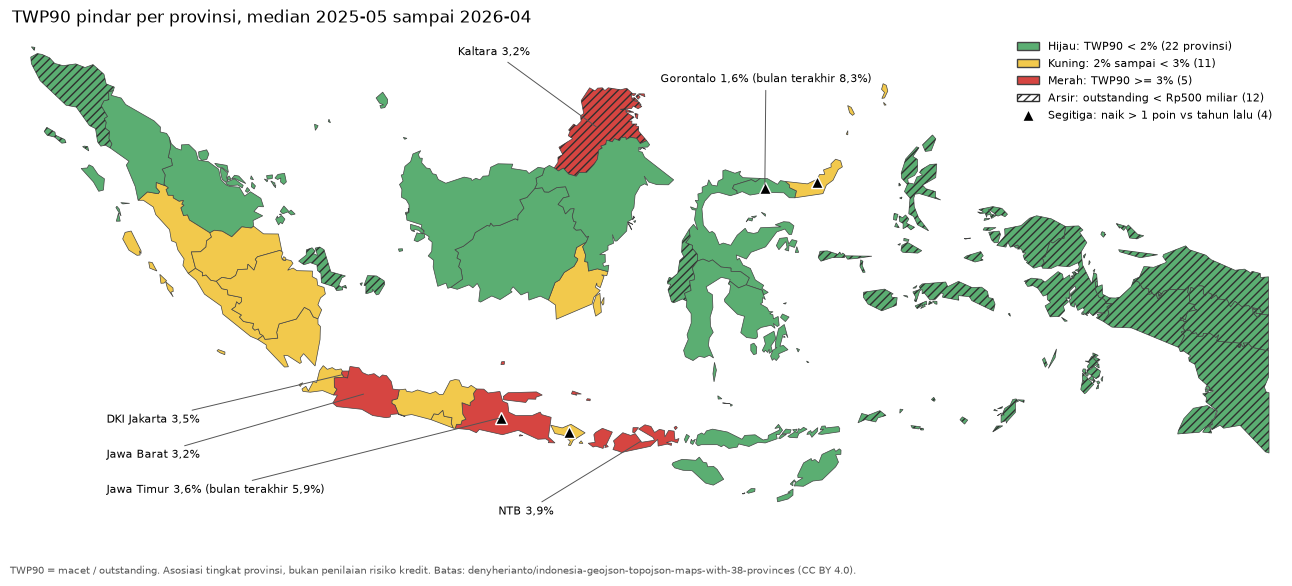

drawn_provinces=38 | labels={'hijau': 22, 'kuning': 11, 'merah': 5} | hatched=12 | triangles=4


In [46]:
# Cell 46 - Static map: risk labels, low-volume hatching, rising markers
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

RISK_COLORS = {"hijau": "#5BAE72", "kuning": "#F2C94C", "merah": "#D64541"}
LON0, LON1, LAT0, LAT1 = 94.5, 141.5, -12.0, 6.5
LABEL_OFFSETS = {
    "DKI Jakarta": (98.0, -8.0),
    "Jawa Barat": (98.0, -9.3),
    "Jawa Timur": (98.0, -10.6),
    "Nusa Tenggara Barat": (112.5, -11.4),
    "Kalimantan Utara": (111.0, 5.6),
    "Gorontalo": (118.5, 4.6),
}
SHORT_NAMES = {"DKI Jakarta": "DKI Jakarta", "Nusa Tenggara Barat": "NTB", "Kalimantan Utara": "Kaltara"}


def fmt_id(value, digits=1):
    return f"{value:.{digits}f}".replace(".", ",")


fig_risk, ax = plt.subplots(figsize=(13, 5.8))
for name, row in map_df.iterrows():
    for poly in row["polys"]:
        ax.add_patch(mpatches.Polygon(poly[0], closed=True, facecolor=RISK_COLORS[row["risk_label"]], edgecolor="#444444", linewidth=0.5))
        if row["low_volume"]:
            ax.add_patch(mpatches.Polygon(poly[0], closed=True, facecolor="none", edgecolor="#2f2f2f", hatch="////", linewidth=0))
    if row["rising"]:
        ax.plot(row["cx"], row["cy"], marker="^", color="black", markeredgecolor="white", markersize=8, linestyle="none")
for name, (tx, ty) in LABEL_OFFSETS.items():
    row = map_df.loc[name]
    text = f"{SHORT_NAMES.get(name, name)} {fmt_id(row['twp90_median_12m'])}%"
    if row["rising"]:
        text += f" (bulan terakhir {fmt_id(row['twp90_latest'])}%)"
    ax.annotate(text, xy=(row["cx"], row["cy"]), xytext=(tx, ty), fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "#555555", "linewidth": 0.7})
ax.set_xlim(LON0, LON1)
ax.set_ylim(LAT0, LAT1)
ax.set_aspect("equal")
ax.axis("off")

n_lab = map_df["risk_label"].value_counts()
handles = [
    mpatches.Patch(facecolor=RISK_COLORS["hijau"], edgecolor="#444444", label=f"Hijau: TWP90 < {RISK_LOW:g}% ({n_lab.get('hijau', 0)} provinsi)"),
    mpatches.Patch(facecolor=RISK_COLORS["kuning"], edgecolor="#444444", label=f"Kuning: {RISK_LOW:g}% sampai < {RISK_HIGH:g}% ({n_lab.get('kuning', 0)})"),
    mpatches.Patch(facecolor=RISK_COLORS["merah"], edgecolor="#444444", label=f"Merah: TWP90 >= {RISK_HIGH:g}% ({n_lab.get('merah', 0)})"),
    mpatches.Patch(facecolor="white", edgecolor="#2f2f2f", hatch="////", label=f"Arsir: outstanding < Rp{LOW_VOLUME_MILIAR:g} miliar ({int(map_df['low_volume'].sum())})"),
    Line2D([0], [0], marker="^", color="black", markeredgecolor="white", linestyle="none", markersize=8, label=f"Segitiga: naik > {RISING_PP:g} poin vs tahun lalu ({int(map_df['rising'].sum())})"),
]
ax.legend(handles=handles, loc="upper right", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=8)
ax.set_title(f"TWP90 pindar per provinsi, median {recent_12['date'].min():%Y-%m} sampai {last_month:%Y-%m}", fontsize=12, loc="left")
fig_risk.text(0.01, 0.01, "TWP90 = macet / outstanding. Asosiasi tingkat provinsi, bukan penilaian risiko kredit. Batas: denyherianto/indonesia-geojson-topojson-maps-with-38-provinces (CC BY 4.0).", fontsize=7, color="#555555")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()
print(f"drawn_provinces={len(map_df)} | labels={n_lab.reindex(['hijau', 'kuning', 'merah']).to_dict()} | hatched={int(map_df['low_volume'].sum())} | triangles={int(map_df['rising'].sum())}")


### J.4 Peta interaktif
Satu berkas HTML mandiri (tanpa pustaka luar atau koneksi internet) dengan tooltip saat kursor diarahkan ke provinsi.

In [47]:
# Cell 47 - Interactive map: self-contained HTML with hover tooltips
import html as html_lib

SCALE = 24.0
SVG_W, SVG_H = (LON1 - LON0) * SCALE, (LAT1 - LAT0) * SCALE


def to_xy(lon, lat):
    return (lon - LON0) * SCALE, (LAT1 - lat) * SCALE


def svg_path(polys):
    parts = []
    for poly in polys:
        pts = [to_xy(lon, lat) for lon, lat in poly[0]]
        parts.append("M" + " L".join(f"{x:.1f},{y:.1f}" for x, y in pts) + " Z")
    return " ".join(parts)


paths, hatches, marks = [], [], []
for name, row in map_df.iterrows():
    d = svg_path(row["polys"])
    tip = "|".join([
        html_lib.escape(name), row["risk_label"], fmt_id(row["twp90_median_12m"]), fmt_id(row["twp90_latest"]),
        f"{row['change_vs_year_ago_pp']:+.1f}".replace(".", ","), f"{row['outstanding_latest_miliar']:,.0f}".replace(",", "."),
        "ya" if row["low_volume"] else "tidak", "ya" if row["rising"] else "tidak",
    ])
    paths.append(f'<path class="prov" d="{d}" fill="{RISK_COLORS[row["risk_label"]]}" data-tip="{tip}"/>')
    if row["low_volume"]:
        hatches.append(f'<path d="{d}" fill="url(#hatch)" pointer-events="none"/>')
    if row["rising"]:
        x, y = to_xy(row["cx"], row["cy"])
        marks.append(f'<polygon points="{x:.1f},{y - 7:.1f} {x - 6:.1f},{y + 5:.1f} {x + 6:.1f},{y + 5:.1f}" fill="#000" stroke="#fff" stroke-width="1" pointer-events="none"/>')

HTML_TEMPLATE = """<!DOCTYPE html>
<html lang="id"><head><meta charset="utf-8"><title>Peta TWP90 pindar per provinsi</title>
<style>
body{font-family:Segoe UI,Arial,sans-serif;margin:16px;color:#222;max-width:1150px}
h1{font-size:20px;margin:0 0 4px} p.sub{margin:0 0 10px;color:#555;font-size:13px}
.legend{display:flex;flex-wrap:wrap;gap:14px;font-size:13px;margin:8px 0}
.legend span.sw{display:inline-block;width:14px;height:14px;border:1px solid #444;vertical-align:-2px;margin-right:5px}
svg{width:100%;height:auto;background:#f4f7fa;border:1px solid #d5dde5}
.prov{stroke:#444;stroke-width:.6;cursor:pointer} .prov:hover{stroke:#000;stroke-width:1.8}
#tip{position:absolute;display:none;background:#fff;border:1px solid #888;padding:8px 10px;font-size:12.5px;line-height:1.45;box-shadow:0 2px 6px rgba(0,0,0,.2);pointer-events:none}
.note{font-size:12px;color:#555;margin-top:8px}
</style></head><body>
<h1>TWP90 pindar per provinsi</h1>
<p class="sub">Median __WINDOW__. Arahkan kursor ke provinsi untuk melihat angka.</p>
<div class="legend">__LEGEND__</div>
<svg viewBox="0 0 __W__ __H__" xmlns="http://www.w3.org/2000/svg">
<defs><pattern id="hatch" width="6" height="6" patternUnits="userSpaceOnUse" patternTransform="rotate(45)"><line x1="0" y1="0" x2="0" y2="6" stroke="#2f2f2f" stroke-width="1.6"/></pattern></defs>
__PATHS__
__HATCHES__
__MARKS__
</svg>
<div id="tip"></div>
<p class="note">TWP90 = macet / outstanding. Peta ini menunjukkan asosiasi tingkat provinsi, bukan penilaian risiko kredit. Hijau tidak berarti aman: banyak provinsi hijau berportofolio kecil dan muda. Batas provinsi: denyherianto/indonesia-geojson-topojson-maps-with-38-provinces (CC BY 4.0).</p>
<script>
var tip = document.getElementById('tip');
document.querySelectorAll('.prov').forEach(function (p) {
  p.addEventListener('mousemove', function (e) {
    var f = p.getAttribute('data-tip').split('|');
    var flags = [];
    if (f[6] === 'ya') flags.push('portofolio kecil');
    if (f[7] === 'ya') flags.push('naik cepat');
    tip.innerHTML = '<b>' + f[0] + '</b><br>Label: ' + f[1] +
      '<br>TWP90 median 12 bulan: ' + f[2] + '%' +
      '<br>TWP90 bulan terakhir: ' + f[3] + '%' +
      '<br>Beda vs tahun lalu: ' + f[4] + ' poin' +
      '<br>Outstanding: Rp' + f[5] + ' miliar' +
      (flags.length ? '<br><i>' + flags.join(', ') + '</i>' : '');
    tip.style.display = 'block';
    tip.style.left = (e.pageX + 14) + 'px';
    tip.style.top = (e.pageY + 14) + 'px';
  });
  p.addEventListener('mouseleave', function () { tip.style.display = 'none'; });
});
</script>
</body></html>"""

legend_items = [
    f'<span><span class="sw" style="background:{RISK_COLORS["hijau"]}"></span>Hijau: TWP90 &lt; {RISK_LOW:g}% ({n_lab.get("hijau", 0)})</span>',
    f'<span><span class="sw" style="background:{RISK_COLORS["kuning"]}"></span>Kuning: {RISK_LOW:g}% sampai &lt; {RISK_HIGH:g}% ({n_lab.get("kuning", 0)})</span>',
    f'<span><span class="sw" style="background:{RISK_COLORS["merah"]}"></span>Merah: &ge; {RISK_HIGH:g}% ({n_lab.get("merah", 0)})</span>',
    f'<span>Arsir: outstanding &lt; Rp{LOW_VOLUME_MILIAR:g} miliar ({int(map_df["low_volume"].sum())})</span>',
    f'<span>&#9650; Naik &gt; {RISING_PP:g} poin vs tahun lalu ({int(map_df["rising"].sum())})</span>',
]
html_doc = (HTML_TEMPLATE
            .replace("__WINDOW__", f"{recent_12['date'].min():%Y-%m} sampai {last_month:%Y-%m}")
            .replace("__LEGEND__", "".join(legend_items))
            .replace("__W__", f"{SVG_W:.0f}").replace("__H__", f"{SVG_H:.0f}")
            .replace("__PATHS__", "\n".join(paths)).replace("__HATCHES__", "\n".join(hatches)).replace("__MARKS__", "\n".join(marks)))
print(f"html_chars={len(html_doc)} | provinces={len(paths)} | hatched={len(hatches)} | markers={len(marks)} | external_requests={html_doc.count('http://') + html_doc.count('https://') - html_doc.count('www.w3.org')}")


html_chars=57540 | provinces=38 | hatched=12 | markers=4 | external_requests=0


### J.5 Ekspor
Label per provinsi (CSV), gambar PNG, dan HTML interaktif disimpan di `artifacts/`.

In [48]:
# Cell 48 - Export risk labels, static map, and interactive map
risk.reset_index().round(3).to_csv(ART_DIR / "province_risk_labels.csv", index=False)
fig_risk.savefig(ART_DIR / "map_twp90_risk.png", dpi=200, bbox_inches="tight")
(ART_DIR / "map_twp90_risk.html").write_text(html_doc, encoding="utf-8")
for fname in ["province_risk_labels.csv", "map_twp90_risk.png", "map_twp90_risk.html"]:
    print(f"file={fname} | kb={(ART_DIR / fname).stat().st_size / 1024:.1f}")


file=province_risk_labels.csv | kb=2.5
file=map_twp90_risk.png | kb=391.6
file=map_twp90_risk.html | kb=56.3
